# **Predict Customer Clicked Ads Classification By Using Machine Learning**

## 📌 Problem Statement

A digital marketing company in Indonesia faces challenges in determining the effectiveness of their advertisements and identifying the right target audience. The current approach lacks precision in reaching potential customers who are likely to engage with the ads, resulting in inefficient ad spending and lower click-through rates. This leads to reduced return on investment (ROI) on their advertising campaigns and potential loss of market opportunities.

## 📌 Goals

- Enhanced ad targeting: Improve advertisement effectiveness by implementing machine learning models to identify potential customers most likely to click on ads. (**MAIN**)
- Increased ROI: Optimize advertising spend by targeting the most receptive audience segments. (**SECONDARY**)

## 📌 Objectives

The ultimate goal of this project is to create a machine learning model that can:

- Accurately predict which users are most likely to click on advertisements, with high precision and accuracy rates
- Identify patterns in customer behavior to optimize ad targeting strategies
- Reduce advertising costs while maintaining or improving engagement rates

## 📌 Business Metrics

* Click-Through Rate (CTR): The percentage of users who click on the advertisement divided by the total number of users who view the ad. (**MAIN**)
* Return on Ad Spend (ROAS): The revenue generated per rupiah spent on advertising. (**MAIN**)

# **STAGE 1 : EXPLORATORY DATA ANALYSIS (EDA)**

## Import Libraries and Settings

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

import warnings
warnings.filterwarnings('ignore')

# Settings
sns.set_style('darkgrid')
pd.set_option('display.max_columns', None)

# Set random seed for all numpy random generation methods
np.random.seed(42)

### Load Dataset

In [2]:
# Load dataset
df_raw = pd.read_csv('data/clicked_ads_dataset.csv', index_col=0)

# Create a copy of the dataframe
df = df_raw.copy()

## Data Understanding and Initial Transformation

In [3]:
# Retrieve 10 sample lines from the available data
df.sample(10)

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Timestamp,Clicked on Ad,city,province,category
521,63.26,29,383511590.0,120.46,Laki-Laki,3/2/2016 4:02,Yes,Medan,Sumatra Utara,Health
737,71.23,52,290648960.0,122.59,Perempuan,1/5/2016 11:53,Yes,Bogor,Jawa Barat,House
740,43.63,38,432299840.0,135.25,Laki-Laki,5/25/2016 19:45,Yes,Bekasi,Jawa Barat,Bank
660,42.04,49,471261000.0,182.11,Perempuan,2/3/2016 16:54,Yes,Banjarmasin,Kalimantan Selatan,Finance
411,78.68,29,463580040.0,208.05,Perempuan,1/16/2016 16:40,No,Malang,Jawa Timur,Otomotif
678,87.85,34,362713890.0,153.01,Perempuan,3/19/2016 8:00,No,Medan,Sumatra Utara,Electronic
626,85.77,27,365832110.0,191.78,Laki-Laki,4/9/2016 23:26,No,Malang,Jawa Timur,Health
513,59.13,44,346677590.0,106.04,Laki-Laki,6/9/2016 17:11,Yes,Pakanbaru,Riau,Bank
859,83.17,43,379762460.0,244.40,Laki-Laki,4/5/2016 18:02,No,Malang,Jawa Timur,Otomotif
136,38.37,36,288604120.0,140.46,Perempuan,5/13/2016 6:09,Yes,Jakarta Timur,Daerah Khusus Ibukota Jakarta,Finance


In [4]:
# Checking shape of dataframe
print(f'Number of rows: {df.shape[0]}')
print(f'Number of columns {df.shape[1]}')

Number of rows: 1000
Number of columns 10


In [5]:
# Quick feature transformation
## Rename column name for and maintain column name similarity
df = df.rename(columns={'Male': 'Gender',
                        'Timestamp': 'Visit Time',
                        'city' : 'City',
                        'province' : 'Province',
                        'category' : 'Category'})

## Re-arrange column (target 'Clicked on Ad' at the end --> personal preference)
df = df[[col for col in df.columns if col != 'Clicked on Ad'] + ['Clicked on Ad']]

In [6]:
# Check data information
from utils import check_data_information

info_df = check_data_information(df, df.columns.tolist())
display(info_df)

,Feature,Data Type,Null Values,Null Percentage,Zero Values,Zero Percentage,Negative Values,Negative Percentage,Empty Strings,Numeric in Object,Duplicated Values,Unique Values,Cardinality Ratio,Unique Sample
0,Daily Time Spent on Site,float64,13,1.3,0,0.0,0,0.0,0,0,0,890,0.890,"68.95, 80.23, 69.47, 74.15, 68.37"
1,Age,int64,0,0.0,0,0.0,0,0.0,0,0,0,43,0.043,"35, 31, 26, 29, 23"
2,Area Income,float64,13,1.3,0,0.0,0,0.0,0,0,0,987,0.987,"432837300.0, 479092950.00000006, 418501580.0, ..."
3,Daily Internet Usage,float64,11,1.1,0,0.0,0,0.0,0,0,0,955,0.955,"256.09, 193.77, 236.5, 245.89, 225.58"
4,Gender,object,3,0.3,0,0.0,0,0.0,0,0,0,2,0.002,"Perempuan, Laki-Laki, nan"
5,Visit Time,object,0,0.0,0,0.0,0,0.0,0,0,0,997,0.997,"3/27/2016 0:53, 4/4/2016 1:39, 3/13/2016 20:35..."
6,City,object,0,0.0,0,0.0,0,0.0,0,0,0,30,0.030,"Jakarta Timur, Denpasar, Surabaya, Batam, Medan"
7,Province,object,0,0.0,0,0.0,0,0.0,0,0,0,16,0.016,"Daerah Khusus Ibukota Jakarta, Bali, Jawa Timu..."
8,Category,object,0,0.0,0,0.0,0,0.0,0,0,0,10,0.010,"Furniture, Food, Electronic, House, Finance"
9,Clicked on Ad,object,0,0.0,0,0.0,0,0.0,0,0,0,2,0.002,"No, Yes"


**Quick Overview:**
- Dataset contains 1000 rows, 10 features and 1 **Unnamed: 0** column which is the ID column that is dropped at the beginning.
- Dataset consists of 3 data types; float64, int64 and object.
- `Visit Time` (originally `Timestampt`) feature will be changed into datetime data type.
- Dataset contains null values in various columns but with only small percentages.

**Feature Information**

| **Feature Name** | **Description** | **Data Type** | **Specific Data Type** |
|------------------|-----------------|---------------|----------------------|
| `Daily Time Spent on Site` | Time spent on the site (Minutes) | Numerical | Continuous |
| `Age` | Age of the customer | Numerical | Continuous |
| `Area Income` | Average income of geographical area of consumer | Numerical | Continuous |
| `Daily Internet Usage` | Time spent on the internet (Minutes) | Numerical | Continuous |
| `Gender` | Gender of the customer | Categorical | Nominal |
| `Visit Time` | Time the customer visit on the website | Date | Timestamp |
| `City` | City of customer's residence | Categorical | Nominal |
| `Province` | Province of customer's residence | Categorical | Nominal |
| `Category` | Category of the advertisement | Categorical | Nominal |
| `Clicked on Ad` | Whether the customer clicked the ad or not (Target Variable) | Categorical | Nominal (Binary) |

In [7]:
# Grouping columns based on data types
nums_cols = ['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage']

cats_cols = ['Gender', 'City', 'Province', 'Category', 'Clicked on Ad']

date_cols = ['Visit Time']

## Initial Transformation

- We saw that from our quick data understanding that we have a really small amount of missing values (~1%). Since the amount is very small, we can just handle it here and not in preprocessing steps. We also had the options to just drop it but we will just go with imputation for now

- We also saw that the `Visit Time` column need to be handled by changing the data type from string to datetime, we can also do it here since we could potentially gather insights related to datetime 

In [8]:
# Define target value mappings
TARGET_MAPPINGS = {
    'to_label': {'No': 'Not Clicked', 'Yes': 'Clicked'},
    'to_numeric': {'Not Clicked': 0, 'Clicked': 1},
    'to_categorical': {0: 'Not Clicked', 1: 'Clicked'}
}

# Transform target values to readable labels (idempotent - safe to run multiple times)
if df['Clicked on Ad'].dtype == 'object' and df['Clicked on Ad'].isin(['Yes', 'No']).any():
    df['Clicked on Ad'] = df['Clicked on Ad'].map(TARGET_MAPPINGS['to_label'])


def change_target_dtype(data, target_col='Clicked on Ad', target_type='numerical'):
    """
    Change the target feature's data type between numerical and categorical.

    Parameters:
    -----------
    data : pd.DataFrame
        The dataframe containing the target column.
    target_col : str
        The name of the target column.
    target_type : str
        The desired data type: 'numerical' (0/1) or 'categorical' ('Not Clicked'/'Clicked').

    Returns:
    --------
    pd.DataFrame
        The dataframe with the modified target column (modified in place).
    """
    mapping = {
        'categorical': TARGET_MAPPINGS['to_categorical'],
        'numerical': TARGET_MAPPINGS['to_numeric']
    }
    
    if target_type not in mapping:
        raise ValueError("target_type must be either 'numerical' or 'categorical'")
    
    data[target_col] = data[target_col].map(mapping[target_type])
    return data

In [9]:
# Data type correction for `Visit Time` column
df['Visit Time'] = pd.to_datetime(df['Visit Time'])

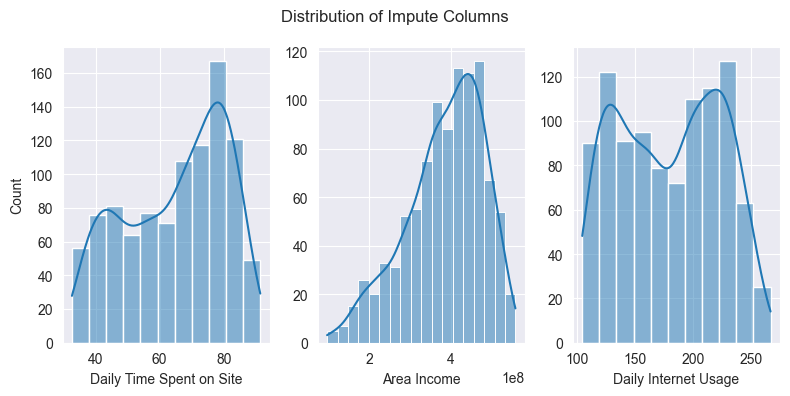

In [10]:
# Checking distribution in numerical columns with missing value for proper imputation method
impute_col = ['Daily Time Spent on Site', 'Area Income', 'Daily Internet Usage']

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(8, 4))

# Plot histograms for each column
for i, col in enumerate(impute_col):
    sns.histplot(data=df, x=col, kde=True, ax=ax[i])
    if i != 0:
        ax[i].set_ylabel(None)

plt.suptitle('Distribution of Impute Columns')
plt.tight_layout()
plt.show()

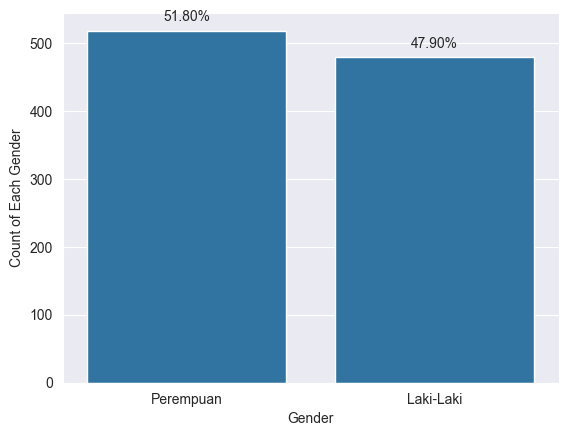

In [11]:
# Checking distribution in categorical columns with missing value for proper imputation method
ax = sns.countplot(data=df, x='Gender')

# Calculate the percentage for each category
total = float(len(df))
for p in ax.patches:
    percentage = '{:.2f}%'.format((p.get_height() / total) * 100)
    ax.annotate(percentage, # The text to display
                (p.get_x() + p.get_width() / 2., p.get_height()), # The position to annotate
                ha='center', va='bottom', # Alignment of text
                xytext=(0, 5), textcoords='offset points')  # The distance from text to points
plt.ylabel('Count of Each Gender')
plt.show()

> Imputation method based on distribution :

- Daily Time Spent on Site and Daily Internet Usage : mean
- Area Income : median
- Gender : mode

In [12]:
# Impute missing values
df['Daily Time Spent on Site'] = df['Daily Time Spent on Site'].fillna(df['Daily Time Spent on Site'].mean())
df['Daily Internet Usage'] = df['Daily Internet Usage'].fillna(df['Daily Internet Usage'].mean())
df['Area Income'] = df['Area Income'].fillna(df['Area Income'].median())
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])

---

## Univariate Analysis

### Numerical Columns

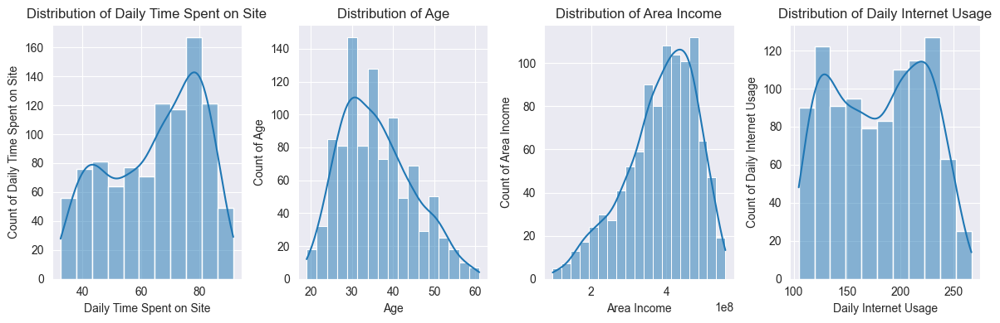

Statistical Summary:


,Feature,overall_count,overall_mean,overall_std,overall_min,overall_25%,overall_50%,overall_75%,overall_max,overall_range,overall_IQR,overall_CV,overall_skewness,overall_kurtosis
0,Daily Time Spent on Site,1000.0,6.492952e+01,1.574127e+01,32.60,5.154500e+01,6.778000e+01,7.835250e+01,9.143000e+01,5.883000e+01,2.680750e+01,24.243622,-0.371617,-1.074387
1,Age,1000.0,3.600900e+01,8.785562e+00,19.00,2.900000e+01,3.500000e+01,4.200000e+01,6.100000e+01,4.200000e+01,1.300000e+01,24.398240,0.478423,-0.404518
2,Area Income,1000.0,3.850493e+08,9.347971e+07,97975500.00,3.298201e+08,3.990683e+08,4.566932e+08,5.563936e+08,4.584181e+08,1.268731e+08,24.277335,-0.653140,-0.079298
3,Daily Internet Usage,1000.0,1.798636e+02,4.362795e+01,104.78,1.390175e+02,1.810650e+02,2.182875e+02,2.670100e+02,1.622300e+02,7.927000e+01,24.256126,-0.031521,-1.257858


Distribution Types:


,Column Name,Mean,Median,Mode,Skewness,Kurtosis,Skewness Type,Kurtosis Type
0,Daily Time Spent on Site,6.493000e+01,6.778000e+01,6.493000e+01,-0.372,-1.074,Slightly Negatively Skewed,Platykurtic (Light-tailed)
1,Age,3.600900e+01,3.500000e+01,3.100000e+01,0.478,-0.405,Slightly Positively Skewed,Mesokurtic (Normal-like)
2,Area Income,3.850493e+08,3.990683e+08,3.990683e+08,-0.653,-0.079,Moderately Negatively Skewed,Mesokurtic (Normal-like)
3,Daily Internet Usage,1.798640e+02,1.810650e+02,1.798640e+02,-0.032,-1.258,Normal Distribution (Symmetric),Platykurtic (Light-tailed)


In [13]:
# Checking the distribution and statistical summary of the numerical values
from utils import plot_dynamic_hisplots_kdeplots, describe_numerical_combined, identify_distribution_types
plot_dynamic_hisplots_kdeplots(df=df, col_series=nums_cols, ncols=4, figsize=(12, 4))

# Display the overall statistics for numerical columns
numerical_summary = describe_numerical_combined(df, nums_cols)
print("Statistical Summary:")
display(numerical_summary)

# Check the distribution type
result = identify_distribution_types(df, nums_cols)
print("Distribution Types:")
display(result)

Gentle reminder :

- `skewness`: Measures the asymmetry of the probability distribution
- `kurtosis`: Measures the "tailedness" of the probability distribution

The skewness and kurtosis values can help you understand:
- If skewness > 0: Right-skewed distribution
- If skewness < 0: Left-skewed distribution
- If kurtosis > 3: Heavy-tailed distribution (more outliers)
- If kurtosis < 3: Light-tailed distribution (fewer outliers)


Distribution types of each numerical column can be seen in above dataframe, that is almost all of them are categorized as normal distribution. 

Amount of Rows: 1000
Amount of Outlier Rows (Across All Columns): 9
Amount of Non-Outlier Rows (Across All Columns): 991
Percentage of Outliers: 0.9%



,Column Name,Outlier Exist,Lower Limit,Upper Limit,Outlier Data,Non-Outlier Data,Outlier Percentage (%)
0,Daily Time Spent on Site,False,1.133375e+01,1.185637e+02,0,1000,0.0
1,Age,False,9.500000e+00,6.150000e+01,0,1000,0.0
2,Area Income,True,1.395105e+08,6.470028e+08,9,991,0.9
3,Daily Internet Usage,False,2.011250e+01,3.371925e+02,0,1000,0.0


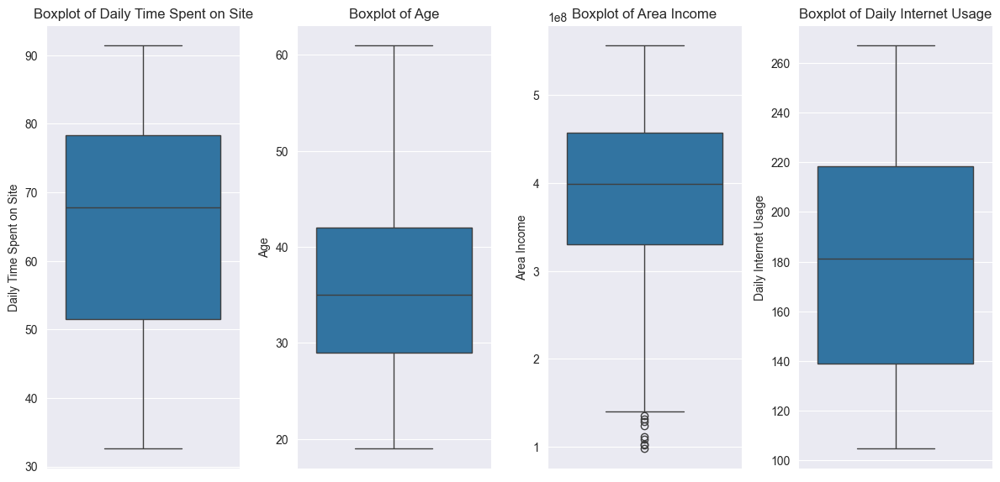

In [14]:
from utils import filter_outliers, plot_dynamic_boxplots_violinplots

# Check outliers
summary = filter_outliers(df, columns=nums_cols, threshold=1.5, detect_only=True)
display(summary)

# Visualize outliers
plot_dynamic_boxplots_violinplots(df, nums_cols, plot_type="boxplot", ncols=4, orientation="v", figsize=(12, 6))

There are several outliers here in the `Area Income` column, we will handle that later in the preprocessing steps after we gather some insights first, since monetary values information is quite important.

**Major Findings :**

- The distribution of our customer's `Daily Time Spent on Site`, `Age`, and `Area Income` are moderately normal distribution while `Daily Internet Usage` is uniform distribution.
 
- Based on the distribution, our customers usually spent around 1 hour per day on our site, have an average of age of 36, the median area income of our customers is Rp.38,000,000, and their average daily internet usage is 3 hours.

---

### Categorical Columns

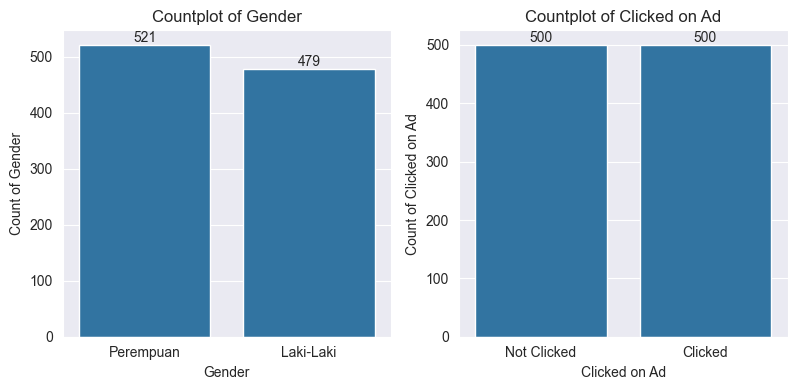

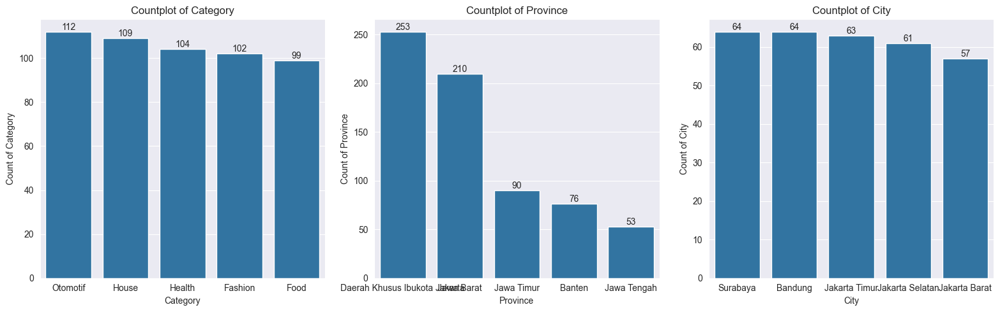

,Feature,overall_count,overall_unique,overall_top,overall_freq,overall_bottom,overall_freq_bottom,overall_top_percentage,overall_bottom_percentage,overall_n_categories
0,Gender,1000,2,Perempuan,521,Laki-Laki,479,52.1,47.9,2
1,City,1000,30,Surabaya,64,Serang,11,6.4,1.1,30
2,Province,1000,16,Daerah Khusus Ibukota Jakarta,253,Kalimantan Barat,12,25.3,1.2,16
3,Category,1000,10,Otomotif,112,Bank,90,11.2,9.0,10
4,Clicked on Ad,1000,2,Not Clicked,500,Not Clicked,500,50.0,50.0,2


In [15]:
# Checking the distribution and statistical summary of the categorical values
from utils import describe_categorical_combined, plot_dynamic_countplot

# Countplot function implementation
cats_cols_few = ['Gender', 'Clicked on Ad']
cats_cols_many = ['Category', 'Province', 'City']

# Plot for Gender and target
plot_dynamic_countplot(df=df, col_series=cats_cols_few, ncols=4, figsize=(16, 4))

# Plot for the rest of categorical columns
plot_dynamic_countplot(df=df, col_series=cats_cols_many, ncols=4, figsize=(21, 5), order=[df[cat].value_counts().iloc[:5].index.tolist() for cat in cats_cols_many])

# Display the overall statistics for categorical columns
categorical_summary = describe_categorical_combined(df, cats_cols)
display(categorical_summary)

We will analyze this further later, but one thing to notice here is that our target variable is perfectly balanced. So, currently our **Click-Through Rate is only 50%** and we want to improve that further. Also this perfectly balanced values give us information that we won't need to do resampling later for modelling.

**Major Findings:**

- The distribution of male and female `Gender` is almost equal
- `Province` has 2 dominant values: DKI Jakarta and Jawa Barat.
- `Category` is almost equally distributed among the all the values.

### Date Columns

In [16]:
# Date function analysis
from utils import describe_date_columns
describe_date_columns(df, date_cols)

,count,mean,min,25%,50%,75%,max,date_range_days,date_range_months,date_range_years,unique_years,unique_months,unique_days,weekend_percentage,business_hours_percentage,most_common_month,most_common_weekday,max_gap_days,median_gap_days,future_dates_percentage,is_regular_interval
Visit Time,1000,2016-04-10 10:33:36.840000,2016-01-01 02:52:00,2016-02-18 02:55:15,2016-04-07 17:27:00,2016-05-31 03:18:00,2016-07-24 00:22:00,204 days 21:30:00,6.8,0.558904,1.0,7.0,203.0,28.5,35.8,2.0,Sunday,1.0,0.0,0.0,True


The data extracted for analysis are only around 6 months, nearly 7, weekend percentage is onyl 28.5%, etc.

---

## Bivariate Analysis

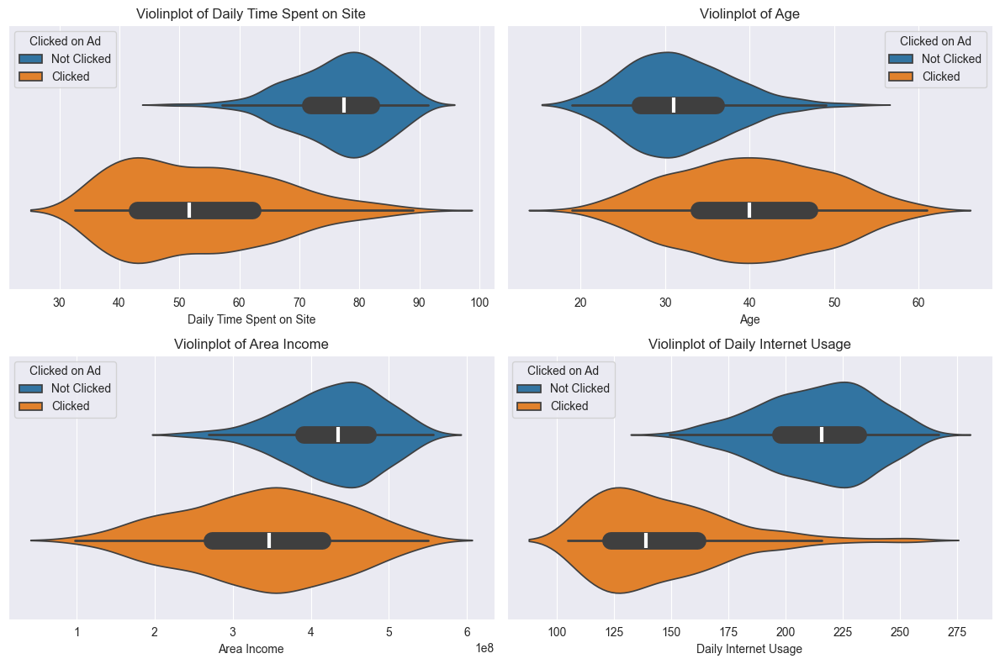

,Feature,overall_count,class_Clicked_count,class_Not Clicked_count,overall_mean,class_Clicked_mean,class_Not Clicked_mean,overall_std,class_Clicked_std,class_Not Clicked_std,overall_min,class_Clicked_min,class_Not Clicked_min,overall_25%,class_Clicked_25%,class_Not Clicked_25%,overall_50%,class_Clicked_50%,class_Not Clicked_50%,overall_75%,class_Clicked_75%,class_Not Clicked_75%,overall_max,class_Clicked_max,class_Not Clicked_max,overall_range,class_Clicked_range,class_Not Clicked_range,overall_IQR,class_Clicked_IQR,class_Not Clicked_IQR,overall_CV,class_Clicked_CV,class_Not Clicked_CV,overall_skewness,class_Clicked_skewness,class_Not Clicked_skewness,overall_kurtosis,class_Clicked_kurtosis,class_Not Clicked_kurtosis
0,Daily Time Spent on Site,1000.0,500.0,500.0,6.492952e+01,5.326098e+01,7.659807e+01,1.574127e+01,1.283706e+01,7.643672e+00,32.60,32.60,4.822000e+01,5.154500e+01,4.291500e+01,7.182000e+01,6.778000e+01,5.163000e+01,7.745500e+01,7.835250e+01,6.221500e+01,8.198250e+01,9.143000e+01,9.137000e+01,9.143000e+01,5.883000e+01,5.877000e+01,4.321000e+01,2.680750e+01,1.930000e+01,1.016250e+01,24.243622,24.102189,9.978935,-0.371617,0.512533,-0.583254,-1.074387,-0.468200,0.241294
1,Age,1000.0,500.0,500.0,3.600900e+01,4.033400e+01,3.168400e+01,8.785562e+00,8.856598e+00,6.212998e+00,19.00,19.00,1.900000e+01,2.900000e+01,3.400000e+01,2.700000e+01,3.500000e+01,4.000000e+01,3.100000e+01,4.200000e+01,4.700000e+01,3.600000e+01,6.100000e+01,6.100000e+01,5.300000e+01,4.200000e+01,4.200000e+01,3.400000e+01,1.300000e+01,1.300000e+01,9.000000e+00,24.398240,21.958144,19.609261,0.478423,0.025159,0.479261,-0.404518,-0.696622,0.113343
2,Area Income,1000.0,500.0,500.0,3.850493e+08,3.406831e+08,4.294155e+08,9.347971e+07,9.841556e+07,6.216260e+07,97975500.00,97975500.00,2.326744e+08,3.298201e+08,2.739265e+08,3.910686e+08,3.990683e+08,3.469286e+08,4.352817e+08,4.566932e+08,4.141765e+08,4.725904e+08,5.563936e+08,5.496469e+08,5.563936e+08,4.584181e+08,4.516714e+08,3.237192e+08,1.268731e+08,1.402500e+08,8.152176e+07,24.277335,28.887716,14.476094,-0.653140,-0.182054,-0.497589,-0.079298,-0.615408,0.048822
3,Daily Internet Usage,1000.0,500.0,500.0,1.798636e+02,1.456182e+02,2.141090e+02,4.362795e+01,2.962363e+01,2.414247e+01,104.78,104.78,1.461900e+02,1.390175e+02,1.236350e+02,1.977800e+02,1.810650e+02,1.390150e+02,2.160150e+02,2.182875e+02,1.613625e+02,2.316550e+02,2.670100e+02,2.586200e+02,2.670100e+02,1.622300e+02,1.538400e+02,1.208200e+02,7.927000e+01,3.772750e+01,3.387500e+01,24.256126,20.343351,11.275787,-0.031521,1.140087,-0.325094,-1.257858,1.450243,-0.485721


In [17]:
# # Boxplot with hue target
# plot_dynamic_boxplots_violinplots(df, col_series=nums_cols, 
#                                   plot_type='boxplot', ncols=2, figsize=(8, 12),
#                                   orientation='h',
#                                   hue='Clicked on Ad')

# # Kdeplot with hue target
# plot_dynamic_hisplots_kdeplots(df, col_series=nums_cols, 
#                                plot_type='kdeplot', ncols=2, 
#                                figsize=(14, 8),
#                                hue='Clicked on Ad', fill=True)

# Violinplot with hue target (combination of both of them)
plot_dynamic_boxplots_violinplots(df, col_series=nums_cols, 
                                  plot_type='violinplot', ncols=2, figsize=(8, 12),
                                  orientation='h',
                                  hue='Clicked on Ad')

# Get better understanding of the data through descriptive statistics with hue target
describe_numerical_combined(df, nums_cols, hue='Clicked on Ad')

**Major Findings (Check the statistics):**

- The more time customers spent time on the site, the less likely they will click on an ad.

- The average age of customers that clicked on an ad is 40, while the average for those that didn't is 31.

- The median income of customers that clicked on an ad is considerably lower than those that didn't.

- The more time customers use the internet daily, the less likely they wil click on an ad.

In [18]:
# Regplot analysis
def plot_dynamic_regplots(df, x_col, col_series, hue=None, ncols=3, figsize=(18, 6)):
    """
    Create multiple regression plots with R-squared values and equations.
    
    Args:
        df (pandas.DataFrame): Input dataframe
        x_col (str): Column name for x-axis
        col_series (list): List of column names for y-axis
        hue (str, optional): Column name for color grouping
        ncols (int): Number of columns in subplot grid
        figsize (tuple): Figure size (width, height)
    """
    if df is None or df.empty or not col_series:
        raise ValueError("DataFrame and column list cannot be empty")

    # Calculate R-squared value and regression equation (for display purpose only)
    def calculate_r_squared(x, y):
        slope, intercept = np.polyfit(x, y, 1)
        y_pred = slope * x + intercept
        ss_residual = np.sum((y - y_pred) ** 2)
        ss_total = np.sum((y - np.mean(y)) ** 2)
        return 1 - (ss_residual / ss_total), slope, intercept

    # Calculate required number of rows based on number of plots and specified columns
    num_plots = len(col_series)
    nrows = math.ceil(num_plots / ncols)

    fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize)
    
    # If only one plot, ax is not an array
    if num_plots == 1:
        ax = [ax]
    else:
        ax = ax.flatten()

    # Generate plots for each column
    for i, col in enumerate(col_series):
        # Regression plot
        sns.regplot(data=df, ax=ax[i], x=x_col, y=col, scatter_kws={'s':20, 'alpha':0.4}, line_kws={'color':'red'}, ci=False)

        # Scatterplot
        sns.scatterplot(data=df, ax=ax[i], x=x_col, y=col, hue=hue)

        # Calculating and displaying R-squared
        x = df[x_col]
        y = df[col]
        r_squared, slope, intercept = calculate_r_squared(x, y)

        # Displaying R-squared value
        ax[i].annotate(f'R-squared: {r_squared:.2f}', xy=(0.05, 0.9), xycoords='axes fraction', fontsize=10, color='black')

        # Displaying regression equation
        ax[i].annotate(f'y = {slope:.2f}x + {intercept:.2f}', xy=(0.05, 0.8), xycoords='axes fraction', fontsize=10, color='blue')

        ax[i].set_title(f'Regression Plot of {col} and {x_col}')
        ax[i].grid(True)
    
    # Remove any unused subplots if total subplots exceed columns in cols
    for j in range(num_plots, len(ax)):
        fig.delaxes(ax[j])
        
    plt.tight_layout()
    plt.show()

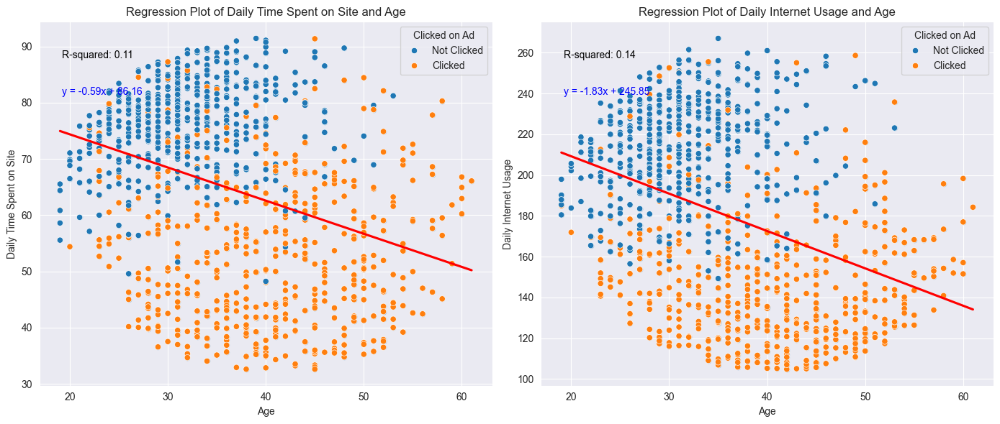

In [19]:
# Regplot of age vs daily time spent on site and daily internet usage
included_col = ['Daily Time Spent on Site', 'Daily Internet Usage']
plot_dynamic_regplots(df, x_col='Age', 
                      col_series=included_col, 
                      hue='Clicked on Ad', ncols=2, figsize=(14, 6))

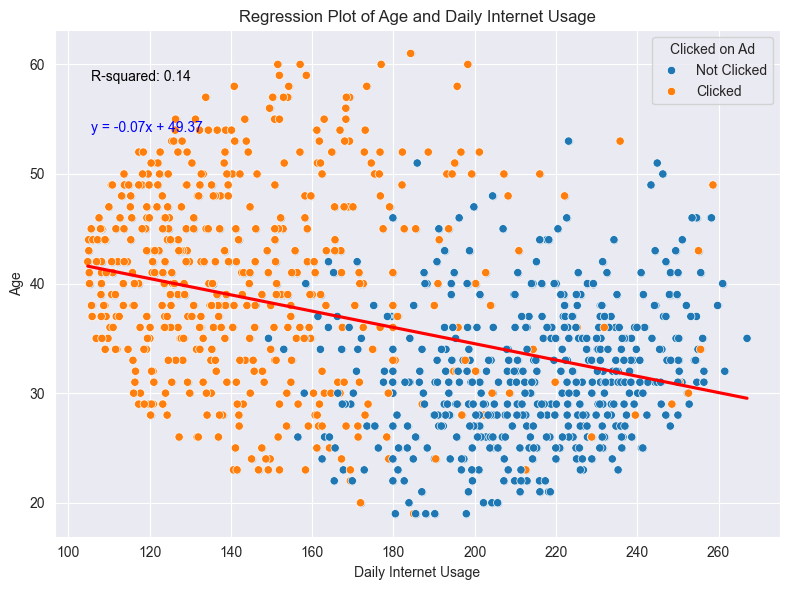

In [20]:
# Regplot of daily internet usage vs daily time spent on site
plot_dynamic_regplots(df, x_col='Daily Internet Usage', 
                      col_series=['Age'],
                      hue='Clicked on Ad', ncols=1, figsize=(8, 6))

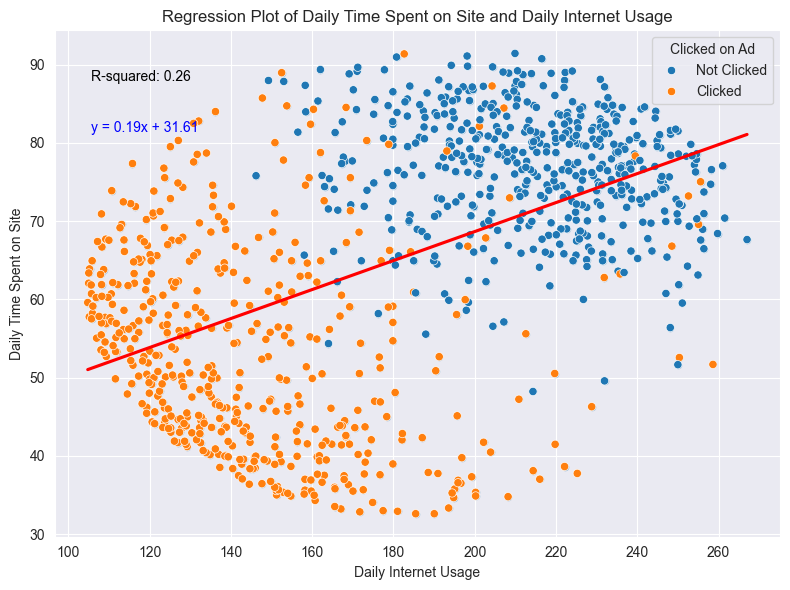

In [21]:
# Regplot of daily internet usage vs daily time spent on site 
plot_dynamic_regplots(df, x_col='Daily Internet Usage', 
                      col_series=['Daily Time Spent on Site'],
                      hue='Clicked on Ad', ncols=1, figsize=(8, 6))

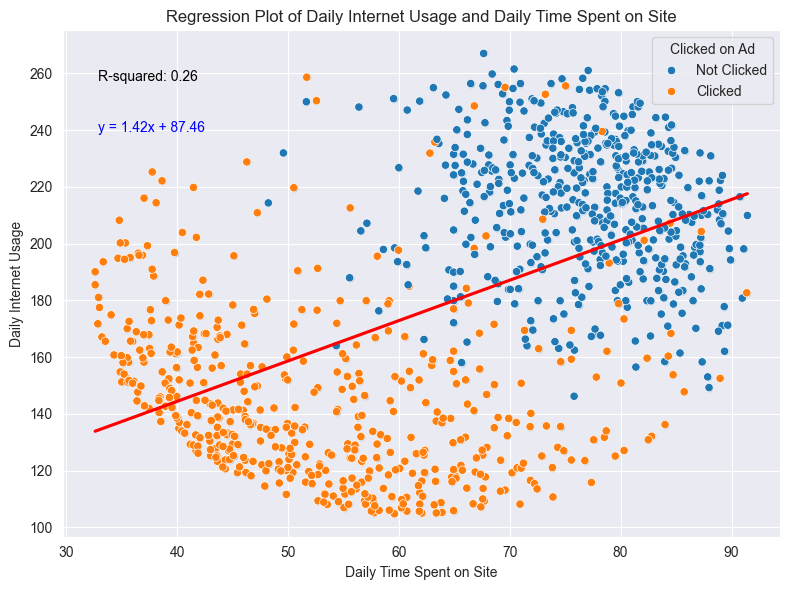

In [22]:
# Regplot of daily internet usage vs daily time spent on site 
plot_dynamic_regplots(df, x_col='Daily Time Spent on Site',
                      col_series=['Daily Internet Usage'],
                      hue='Clicked on Ad', ncols=1, figsize=(8, 6))

Concept Reminder :
- A low R-squared value (close to 0) suggests that the independent variable(s) does not explain much of the variability in the dependent variable, indicating a weak relationship.
- An R-squared value around 0.11 could be considered a weak to modest relationship.

**Major Findings :**
- Age is slightly negatively correlated with Daily Internet Usage. Older customers spend less time on the internet on average compared to younger customers.
- Age is also slightly negatively correlated with Daily Time Spent on Site.
- Internet usage is slightly positively correlated with time spent on site. But there is a quite clear separation between two clusters of data. One cluster is less active and the other more so. Less active customers have a higher tendency to click on an ad compared to more active customers.

In [23]:
# Plot the distribution of binary target variable for a categorical feature
def plot_categorical_stacked_value(df, category_col, target='Risk_Flag', pos_class='Default', neg_class='No Default',
                                    method='count', display_type='all', n_groups=5, figsize=(24, 12)):
    """
    Plot the distribution of binary target variable for a categorical feature using either count or rate method.

    Parameters:
    -----------
    df : pandas DataFrame
        The input dataframe containing the data
    category_col : str
        Name of the categorical column to analyze
    target : str, optional (default='Risk_Flag')
        Name of the target column containing binary classes
    pos_class : str, optional (default='Default')
        Name of the positive class in target column
    neg_class : str, optional (default='No Default')
        Name of the negative class in target column
    method : str, optional (default='count')
        Method to sort the categories:
        - 'count': Sort by absolute number of positive class
        - 'rate': Sort by positive class rate (positive / total)
        - 'total': Sort by total number of instances in each category
    display_type : str, optional (default='all')
        Type of display:
        - 'all': Show all values in descending order
        - 'top': Show only top n_groups
        - 'bottom': Show only bottom n_groups
        - 'both': Show both top and bottom n_groups
    n_groups : int, optional (default=5)
        Number of groups to display when using 'top', 'bottom', or 'both' display_type
    figsize : tuple, optional (default=(24, 12))
        Size of the figure

    Returns:
    --------
    None
        Displays a figure with the specified plot configuration
    """
    
    # Create the grouped data
    grouped_data = df.groupby([category_col, target]).size().unstack(fill_value=0)
    
    # Calculate positive rate and total for all categories
    grouped_data['Positive_Rate'] = grouped_data[pos_class] / (grouped_data[pos_class] + grouped_data[neg_class])
    grouped_data['Total'] = grouped_data[pos_class] + grouped_data[neg_class]

    if method == 'count':
        # Sort by absolute number of positive class
        sorted_data = grouped_data.sort_values(pos_class, ascending=False)
        title_prefix = f'Number of {pos_class}'
    elif method == 'rate':
        # Sort by positive class rate
        sorted_data = grouped_data.sort_values('Positive_Rate', ascending=False)
        title_prefix = f'{pos_class} Rate'
    elif method == 'total':
        # Sort by total number of instances
        sorted_data = grouped_data.sort_values('Total', ascending=False)
        title_prefix = 'Total Count'
    else:
        raise ValueError("Method must be one of: 'count', 'rate', or 'total'")

    # Drop the auxiliary columns before plotting
    sorted_data = sorted_data.drop(['Positive_Rate', 'Total'], axis=1)

    # Select data based on display_type
    if display_type == 'all':
        plot_data = sorted_data
        n_subplots = 1
        subplot_titles = [f'All {category_col}s by {title_prefix} (Descending Order)']
    elif display_type == 'top':
        plot_data = sorted_data.head(n_groups)
        n_subplots = 1
        subplot_titles = [f'Top {n_groups} {category_col}s by {title_prefix}']
    elif display_type == 'bottom':
        plot_data = sorted_data.tail(n_groups)
        n_subplots = 1
        subplot_titles = [f'Bottom {n_groups} {category_col}s by {title_prefix}']
    elif display_type == 'both':
        top_data = sorted_data.head(n_groups)
        bottom_data = sorted_data.tail(n_groups)
        n_subplots = 2
        subplot_titles = [
            f'Top {n_groups} {category_col}s by {title_prefix}',
            f'Bottom {n_groups} {category_col}s by {title_prefix}'
        ]
    else:
        raise ValueError("display_type must be one of: 'all', 'top', 'bottom', or 'both'")

    # Adjust figure size based on number of categories
    if display_type == 'all':
        height = max(12, len(plot_data) * 0.4)
        figsize = (figsize[0], height)

    # Create the plot
    fig, ax = plt.subplots(n_subplots, 1, figsize=figsize)
    
    # Convert ax to array if it's a single subplot
    if n_subplots == 1:
        ax = [ax]

    # Plot the data
    if display_type == 'both':
        plot_datasets = [top_data, bottom_data]
    else:
        plot_datasets = [plot_data]

    for i, (data, title) in enumerate(zip(plot_datasets, subplot_titles)):
        data.plot(kind='bar', stacked=True, ax=ax[i])
        ax[i].set_title(title)
        ax[i].set_ylabel('Count')
        ax[i].legend(title=target)

        # Add value labels
        for container in ax[i].containers:
            ax[i].bar_label(container, label_type='center')

        # Add appropriate labels above the bars based on method
        total_heights = data.sum(axis=1)
        
        if method == 'count':
            # Show total count above bars
            for j, total in enumerate(total_heights):
                ax[i].text(j, total + (total * 0.02), total, ha='center', va='bottom')
        elif method == 'rate':
            # Show rate percentage above bars
            rates = grouped_data.loc[data.index, 'Positive_Rate']
            for j, (rate, total) in enumerate(zip(rates, total_heights)):
                ax[i].text(j, total + (total * 0.02), f'{rate:.1%}', 
                          ha='center', va='bottom')
        elif method == 'total':
            # Show total count above bars
            totals = grouped_data.loc[data.index, 'Total']
            for j, total in enumerate(totals):
                ax[i].text(j, total + (total * 0.02), total, 
                          ha='center', va='bottom')

        # Rotate x-axis labels
        plt.setp(ax[i].get_xticklabels(), rotation=45, ha='right')

    plt.tight_layout()
    plt.show()

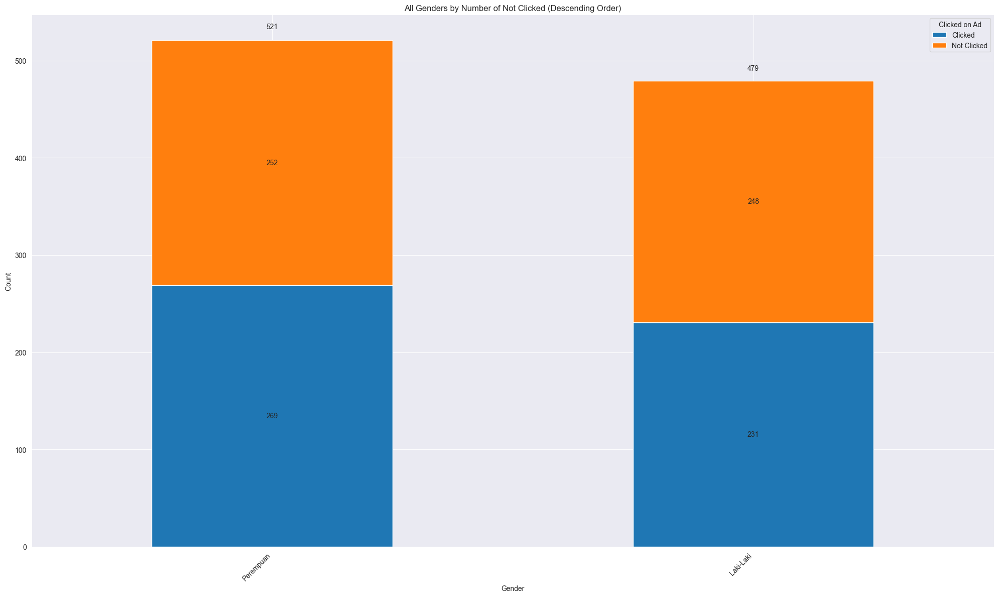

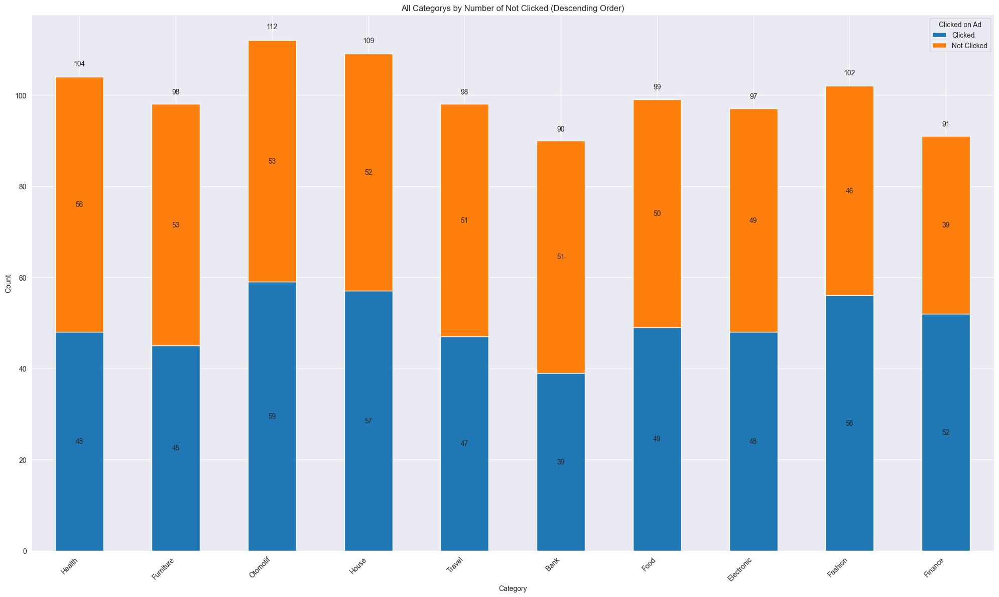

In [24]:
# Function implementation for all few unique values columns
cats_cols_few = ['Gender', 'Category']
for col in cats_cols_few:
    plot_categorical_stacked_value(df, col, target='Clicked on Ad', 
                                   pos_class='Not Clicked', 
                                   neg_class='Clicked',
                                   method='count',
                                   display_type='all', 
                                   figsize=(20, 20))

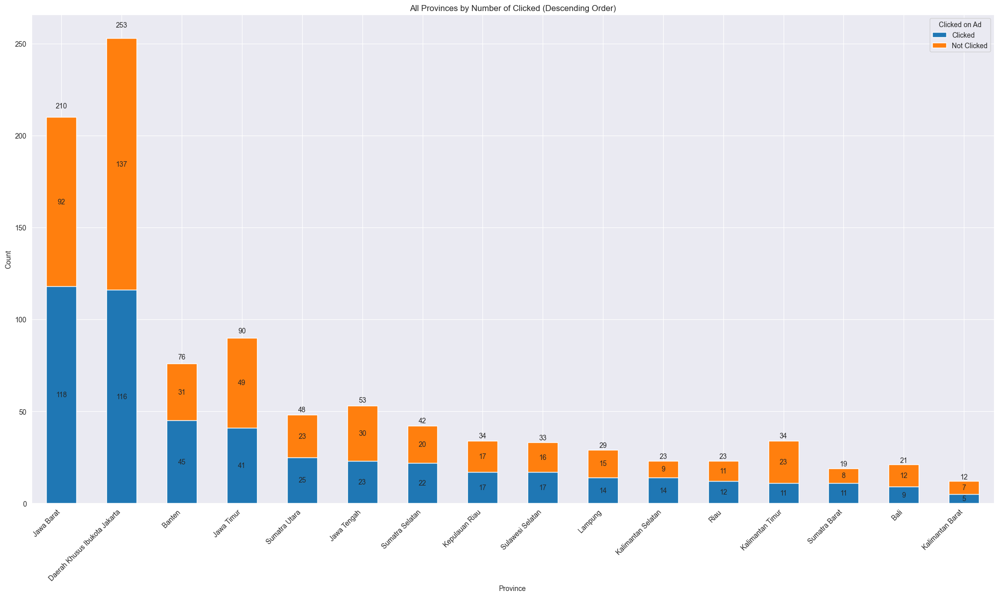

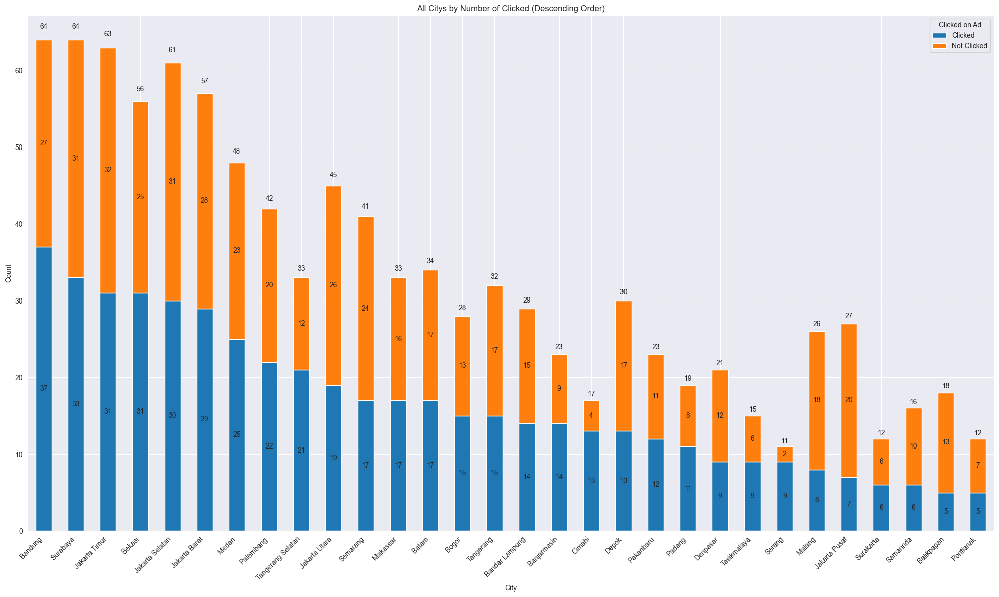

In [25]:
# Function implementation for all many unique values columns
cats_cols_many = ['Province', 'City']
for col in cats_cols_many:
    plot_categorical_stacked_value(df, col, target='Clicked on Ad', 
                                   pos_class='Clicked', 
                                   neg_class='Not Clicked',
                                   method='count',
                                   display_type='all', 
                                   figsize=(20, 20))

**Major Findings :**

- Females clicked on an ad slightly more than males overall even though the difference is not significant
- Ad categories click rates are pretty equal with none below 40% and none above 60%.
- Province with the highest amount of click on ad is Jawa Barat, while the lowest is Kalimantan Barat. The difference is quite large between the top 2 and the rest.
- City with the highest amount of click on ad is Bandung, while the lowest are Balikpapan and Pontianak.

## Multivariate Analysis

> As we have seen from the regression plot before that the numerical distribution is not linear, so we use methods of calculating the correlation that can capture non-linear relationship better, which is Spearmann method.

**Reminder About Correlation Method**

If you have a non-linear distribution of your numerical features, using Pearson correlation may not capture the full extent of the relationship between variables because Pearson correlation measures linear relationships. In such cases, Spearman and Kendall correlations can be more appropriate alternatives as they are non-parametric measures and can capture monotonic relationships, which may better reflect non-linear associations.

Here's a brief overview of each correlation method and its suitability for different types of relationships:

1. **Pearson Correlation**:
   - Measures the linear relationship between two continuous variables.
   - Assumes that variables are normally distributed and have a linear relationship.
   - Sensitive to outliers.
   - Suitable for linear relationships.

2. **Spearman Correlation**:
   - Measures the strength and direction of monotonic relationships between two continuous or ordinal variables.
   - Does not assume linearity.
   - More robust to outliers compared to Pearson correlation.
   - Suitable for non-linear relationships.

3. **Kendall Correlation**:
   - Measures the strength and direction of ordinal relationships between two variables.
   - Does not assume linearity.
   - Less affected by outliers compared to Pearson correlation.
   - Suitable for non-linear relationships, especially when the data is ranked or ordinal.

In summary, if you suspect that your data has non-linear relationships, it's advisable to calculate both Spearman and Kendall correlations in addition to Pearson correlation to capture different aspects of the relationships. This allows you to have a more comprehensive understanding of the associations between variables. Additionally, visual exploration through scatter plots or other graphical techniques can also provide insights into the nature of the relationships between variables.

In [26]:
# Convert target column to numerical
change_target_dtype(df, 'Clicked on Ad', target_type='numerical')

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Gender,Visit Time,City,Province,Category,Clicked on Ad
0,68.950000,35,432837300.0,256.09,Perempuan,2016-03-27 00:53:00,Jakarta Timur,Daerah Khusus Ibukota Jakarta,Furniture,0
1,80.230000,31,479092950.0,193.77,Laki-Laki,2016-04-04 01:39:00,Denpasar,Bali,Food,0
2,69.470000,26,418501580.0,236.50,Perempuan,2016-03-13 20:35:00,Surabaya,Jawa Timur,Electronic,0
3,74.150000,29,383643260.0,245.89,Laki-Laki,2016-01-10 02:31:00,Batam,Kepulauan Riau,House,0
4,68.370000,35,517229930.0,225.58,Perempuan,2016-06-03 03:36:00,Medan,Sumatra Utara,Finance,0
...,...,...,...,...,...,...,...,...,...,...
995,72.970000,30,499691990.0,208.58,Laki-Laki,2016-02-11 21:49:00,Semarang,Jawa Tengah,Finance,1
996,51.300000,45,474475190.0,134.42,Laki-Laki,2016-04-22 02:07:00,Pakanbaru,Riau,Electronic,1
997,64.929524,51,296910040.0,120.37,Laki-Laki,2016-02-01 17:24:00,Samarinda,Kalimantan Timur,Travel,1
998,55.550000,19,293445530.0,187.95,Perempuan,2016-03-24 02:35:00,Tangerang,Banten,Bank,0


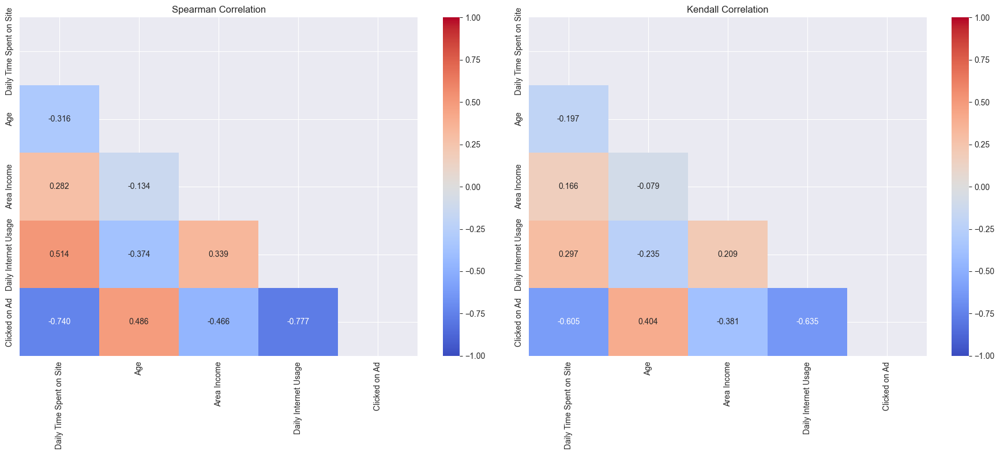

In [27]:
# Correlation heatmap of numerical features and target
fig, ax = plt.subplots(1, 2, figsize=(18, 8))

# Create a mask for the upper triangle
mask = np.triu(np.ones_like(df.corr(numeric_only=True), dtype=bool))

# Plot correlation heatmap with Spearman method
sns.heatmap(data=df.corr(method='spearman', numeric_only=True), mask=mask, cmap='coolwarm', annot=True, fmt='.3f', vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title('Spearman Correlation')

# Plot correlation heatmap with Kendall method
sns.heatmap(data=df.corr(method='kendall', numeric_only=True), mask=mask, cmap='coolwarm', annot=True, fmt='.3f', vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title('Kendall Correlation')

plt.tight_layout()
plt.show()

In [28]:
from utils import calculate_correlation_tabular

# Correlation analysis for both feature-feature and feature-target
feature_feature_df, feature_target_df = calculate_correlation_tabular(
    df, 
    target_col='Clicked on Ad', 
    method='spearman', 
    corr_type='both'
)

Correlation Between Features:


,A,B,Corr Value,Corr Type
0,Daily Time Spent on Site,Daily Internet Usage,0.514424,Positive
1,Age,Daily Internet Usage,0.374039,Negative
2,Daily Internet Usage,Area Income,0.339034,Positive
3,Daily Time Spent on Site,Age,0.315546,Negative
4,Daily Time Spent on Site,Area Income,0.282280,Positive
5,Area Income,Age,0.134418,Negative



Correlation of Features to Target:


,Feature,Corr Value,Corr Type
0,Daily Internet Usage,0.777141,Negative
1,Daily Time Spent on Site,0.739857,Negative
2,Age,0.486337,Positive
3,Area Income,0.466317,Negative



Chi-Square Analysis Results:
--------------------------------------------------------------------------------


,Feature,Chi-Square,P-Value,Cramér's V,Effect Size,Is Significant,Strongest Category,Association Direction
1,City,34.947015,0.206285,0.186941,Small,False,Jakarta Pusat,Positive
2,Province,16.021392,0.380631,0.126576,Small,False,Kalimantan Timur,Positive
3,Category,6.440443,0.695155,0.080252,Negligible,False,Finance,Negative
0,Gender,1.025810,0.311145,0.032028,Negligible,False,Laki-Laki,Positive


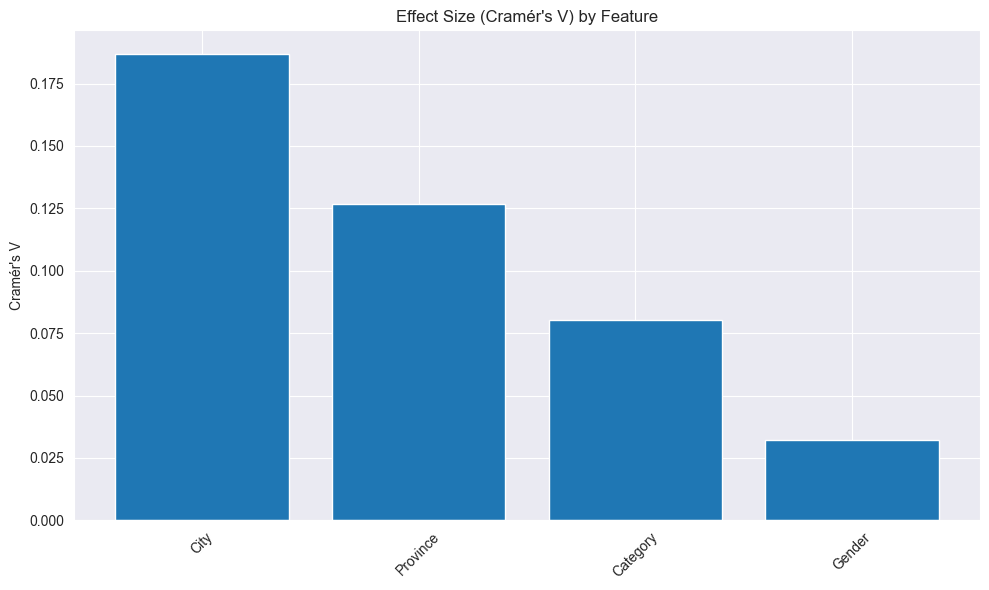

In [29]:
# Categorical features correlation analysis
from utils import analyze_categorical_relationships

# Using categorical features that wanted to test
cats_check_correlation = [col for col in cats_cols if col != 'Clicked on Ad']

# Analyze relationships between categorical features and target
results = analyze_categorical_relationships(
    df, 
    features=cats_check_correlation, 
    target='Clicked on Ad', 
    alpha=0.05
)

**Additional Information About Cramér's V**

Cramér's V is a measure of association between two categorical variables. It is an extension of the chi-square (χ²) test for independence and provides a way to quantify the strength of the association between categorical variables. Cramér's V ranges from 0 to 1, where 0 indicates no association, and 1 indicates a perfect association.

The formula for Cramér's V is:

$$V = \sqrt{\frac{\chi^2}{n \cdot \min(k-1, r-1)}}$$

Where:
- $\chi^2$ is the chi-square statistic obtained from the contingency table,
- $n$ is the total number of observations,
- $k$ is the number of categories in one variable, and
- $r$ is the number of categories in the other variable.

Cramér's V is commonly used for square contingency tables, but it can be applied to rectangular tables as well. It is particularly useful when dealing with nominal categorical variables and helps assess the strength of association between them. Keep in mind that Cramér's V is sensitive to table size, so its interpretation should be done with consideration of the specific context and domain knowledge.

Other references for categorical correlation : https://www.statology.org/correlation-between-categorical-variables/

**Major Findings :**

- **Feature-to-feature correlation: (Highest to Lowest)**
    > **Numerical :**

    - `Daily Time Spent on Site` and `Daily Internet Usage` (0.51) have moderate positive relationship, suggesting that people who spend more time on the site tend to use the internet more, and vice versa, but the relationship might not be strictly linear.

    - `Age` and `Daily Internet Usage` (-0.37) have moderate negative relationship, meaning that the older the customer, the less their daily internet usage. This might be because younger individuals are more likely to be digitally active.

    - `Area Income` and `Daily Internet Usage` (0.34) have moderate positive relationship, indicating that people with higher area incomes tend to use the internet more on a daily basis. This could be because they have better access to technology and higher-speed internet connections.

    - `Daily Time Spent on Site` and `Age` (-0.31) have moderate negative relationship, suggesting that older users tend to spend less time on the site and that younger individuals may be more active on the site.

    - `Daily Time Spent on Site` and `Area Income` (0.28) have moderate positive relationship, whare this could mean that people with higher area income levels spend more time on the site.

    - `Age` and `Area Income` (-0.13) have low negative relationship, indication that the older the age of people the more the average income of that area, even though this is not necessarily laways the case.

    > **Categorical :**
    
    - All categorical features (non-encoded) `Gender`, `City`, `Province`, and `Category` have very weak relationship to each other


- **Feature-to-target correlation: (Highest to Lowest)**
    > **Numerical :**

    - `Daily Internet Usage` (-0.79) have strong negative relationship to `Clicked on Ad`. Suggesting that users who spend more time on the internet are less likely to click on the ad. This could imply that users who are more active internet users might be less responsive to online advertisements.  

    - `Daily Time Spent on Site` (0.74) also have strong negative relationship to `Clicked on Ad`. Meaning that users who spend more time on the site are less likely to click on the ad. This could mean that users who spend a lot of time on the site might be more engaged with the content and less likely to click on ads.

    - `Age` (0.48) have moderate positive relationship to `Clicked on Ad`. Meaning that adult/elderly users are more likely to clicked on Ad than younger users.

    - `Area Income` (0.46) have moderate negative relationship to `Clicked on Ad`. Users in areas with lower income levels are more likely to click on the ad.

    > **Categorical :**
    
    - All categorical features (non-encoded) `Gender`, `City`, `Province`, and `Category` have very weak relationship to `Clicked on Ad` target variable.

In [30]:
# # Pairplot of numerical features
# sns.pairplot(data=df, diag_kind='kde', hue='Clicked on Ad', markers=['o', 's'])
# plt.suptitle('Pairplot of Numerical Features')
# plt.tight_layout()
# plt.show()

As explained before in regression plot that there are quite an interesting segmentation of target variable for each numerical features even though their correlation is not linear.

In [31]:
# Stripplot/swarmplot analysis
def plot_dynamic_stripplot_swarmplot(df, cat_col, nums_cols_series, hue_col='Clicked on Ad', 
                                   n_cols=2, figsize=(14, 10), plot_type='stripplot'):
    """
    Create multiple stripplots or swarmplots comparing a categorical column against numerical columns.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        The input dataframe containing the data
    cat_col : str
        The name of the categorical column to plot on x-axis
    nums_cols_series : list
        List of numerical column names to plot on y-axis
    hue_col : str, optional
        Column name to use for color coding (default: 'Clicked on Ad')
    n_cols : int, optional
        Number of columns in the subplot grid (default: 2)
    figsize : tuple, optional
        Figure size in inches (width, height) (default: (14, 10))
    plot_type : str, optional
        Type of plot to create: 'stripplot' or 'swarmplot' (default: 'stripplot')
    
    Returns:
    --------
    None
        Display a grid of plots
    """
    # Validate plot_type
    if plot_type not in ['stripplot', 'swarmplot']:
        raise ValueError("plot_type must be either 'stripplot' or 'swarmplot'")
    
    # Calculate number of rows needed based on number of plots and columns
    n_plots = len(nums_cols_series)
    n_rows = (n_plots + n_cols - 1) // n_cols
    
    # Create subplots
    fig, ax = plt.subplots(nrows=n_rows, ncols=n_cols, 
                          figsize=figsize)
    
    # Flatten axes array for easier iteration
    ax = ax.flatten() if n_plots > 1 else [ax]
    
    # Create plots
    for i, num_col in enumerate(nums_cols_series):
        if plot_type == 'stripplot':
            sns.stripplot(data=df, ax=ax[i], 
                         x=cat_col, y=num_col, 
                         hue=hue_col)
            plot_name = 'Stripplot'
        else:  # swarmplot
            sns.swarmplot(data=df, ax=ax[i], 
                         x=cat_col, y=num_col, 
                         hue=hue_col)
            plot_name = 'Swarmplot'
            
        ax[i].set_title(f'{cat_col} {plot_name} for {num_col}')
        
        # Rotate x-axis labels if they're too long
        ax[i].tick_params(axis='x', rotation=45)
    
    # Hide empty subplots if any
    for i in range(len(nums_cols_series), len(ax)):
        ax[i].set_visible(False)
    
    plt.tight_layout()
    plt.show()

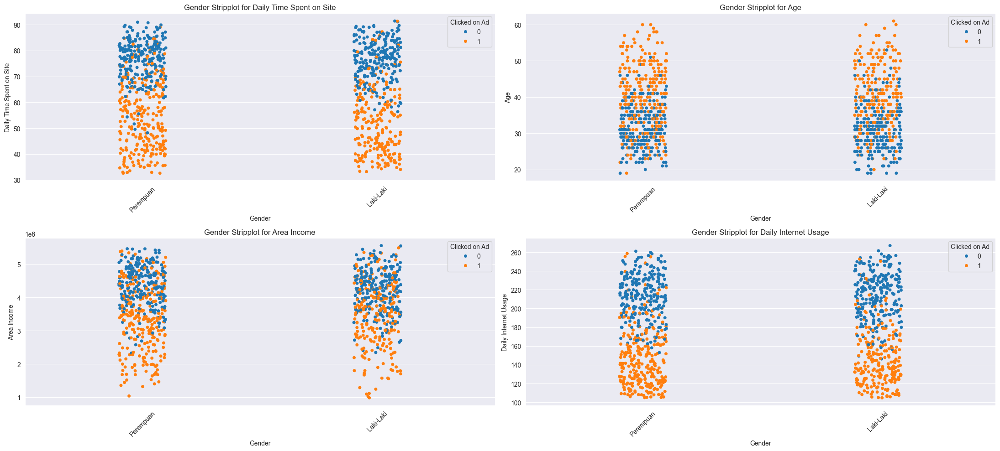

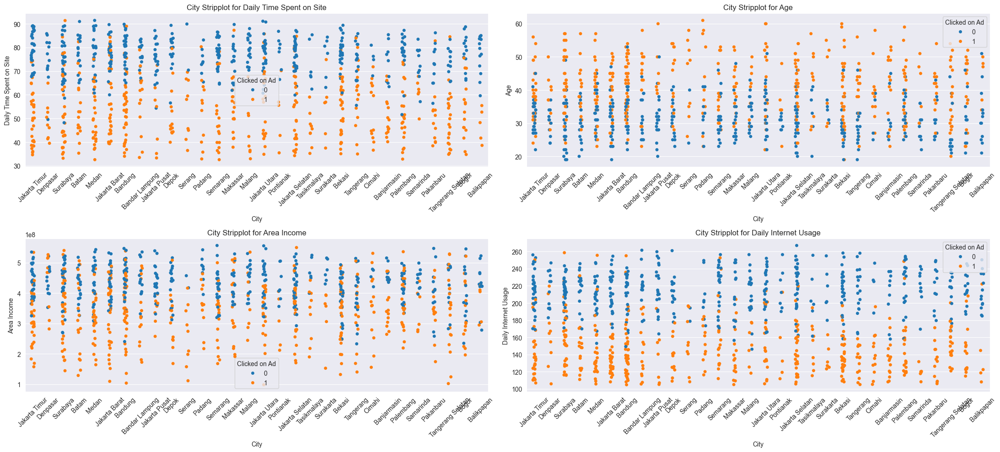

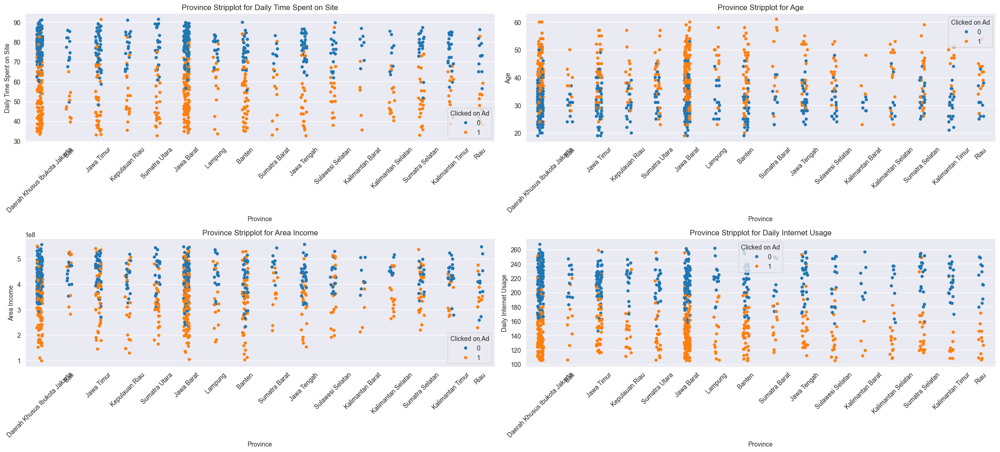

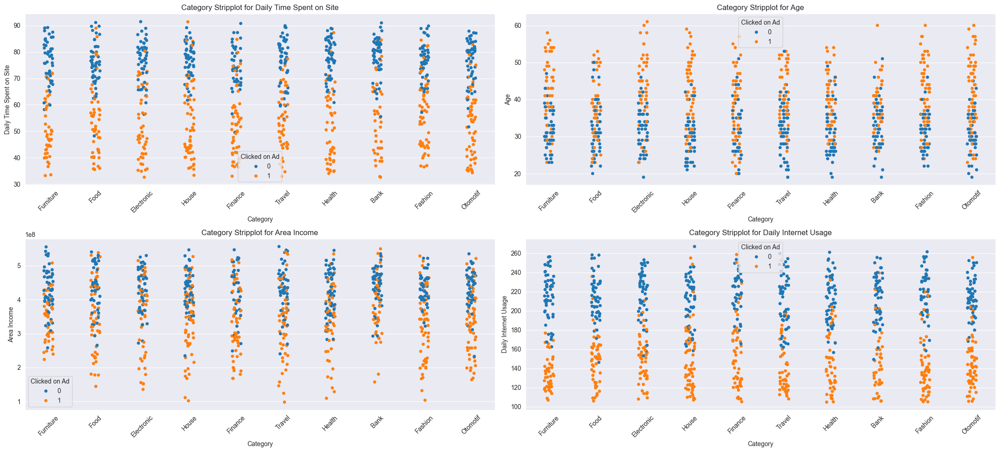

In [32]:
# Function implementation
for cat_col in [col for col in cats_cols if col != 'Clicked on Ad']:
    plot_dynamic_stripplot_swarmplot(df, cat_col, nums_cols_series=nums_cols, 
                                     hue_col='Clicked on Ad', 
                                     n_cols=2, 
                                     figsize=(22, 10))

**Major Findings :**

- Currently there are no meaningful insight that we can extract for the distribution of data points in each category, since they all have the same pattern but just different amount of data. 

# **STAGE 2 : DATA PREPROCESSING**

## Feature Engineering

In [33]:
# Make a copy of original dataframe for preprocessing and encoding process
df_preprocessed = df.copy()
df_preprocessed.sample(5)

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Gender,Visit Time,City,Province,Category,Clicked on Ad
958,79.830000,29,390351010.0,234.23000,Laki-Laki,2016-05-18 19:33:00,Jakarta Selatan,Daerah Khusus Ibukota Jakarta,Otomotif,0
991,38.960000,38,255480540.0,179.86362,Laki-Laki,2016-07-21 16:02:00,Jakarta Selatan,Daerah Khusus Ibukota Jakarta,Travel,1
866,86.580000,32,421062390.0,195.93000,Laki-Laki,2016-02-26 23:44:00,Jakarta Barat,Daerah Khusus Ibukota Jakarta,Electronic,0
63,64.929524,32,431207350.0,179.86362,Laki-Laki,2016-03-31 20:55:00,Makassar,Sulawesi Selatan,Finance,0
867,90.750000,40,321621160.0,216.50000,Perempuan,2016-03-11 09:58:00,Jakarta Utara,Daerah Khusus Ibukota Jakarta,Finance,0


### Age Group

The `Age Group` column is created by grouping the `Age` column. But first we need check the distribution of age to help with the grouping range.

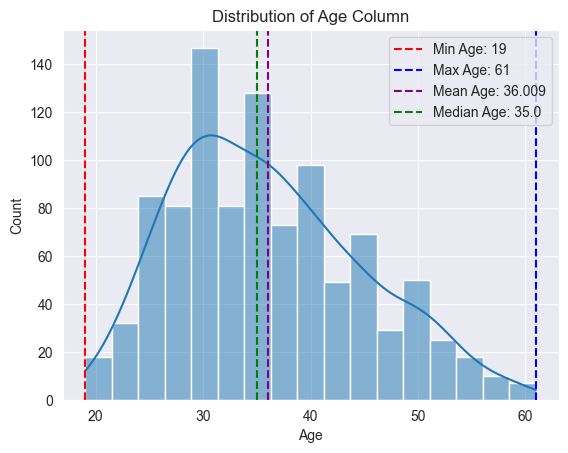

In [34]:
# Checking the distribution of Age column visually
min_age = df_preprocessed['Age'].min()
max_age = df_preprocessed['Age'].max()
mean_age = df_preprocessed['Age'].mean()
median_age = df_preprocessed['Age'].median()

sns.histplot(data=df_preprocessed, x='Age', kde=True)
plt.axvline(min_age, color='red', linestyle='--', label=f'Min Age: {min_age}')
plt.axvline(max_age, color='blue', linestyle='--', label=f'Max Age: {max_age}')
plt.axvline(mean_age, color='purple', linestyle='--', label=f'Mean Age: {mean_age}')
plt.axvline(median_age, color='green', linestyle='--', label=f'Median Age: {median_age}')
plt.title('Distribution of Age Column')
plt.legend()
plt.show()

In [35]:
# Age Group
def age_grouping(age) :
    if age >= 50 :
        group = 'Senior Adult'
    elif age >= 30 :
        group = 'Middle Adult'
    else :
        group = 'Young Adult'
    return group

df_preprocessed['Age Group'] = df_preprocessed['Age'].apply(age_grouping)

### Area Income Group

The `Area Income Group` column is created by grouping the `Area Income` column. Same as before procedure will be done for this column.

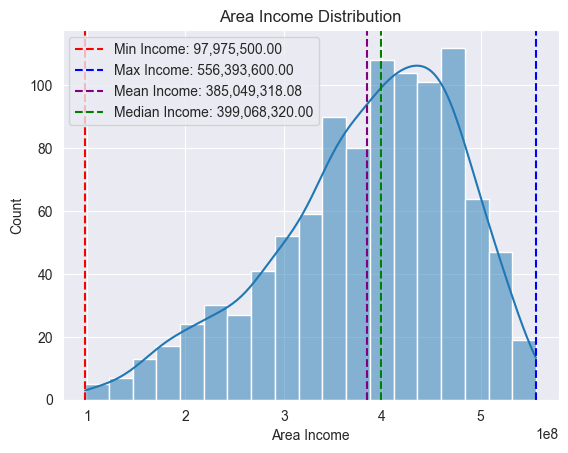

In [36]:
# Checking the distribution of Age column visually
min_income = round(df_preprocessed['Area Income'].min(), 2)
max_income = round(df_preprocessed['Area Income'].max(), 2)
mean_income = round(df_preprocessed['Area Income'].mean(), 2)
median_income = round(df_preprocessed['Area Income'].median(), 2)

sns.histplot(data=df, x='Area Income', kde=True)
plt.axvline(min_income, color='red', linestyle='--', label=f'Min Income: {min_income:,.2f}')
plt.axvline(max_income, color='blue', linestyle='--', label=f'Max Income: {max_income:,.2f}')
plt.axvline(mean_income, color='purple', linestyle='--', label=f'Mean Income: {mean_income:,.2f}')
plt.axvline(median_income, color='green', linestyle='--', label=f'Median Income: {median_income:,.2f}')
plt.title('Area Income Distribution')
plt.legend()
plt.show()

Since the distribution is quite heavily skewed, we will rely on quantiles for grouping.

In [37]:
# Income grouping
q1 = np.percentile(df_preprocessed['Area Income'], 25)
q2 = np.percentile(df_preprocessed['Area Income'], 50)
q3 = np.percentile(df_preprocessed['Area Income'], 75)

def income_grouping(income):
    if income <= q1 :
        group = 'Low Income'
    elif income <= q2 :
        group = 'Medium-Low Income'
    elif income <= q3 :
        group = 'Medium-High Income'
    else :
        group = 'High Income'
    return group

df_preprocessed['Area Income Group'] = df_preprocessed['Area Income'].apply(income_grouping)

### Datetime Components Columns (Month, Day, etc)

In [38]:
df_preprocessed['Visit Time'].describe()

count                          1000
mean     2016-04-10 10:33:36.840000
min             2016-01-01 02:52:00
25%             2016-02-18 02:55:15
50%             2016-04-07 17:27:00
75%             2016-05-31 03:18:00
max             2016-07-24 00:22:00
Name: Visit Time, dtype: object

As we have discovered before that the data only have information of 6/7 months of campaign data. So we won't need to extract the year component.

**Reminder :**

For datetime extraction methods check here : https://pandas.pydata.org/docs/user_guide/timeseries.html#time-date-components

In [39]:
# Datetime component extraction
df_preprocessed['Visit Month'] = df_preprocessed['Visit Time'].dt.month
df_preprocessed['Visit Week'] = df_preprocessed['Visit Time'].dt.isocalendar().week
df_preprocessed['Visit Day'] = df_preprocessed['Visit Time'].dt.day
df_preprocessed['Visit Hour'] = df_preprocessed['Visit Time'].dt.hour
df_preprocessed['Is Visit Day Weekend'] = df_preprocessed['Visit Time'].dt.day_of_week.isin([5, 6]).astype(int)

However as for the week extraction using isocalendar() method, the numbering will assign week 0 as week 53, even though the data only has up until around week 30. This need to be handled by converting week 53 to week 0.

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Gender,Visit Time,City,Province,Category,Clicked on Ad,Age Group,Area Income Group,Visit Month,Visit Week,Visit Day,Visit Hour,Is Visit Day Weekend
546,78.77,28,444483340.0,211.83,Perempuan,2016-01-01 08:27:00,Semarang,Jawa Tengah,Food,0,Young Adult,Medium-High Income,1,53,1,8,0
930,80.94,36,425621000.0,239.94,Perempuan,2016-01-01 05:31:00,Jakarta Timur,Daerah Khusus Ibukota Jakarta,Bank,0,Middle Adult,Medium-High Income,1,53,1,5,0


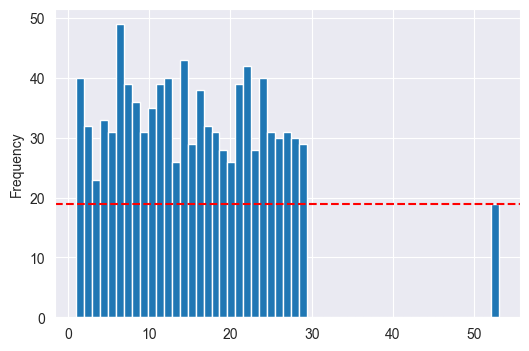

In [40]:
# Checking the distribution of Visit Week column visually
df_preprocessed['Visit Week'].plot(kind='hist', bins=53, figsize=(6, 4))
amount_of_week_53 = len(df_preprocessed[df_preprocessed['Visit Week'] == 53])
plt.axhline(amount_of_week_53, color='red', linestyle='--', label=f'Amount of Week 53: {amount_of_week_53}')

# Checking sample data of week 53
df_preprocessed[df_preprocessed['Visit Week'] == 53].sample(2)

In [41]:
# Transform the week 53 to week 0
df_preprocessed['Visit Week'] = df_preprocessed['Visit Week'].apply(lambda x: 0 if x == 53 else x)
df_preprocessed['Visit Week'] = df_preprocessed['Visit Week'].astype(int)

In [42]:
# Check distribution of weekend or not
df_preprocessed['Is Visit Day Weekend'].value_counts()

Is Visit Day Weekend
0    715
1    285
Name: count, dtype: int64

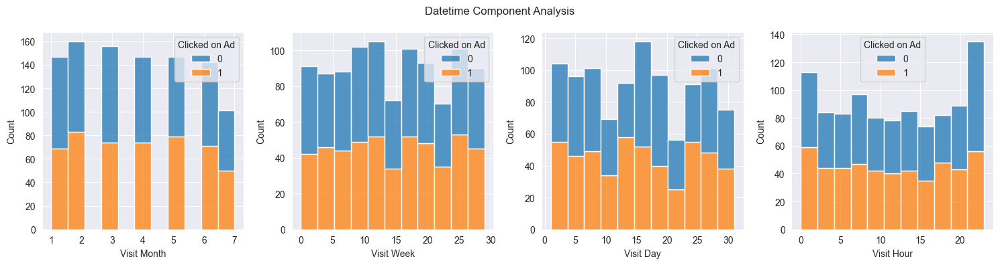

In [43]:
# Datetime component analysis
datetime_cols_analysis = ['Visit Month', 'Visit Week', 'Visit Day', 'Visit Hour']

fig, ax = plt.subplots(nrows=1, ncols=4, figsize=(15, 4))
ax = ax.flatten()

for i, col in enumerate(datetime_cols_analysis) :
    sns.histplot(data=df_preprocessed, ax=ax[i], x=col, hue='Clicked on Ad', multiple='stack')

plt.suptitle('Datetime Component Analysis')
plt.tight_layout()
plt.show()

There are not much of a difference between the visit time component of our site. The distributions are quite uniform between the customer who clicked on the ad or not.

In [44]:
# Re-check dataframe after feature engineering process
df_preprocessed.sample(3)

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Gender,Visit Time,City,Province,Category,Clicked on Ad,Age Group,Area Income Group,Visit Month,Visit Week,Visit Day,Visit Hour,Is Visit Day Weekend
58,77.63,29,392793590.0,239.22,Perempuan,2016-02-14 17:05:00,Surabaya,Jawa Timur,House,0,Young Adult,Medium-Low Income,2,6,14,17,1
298,80.39,31,463886430.0,214.74,Perempuan,2016-05-03 08:21:00,Bogor,Jawa Barat,Health,0,Middle Adult,High Income,5,18,3,8,0
832,41.46,42,365241800.0,128.98,Laki-Laki,2016-05-23 08:06:00,Jakarta Selatan,Daerah Khusus Ibukota Jakarta,Electronic,1,Middle Adult,Medium-Low Income,5,21,23,8,0


## Handling Outliers

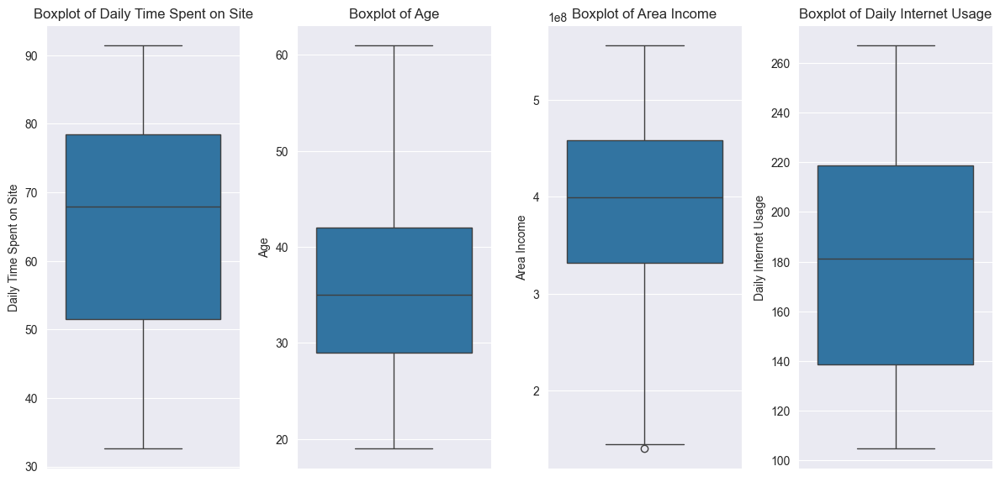

In [45]:
from utils import filter_outliers, plot_dynamic_boxplots_violinplots

# Outliers handling with IQR method function implementation
columns_to_filter = ['Area Income']
df_preprocessed = filter_outliers(df_preprocessed, columns=columns_to_filter, threshold=1.5, detect_only=False)

# Visualize outliers
plot_dynamic_boxplots_violinplots(df_preprocessed, nums_cols, plot_type="boxplot", ncols=4, orientation="v", figsize=(12, 6))

## Feature Encoding

In [46]:
# Re-check the unique values of categorical features to determine encoding technique
encoded_features = ['Gender', 'City', 'Province', 'Category', 'Age Group', 'Area Income Group']

for col in encoded_features :
    print(f'======={col}=======')
    print(df_preprocessed[col].unique())
    print()

=======Gender=======
['Perempuan' 'Laki-Laki']

=======City=======
['Jakarta Timur' 'Denpasar' 'Surabaya' 'Batam' 'Medan' 'Jakarta Barat'
 'Bandung' 'Bandar Lampung' 'Jakarta Pusat' 'Depok' 'Serang' 'Padang'
 'Semarang' 'Makassar' 'Malang' 'Jakarta Utara' 'Pontianak'
 'Jakarta Selatan' 'Tasikmalaya' 'Surakarta' 'Bekasi' 'Tangerang' 'Cimahi'
 'Banjarmasin' 'Palembang' 'Samarinda' 'Pakanbaru' 'Tangerang Selatan'
 'Bogor' 'Balikpapan']

=======Province=======
['Daerah Khusus Ibukota Jakarta' 'Bali' 'Jawa Timur' 'Kepulauan Riau'
 'Sumatra Utara' 'Jawa Barat' 'Lampung' 'Banten' 'Sumatra Barat'
 'Jawa Tengah' 'Sulawesi Selatan' 'Kalimantan Barat' 'Kalimantan Selatan'
 'Sumatra Selatan' 'Kalimantan Timur' 'Riau']

=======Category=======
['Furniture' 'Food' 'Electronic' 'House' 'Finance' 'Travel' 'Health'
 'Bank' 'Fashion' 'Otomotif']

=======Age Group=======
['Middle Adult' 'Young Adult' 'Senior Adult']

=======Area Income Group=======
['Medium-High Income' 'High Income' 'Medium-Low Income' '

In [ ]:
# Encode categorical features with the shared utils pipeline
from utils import feature_encoding

df_preprocessed, encoders = feature_encoding(
    df_preprocessed,
    ordinal_columns=['Gender', 'Age Group', 'Area Income Group'],
    ordinal_categories={
        'Gender': ['Perempuan', 'Laki-Laki'],
        'Age Group': ['Young Adult', 'Middle Adult', 'Senior Adult'],
        'Area Income Group': ['Low Income', 'Medium-Low Income', 'Medium-High Income', 'High Income']
    },
    nominal_columns=['City', 'Province', 'Category'],
    drop_first=True
)

In [49]:
# Re-check final dataframe after encoding process
df_preprocessed.sample(5)

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Gender,Visit Time,Clicked on Ad,Age Group,Area Income Group,Visit Month,Visit Week,Visit Day,Visit Hour,Is Visit Day Weekend,City_Bandar Lampung,City_Bandung,City_Banjarmasin,City_Batam,City_Bekasi,City_Bogor,City_Cimahi,City_Denpasar,City_Depok,City_Jakarta Barat,City_Jakarta Pusat,City_Jakarta Selatan,City_Jakarta Timur,City_Jakarta Utara,City_Makassar,City_Malang,City_Medan,City_Padang,City_Pakanbaru,City_Palembang,City_Pontianak,City_Samarinda,City_Semarang,City_Serang,City_Surabaya,City_Surakarta,City_Tangerang,City_Tangerang Selatan,City_Tasikmalaya,Province_Banten,Province_Daerah Khusus Ibukota Jakarta,Province_Jawa Barat,Province_Jawa Tengah,Province_Jawa Timur,Province_Kalimantan Barat,Province_Kalimantan Selatan,Province_Kalimantan Timur,Province_Kepulauan Riau,Province_Lampung,Province_Riau,Province_Sulawesi Selatan,Province_Sumatra Barat,Province_Sumatra Selatan,Province_Sumatra Utara,Category_Electronic,Category_Fashion,Category_Finance,Category_Food,Category_Furniture,Category_Health,Category_House,Category_Otomotif,Category_Travel
121,49.58,26,397542250.0,231.94,0,2016-04-07 16:02:00,0,0,1,4,14,7,16,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
818,81.98,34,472027430.0,212.88,0,2016-06-04 09:25:00,0,1,3,6,22,4,9,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
352,78.19,30,437331930.0,228.81,0,2016-01-31 06:14:00,0,1,2,1,4,31,6,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0
519,35.00,40,322236110.0,151.25,1,2016-06-18 16:02:00,1,1,0,6,24,18,16,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
333,79.36,34,400822870.0,245.78,1,2016-04-28 22:54:00,0,1,2,4,17,28,22,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


## Feature Selection

In [50]:
# Drop Visit DateTime column (unnecessary for further processes)
df_preprocessed.drop(columns='Visit Time', inplace=True)

# Re-arrange the columns (Clicked on Ad in last)
df_preprocessed = df_preprocessed[[col for col in df_preprocessed.columns if col != 'Clicked on Ad'] + ['Clicked on Ad']]

### Checking correlation heatmap (spearman method)

In [51]:
from utils import calculate_correlation_tabular

# Correlation analysis for both feature-feature and feature-target
feature_feature_df, feature_target_df = calculate_correlation_tabular(
    df_preprocessed, 
    target_col='Clicked on Ad', 
    method='spearman', 
    corr_type='both'
)

Correlation Between Features:


,A,B,Corr Value,Corr Type
0,City_Makassar,Province_Sulawesi Selatan,1.000000,Positive
1,Visit Week,Visit Month,0.988955,Positive
2,Area Income,Area Income Group,0.968185,Positive
3,City_Semarang,Province_Jawa Tengah,0.873964,Positive
4,Age Group,Age,0.847434,Positive
5,City_Surabaya,Province_Jawa Timur,0.831364,Positive
6,Province_Kalimantan Timur,City_Samarinda,0.679633,Positive
7,Province_Banten,City_Tangerang,0.647777,Positive
8,City_Tangerang Selatan,Province_Banten,0.637243,Positive
9,City_Malang,Province_Jawa Timur,0.519355,Positive



Correlation of Features to Target:


,Feature,Corr Value,Corr Type
0,Daily Internet Usage,0.780693,Negative
1,Daily Time Spent on Site,0.738982,Negative
2,Age,0.486129,Positive
3,Area Income,0.458972,Negative
4,Area Income Group,0.440087,Negative
5,Age Group,0.374842,Positive
6,City_Jakarta Pusat,0.079063,Negative
7,City_Cimahi,0.071145,Positive
8,Province_Kalimantan Timur,0.064816,Negative
9,Province_Jawa Barat,0.061762,Positive


### Checking multicolinearity using Variance Inflation Factor (VIF)

#### Reminder Regarding Variance Inflation Factor (VIF)

#### Variance Inflation Factor (VIF)

Variance Inflation Factor (VIF) is a statistical metric used to detect multicollinearity among independent variables in regression models. Multicollinearity occurs when independent variables are highly correlated with each other, which can lead to:
- Unstable coefficient estimates
- Inflated standard errors
- Difficulties in model interpretation

##### Mathematical Formulation

The VIF for the $i$-th independent variable is calculated as:
 
$$
\text{VIF}_i = \frac{1}{1 - R_i^2}
$$
 
Where $R_i^2$ is the $R^2$ value obtained from regressing the $i$-th independent variable against all other independent variables.

##### Interpretation Guidelines
- **VIF = 1**: No multicollinearity
- **VIF > 1**: Increasing levels of multicollinearity
- **VIF > 5 or 10**: Significant multicollinearity (potentially problematic)

##### Practical Implications
1. **Regression Tasks (commonly used)**:
   - Helps identify which variables contribute to multicollinearity
   - Assists in deciding whether to:
     * Remove certain variables
     * Re-specify the model
     * Apply techniques to mitigate multicollinearity

2. **Classification Tasks**:
   - Applicable in coefficient-based models like logistic regression
   - Less critical in tree-based models (Random Forest, Gradient Boosting), these models can handle correlated predictors to some extent
   - Interpretation may vary based on the specific algorithm

##### Recommendations
- Always assess multicollinearity, regardless of the task (regression or classification)
- Consider the context and characteristics of your data
- Use VIF as one of multiple tools for model diagnostics

##### Reference
Detailed documentation: [Statsmodels VIF Function](https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html#statsmodels.stats.outliers_influence.variance_inflation_factor)

In [52]:
from utils import calculate_vif

vif_data = calculate_vif(df_preprocessed, target_col='Clicked on Ad', high_threshold=10, moderate_threshold=5)

print("Displat top 10 VIF results:")
display(vif_data.head(10))

print("Displat bottom 10 VIF results:")
display(vif_data.tail(10))

Displat top 10 VIF results:


,Feature,VIF,Interpretation
0,City_Palembang,inf,High multicollinearity
1,Province_Sumatra Selatan,inf,High multicollinearity
2,Province_Kalimantan Barat,inf,High multicollinearity
3,Province_Daerah Khusus Ibukota Jakarta,inf,High multicollinearity
4,City_Serang,inf,High multicollinearity
5,Province_Lampung,9.007199e+15,High multicollinearity
6,City_Padang,9.007199e+15,High multicollinearity
7,City_Pontianak,9.007199e+15,High multicollinearity
8,City_Malang,9.007199e+15,High multicollinearity
9,Province_Banten,4.503600e+15,High multicollinearity


Displat bottom 10 VIF results:


,Feature,VIF,Interpretation
55,Category_Food,1.977895,Low multicollinearity
56,Category_Furniture,1.952074,Low multicollinearity
57,Category_Electronic,1.946359,Low multicollinearity
58,Category_Travel,1.933546,Low multicollinearity
59,Category_Finance,1.908499,Low multicollinearity
60,City_Samarinda,1.890438,Low multicollinearity
61,Daily Internet Usage,1.599707,Low multicollinearity
62,Daily Time Spent on Site,1.515788,Low multicollinearity
63,Gender,1.073270,Low multicollinearity
64,Visit Hour,1.065947,Low multicollinearity


As we can see here that, mostly the one-hot encoded features have high multicollinearity here, meaning that we probably wont be using them, but we need to make sure by doing another statsitical analysis.

### Checking feature importance using SelectKBest (Mutual information, Chi2, and ANOVA F-test)

#### Reminder Regarding Feature Relevance Calculation Method using SelectKBest

`sklearn.feature_selection.f_classif`, `sklearn.feature_selection.mutual_info_classif`, and `sklearn.feature_selection.chi2` are three different feature selection methods in scikit-learn, and each of them uses a different statistical test or measure to evaluate the importance of features in a classification task.

1. **`sklearn.feature_selection.f_classif`:**

   - **Type of Test:** Analysis of variance (ANOVA) F-statistic.
   - **Nature:** Assesses the linear dependency between each feature and the target variable.
   - **Assumption:** Assumes that the features are normally distributed and that the variance of the feature values is roughly equal across different classes.
   - **Usage:** Suitable for identifying features with significant differences in means among different classes.

   ```python
   from sklearn.feature_selection import f_classif
   ```

2. **`sklearn.feature_selection.mutual_info_classif`:**

   - **Type of Measure:** Mutual information, a non-parametric measure of the dependency between variables.
   - **Nature:** Captures any kind of statistical dependency, whether it is linear or non-linear.
   - **Assumption:** Has fewer assumptions compared to `f_classif` and is more robust when the relationship between features and the target variable is not strictly linear.
   - **Usage:** Suitable for identifying features with any type of relationship with the target variable.

   ```python
   from sklearn.feature_selection import mutual_info_classif
   ```

3. **`sklearn.feature_selection.chi2`:**

   - **Type of Test:** Chi-squared (χ²) statistical test.
   - **Nature:** Assesses the independence between each feature and the target variable.
   - **Assumption:** Assumes that the features and target variable are categorical.
   - **Usage:** Suitable for identifying features that are independent of the target variable in a categorical setting.

   ```python
   from sklearn.feature_selection import chi2
   ```

**Summary:**
- `f_classif` is based on the F-statistic and assumes a linear relationship between features and the target variable.
- `mutual_info_classif` is based on mutual information and is non-parametric, capturing any kind of statistical dependency.
- `chi2` uses the chi-squared test and is suitable for categorical data, assessing the independence between features and the target variable.

The choice between these methods depends on the nature of your data, the type of variables you have, and the assumptions you are willing to make about the relationships between features and the target variable. If your data is categorical, `chi2` might be more appropriate, while `f_classif` and `mutual_info_classif` are suitable for continuous or ordinal data.

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

#### Additional Information Regarding Scipy Statistical Tests

In `scipy`, you can determine feature importance using statistical tests that compute p-values. Here are some commonly used methods along with the corresponding functions in `scipy.stats`:

1. **T-test**: Determines if there is a significant difference between the means of two groups.
   - Function: `scipy.stats.ttest_ind()`

2. **ANOVA (Analysis of Variance)**: Determines if there are statistically significant differences between the means of three or more independent groups.
   - Function: `scipy.stats.f_oneway()`

3. **Chi-square test**: Tests the independence between two categorical variables.
   - Function: `scipy.stats.chi2_contingency()`

4. **Correlation test (Pearson, Spearman, etc.)**: Measures the strength and direction of association between two continuous variables.
   - Functions:
     - Pearson correlation: `scipy.stats.pearsonr()`
     - Spearman correlation: `scipy.stats.spearmanr()`
     - Kendall correlation: `scipy.stats.kendalltau()`

5. **Mutual information**: Measures the dependency between two variables by computing the reduction in uncertainty of one variable given the other.
   - Function: `sklearn.feature_selection.mutual_info_regression()` for regression problems and `sklearn.feature_selection.mutual_info_classif()` for classification problems.

6. **ANOVA F-value for feature selection**: Computes the ANOVA F-value for the provided sample and target variable.
   - Function: `sklearn.feature_selection.f_classif()` for classification problems and `sklearn.feature_selection.f_regression()` for regression problems.

Each of these methods provides a p-value, which indicates the significance of the relationship between the feature and the target variable. Lower p-values typically suggest stronger evidence against the null hypothesis, indicating a more significant feature.

Choose the appropriate method based on the nature of your data and the assumptions of the statistical test.

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [58]:
from utils import calculate_feature_importance

# Calculate feature importance using anova
feature_importance_f = calculate_feature_importance(
    X=df_preprocessed[[col for col in df_preprocessed.columns if col != 'Clicked on Ad']], 
    y=df_preprocessed['Clicked on Ad'], 
    task='classification', 
    method='anova', 
    k='all'
)

print("Feature importance (F-classif, top 15):")
display(feature_importance_f.iloc[:15].reset_index(drop=True))

Feature importance (F-classif, top 15):


,Feature,Score,P_Values
0,Daily Internet Usage,1643.948064,1.667625e-212
1,Daily Time Spent on Site,1216.091360,2.153898e-174
2,Age,318.057899,6.707319e-62
3,Area Income,278.565258,2.738110e-55
4,Area Income Group,237.118669,4.022063e-48
5,Age Group,167.656112,1.552879e-35
6,City_Jakarta Pusat,6.221017,1.278658e-02
7,City_Cimahi,5.031376,2.511287e-02
8,Province_Kalimantan Timur,4.172433,4.135149e-02
9,Province_Jawa Barat,3.787071,5.193290e-02


In [59]:
# Calculate mutual information using mutual info
feature_importance_mi = calculate_feature_importance(
    X=df_preprocessed[[col for col in df_preprocessed.columns if col != 'Clicked on Ad']], 
    y=df_preprocessed['Clicked on Ad'], 
    task='classification', 
    method='mutual_info', 
    k='all'
)

print("Feature importance (Mutual Info, top 15):")
display(feature_importance_mi.iloc[:15].reset_index(drop=True))

Feature importance (Mutual Info, top 15):


,Feature,Score,P_Values
0,Daily Internet Usage,0.419942,None
1,Daily Time Spent on Site,0.368240,None
2,Age,0.150135,None
3,Area Income,0.122865,None
4,Area Income Group,0.094033,None
5,Age Group,0.074913,None
6,Province_Sumatra Utara,0.033546,None
7,City_Depok,0.031210,None
8,City_Jakarta Timur,0.022534,None
9,Province_Jawa Tengah,0.021236,None


- Reviewing the statistical test values of several features generated, I've decided not to use some engineered features in training the model due to multicollinearity issues with the original features. Therefore, these engineered features will only be used for analysis purposes.

- Meanwhile, some one-hot encoded features like city and province have many features with very low importance to the target, so those features will not be used.

- **Most of the features that will be used are from original features**

In [60]:
df_preprocessed.columns

Index(['Daily Time Spent on Site', 'Age', 'Area Income',
       'Daily Internet Usage', 'Gender', 'Age Group', 'Area Income Group',
       'Visit Month', 'Visit Week', 'Visit Day', 'Visit Hour',
       'Is Visit Day Weekend', 'City_Bandar Lampung', 'City_Bandung',
       'City_Banjarmasin', 'City_Batam', 'City_Bekasi', 'City_Bogor',
       'City_Cimahi', 'City_Denpasar', 'City_Depok', 'City_Jakarta Barat',
       'City_Jakarta Pusat', 'City_Jakarta Selatan', 'City_Jakarta Timur',
       'City_Jakarta Utara', 'City_Makassar', 'City_Malang', 'City_Medan',
       'City_Padang', 'City_Pakanbaru', 'City_Palembang', 'City_Pontianak',
       'City_Samarinda', 'City_Semarang', 'City_Serang', 'City_Surabaya',
       'City_Surakarta', 'City_Tangerang', 'City_Tangerang Selatan',
       'City_Tasikmalaya', 'Province_Banten',
       'Province_Daerah Khusus Ibukota Jakarta', 'Province_Jawa Barat',
       'Province_Jawa Tengah', 'Province_Jawa Timur',
       'Province_Kalimantan Barat', 'Province_Kal

In [61]:
# Select only relevant features for each cases before moving to modelling process
df_model = df_preprocessed.copy()

# Important features only based on correlation and K-best parameter (correlation > 0.7 will be dropped)
selected_features = ['Daily Time Spent on Site', 'Age', 'Area Income',
                     'Daily Internet Usage', 'Gender', 'Category_Electronic',
                     'Category_Fashion', 'Category_Finance', 'Category_Food',
                     'Category_Furniture', 'Category_Health', 'Category_House',
                     'Category_Otomotif', 'Category_Travel', 'Clicked on Ad']

df_model = df_model[selected_features]

In [83]:
# # Save updated df_model to csv for model deployment
# df_model.to_csv('df_model.csv', index=False)

## Split Train and Test Data

> Update: The splitting approach used here is based on the original task of this project that is to compare between scaled features and non-scaled features, which is why you can see there 2 splitting done.

In [84]:
# Split Train and Test Data
X = df_model.drop(columns=['Clicked on Ad'])
y = df_model['Clicked on Ad']

# Initialize the train and test data for each case
X1 = X.copy()
y1 = y.copy()
X2 = X.copy()
y2 = y.copy()

from sklearn.model_selection import train_test_split

X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.3, random_state=42) # Data without scaling
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.3, random_state=42) # Data with scaling

#Check dimension of train and test data
print(f'Dimension of X_train data : {X1_train.shape}')
print(f'Dimension of y_train data : {y1_train.shape}')
print(f'Dimension of X_test data : {X1_test.shape}')
print(f'Dimension of y_test data : {y1_test.shape}')

Dimension of X_train data : (693, 14)
Dimension of y_train data : (693,)
Dimension of X_test data : (298, 14)
Dimension of y_test data : (298,)


In [85]:
# Check distribution of target after splitting
display(y2_train.value_counts())
display(y2_test.value_counts())

Clicked on Ad
1    347
0    346
Name: count, dtype: int64

Clicked on Ad
0    154
1    144
Name: count, dtype: int64

## Feature Scalling

Train Data Distribution Before Scaling: 


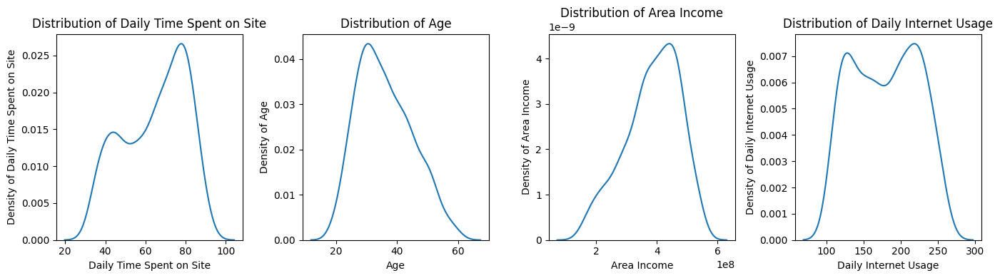

Test Data Distribution Before Scaling: 


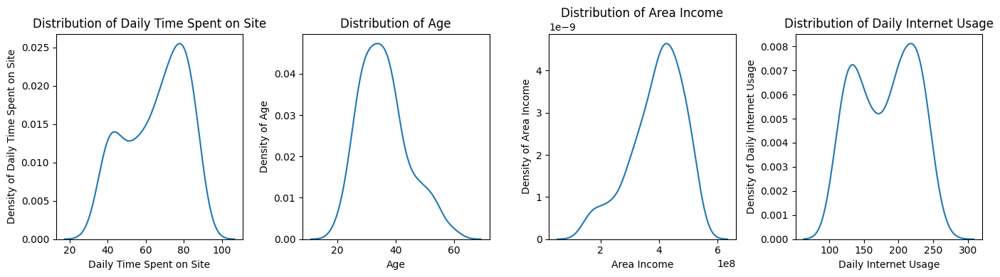

In [86]:
# Checking distribution before scaling
columns_to_scale = ['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage'] # Choose columns for scaling based on the distribution in EDA

print("Train Data Distribution Before Scaling: ")
plot_dynamic_hisplots_kdeplots(df=X2_train, col_series=columns_to_scale, plot_type='kdeplot', ncols=4, figsize=(14, 4))

print("Test Data Distribution Before Scaling: ")
plot_dynamic_hisplots_kdeplots(df=X2_test, col_series=columns_to_scale, plot_type='kdeplot', ncols=4, figsize=(14, 4))

The overall feature distribution is near normal distribution, but the problem lies in the values range. The proper method of scalling for this case is standardization.

**Reminder About Choosing Scaling Methods**

If the issue is primarily with the range of values rather than the shape of the distributions, you can use scaling methods to bring all features to a similar scale without altering their distributions. Here are some common scaling methods you can consider:

1. **Min-Max Scaling (Normalization)**:
   - Scales the data to a fixed range, usually between 0 and 1.
   - Formula: \( X_{\text{scaled}} = \frac{X - X_{\text{min}}}{X_{\text{max}} - X_{\text{min}}} \)
   - Use when you know the minimum and maximum values for your features or when you want to bound the data within a specific range.

2. **Standard Scaling (Standardization)**:
   - Scales the data so that it has a mean of 0 and a standard deviation of 1.
   - Formula: \( X_{\text{scaled}} = \frac{X - \mu}{\sigma} \)
   - Use when the features are normally distributed or when you're using models that assume zero-centered data.

3. **Robust Scaling**:
   - Scales the data similarly to standard scaling but uses the median and the interquartile range (IQR) instead of the mean and standard deviation.
   - Formula: \( X_{\text{scaled}} = \frac{X - \text{median}(X)}{\text{IQR}(X)} \)
   - Use when the data contains outliers or when the distribution is not normal.

4. **Max Abs Scaler**:
   - Scales each feature to its maximum absolute value.
   - Formula: \( X_{\text{scaled}} = \frac{X}{\max(|X|)} \)
   - Use when the features are sparse or when you want to preserve sparsity.

5. **Power Transformer (Yeo-Johnson or Box-Cox)**:
   - Applies a power transformation to make the data more Gaussian-like.
   - Use when the data is skewed or when you need to stabilize variance.

For your case where the overall feature distributions are near normal but the ranges vary significantly, Min-Max Scaling or Standard Scaling might be appropriate. If you're concerned about outliers, Robust Scaling could be a better choice. It's often a good idea to try different scaling methods and see which one works best for your specific dataset and model.

In [87]:
# Statistical summary of mean and standard deviation before scale
X2_train[columns_to_scale].describe().transpose()[['mean', 'std']]

,mean,std
Daily Time Spent on Site,6.469393e+01,1.579638e+01
Age,3.603608e+01,8.968643e+00
Area Income,3.849767e+08,9.025912e+07
Daily Internet Usage,1.794542e+02,4.393979e+01


In [ ]:
# Scaling with standardization method
from utils import feature_scaling

X2_train, ss = feature_scaling(X2_train, columns=columns_to_scale, method='standard')
X2_test, _ = feature_scaling(X2_test, columns=columns_to_scale, method='standard', scaler=ss)

In [89]:
# Statistical summary of mean and standard deviation after scale
X2_train[columns_to_scale].describe().transpose()[['mean', 'std']]

,mean,std
Daily Time Spent on Site,-4.844610e-16,1.000722
Age,3.486068e-16,1.000722
Area Income,1.307276e-16,1.000722
Daily Internet Usage,-4.114073e-16,1.000722


Train Data Distribution Before Scaling: 


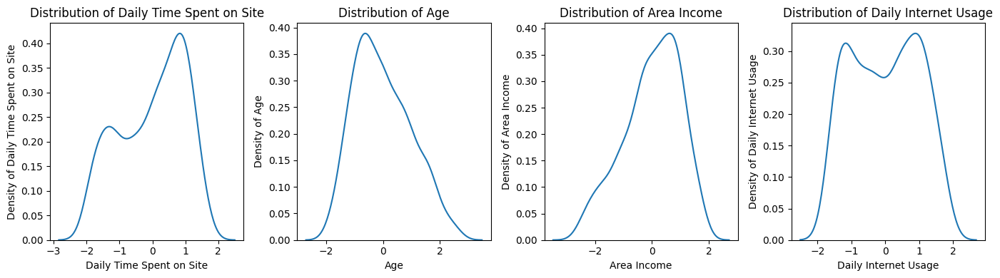

Test Data Distribution Before Scaling: 


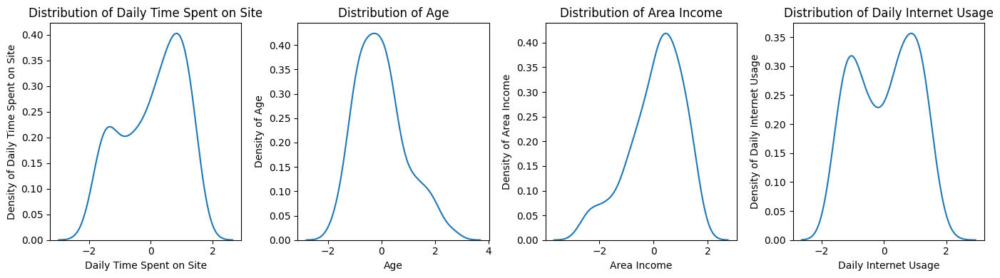

In [90]:
# Checking distribution before scaling
print("Train Data Distribution Before Scaling: ")
plot_dynamic_hisplots_kdeplots(df=X2_train, col_series=columns_to_scale, plot_type='kdeplot', ncols=4, figsize=(14, 4))

print("Test Data Distribution Before Scaling: ")
plot_dynamic_hisplots_kdeplots(df=X2_test, col_series=columns_to_scale, plot_type='kdeplot', ncols=4, figsize=(14, 4))

# **STAGE 3 : MODELLING AND EVALUATION**

## **Case 1 : Without Feature Scaling**

### Helper Function

First we will define some functions that will help us in the process of training and evaluation.

In [ ]:
# Evaluation helper comes from the shared utils package
import time
from sklearn.model_selection import cross_validate, RepeatedStratifiedKFold
from utils.classification_evals_and_tuning import eval_classification

**Additional Information About confusion_matrix in sckit-learn**

Documentation : https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html

The `confusion_matrix` function from scikit-learn is used to compute the confusion matrix, which is a table that summarizes the performance of a classification algorithm. The confusion matrix is typically a 2x2 matrix for binary classification problems.

Here's the breakdown:

```python
from sklearn.metrics import confusion_matrix

# Assuming y_test and y_pred are your true labels and predicted labels, respectively
conf_mat = confusion_matrix(y_test, y_pred)
```

The confusion matrix `conf_mat` will be a 2x2 matrix in the form:

```
[[True Negative  False Positive]
 [False Negative True Positive]]
```

- True Negative (TN): The instances that are actually negative (class 0) and are predicted correctly as negative.
- False Positive (FP): The instances that are actually negative (class 0) but are predicted incorrectly as positive.
- False Negative (FN): The instances that are actually positive (class 1) but are predicted incorrectly as negative.
- True Positive (TP): The instances that are actually positive (class 1) and are predicted correctly as positive.

So, in the confusion matrix `conf_mat`, the elements are arranged as follows:

- `conf_mat[0, 0]`: True Negatives (TN)
- `conf_mat[0, 1]`: False Positives (FP)
- `conf_mat[1, 0]`: False Negatives (FN)
- `conf_mat[1, 1]`: True Positives (TP)

These values help evaluate the performance of your binary classification model. The diagonal elements (`conf_mat[0, 0]` and `conf_mat[1, 1]`) represent correct predictions, while the off-diagonal elements represent errors in predictions.

### Train Vanilla Models

In [92]:
# Import models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

In [298]:
# Initiatialize object for each model
lr1 = LogisticRegression(random_state=42)
knn1 = KNeighborsClassifier()
dt1 = DecisionTreeClassifier(random_state=42)
rf1 = RandomForestClassifier(random_state=42)
gb1 = GradientBoostingClassifier(random_state=42)
xgb1 = XGBClassifier(random_state=42)

models = [lr1, knn1, dt1, rf1, gb1, xgb1]

# Train models
for model in models :
    model.fit(X1_train, y1_train)

### Evaluate Vanilla Models

#### Logistic Regression

Performance Metrics for LogisticRegression:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  77.60 ± 8.02
  Train: 77.75 ± 8.26

PRECISION:
  Test:  85.30 ± 6.04
  Train: 84.05 ± 5.42

RECALL:
  Test:  66.41 ± 13.67
  Train: 67.76 ± 13.45

F1:
  Test:  74.17 ± 10.17
  Train: 74.72 ± 10.21

ROC_AUC:
  Test:  83.09 ± 8.86
  Train: 82.83 ± 8.77

Single Run Metrics:

ACCURACY:
  Test:  91.61
  Train: 89.47

PRECISION:
  Test:  94.07
  Train: 92.02

RECALL:
  Test:  88.19
  Train: 86.46

F1:
  Test:  91.04
  Train: 89.15

ROC_AUC:
  Test:  96.20
  Train: 95.16


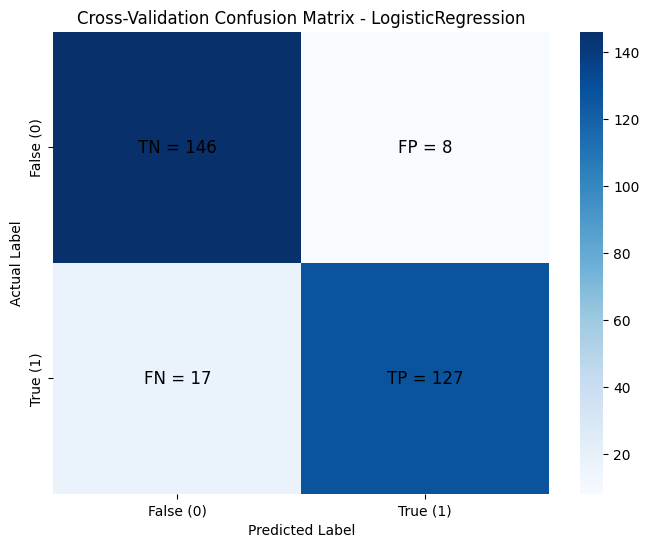

In [299]:
metrics_vanilla_lr1 = eval_classification(model=lr1,
                                         X_train=X1_train,
                                         y_train=y1_train,
                                         X_test=X1_test,
                                         y_test=y1_test)

#### K-Nearest Neighbours

Performance Metrics for KNeighborsClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  66.43 ± 2.49
  Train: 76.53 ± 0.69

PRECISION:
  Test:  67.74 ± 3.93
  Train: 78.42 ± 1.44

RECALL:
  Test:  63.70 ± 4.77
  Train: 73.37 ± 1.51

F1:
  Test:  65.47 ± 2.59
  Train: 75.79 ± 0.67

ROC_AUC:
  Test:  72.01 ± 2.48
  Train: 85.63 ± 0.58

Single Run Metrics:

ACCURACY:
  Test:  65.77
  Train: 76.48

PRECISION:
  Test:  68.10
  Train: 78.22

RECALL:
  Test:  54.86
  Train: 73.49

F1:
  Test:  60.77
  Train: 75.78

ROC_AUC:
  Test:  68.05
  Train: 85.57


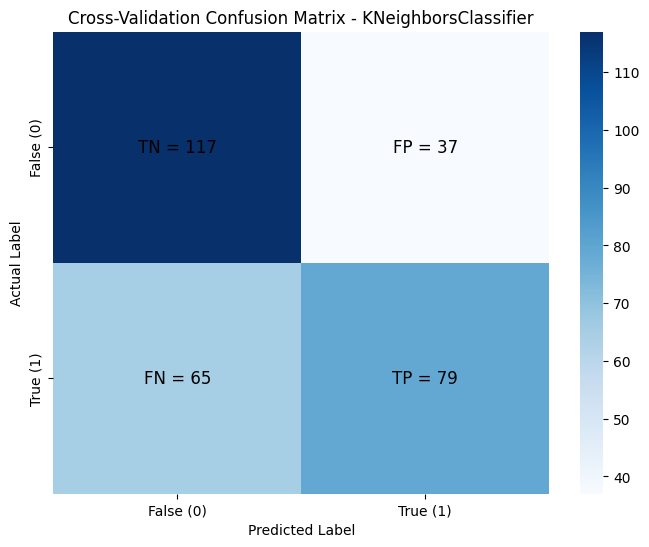

In [300]:
metrics_vanilla_knn1 = eval_classification(model=knn1,
                                         X_train=X1_train,
                                         y_train=y1_train,
                                         X_test=X1_test,
                                         y_test=y1_test)

#### Decision Tree

Performance Metrics for DecisionTreeClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  93.84 ± 0.98
  Train: 100.00 ± 0.00

PRECISION:
  Test:  94.23 ± 2.64
  Train: 100.00 ± 0.00

RECALL:
  Test:  93.56 ± 2.41
  Train: 100.00 ± 0.00

F1:
  Test:  93.84 ± 0.96
  Train: 100.00 ± 0.00

ROC_AUC:
  Test:  93.84 ± 0.98
  Train: 100.00 ± 0.00

Single Run Metrics:

ACCURACY:
  Test:  94.30
  Train: 100.00

PRECISION:
  Test:  92.62
  Train: 100.00

RECALL:
  Test:  95.83
  Train: 100.00

F1:
  Test:  94.20
  Train: 100.00

ROC_AUC:
  Test:  94.35
  Train: 100.00


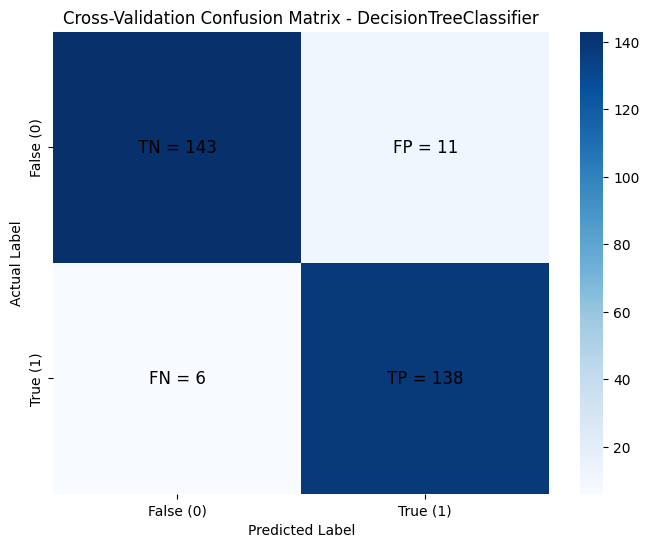

In [301]:
metrics_vanilla_dt1 = eval_classification(model=dt1,
                                         X_train=X1_train,
                                         y_train=y1_train,
                                         X_test=X1_test,
                                         y_test=y1_test)

#### Random Forest

Performance Metrics for RandomForestClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  95.62 ± 1.35
  Train: 100.00 ± 0.00

PRECISION:
  Test:  96.35 ± 1.94
  Train: 100.00 ± 0.00

RECALL:
  Test:  94.91 ± 2.50
  Train: 100.00 ± 0.00

F1:
  Test:  95.59 ± 1.37
  Train: 100.00 ± 0.00

ROC_AUC:
  Test:  98.94 ± 0.47
  Train: 100.00 ± 0.00

Single Run Metrics:

ACCURACY:
  Test:  97.99
  Train: 100.00

PRECISION:
  Test:  98.59
  Train: 100.00

RECALL:
  Test:  97.22
  Train: 100.00

F1:
  Test:  97.90
  Train: 100.00

ROC_AUC:
  Test:  99.15
  Train: 100.00


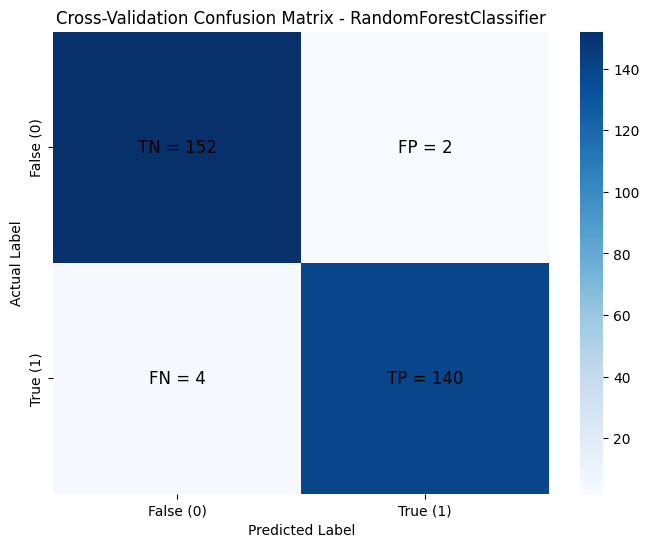

In [302]:
metrics_vanilla_rf1 = eval_classification(model=rf1,
                                         X_train=X1_train,
                                         y_train=y1_train,
                                         X_test=X1_test,
                                         y_test=y1_test)

#### GradientBoost

Performance Metrics for GradientBoostingClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  95.05 ± 1.41
  Train: 99.95 ± 0.08

PRECISION:
  Test:  95.77 ± 2.09
  Train: 100.00 ± 0.00

RECALL:
  Test:  94.33 ± 2.60
  Train: 99.90 ± 0.16

F1:
  Test:  95.01 ± 1.44
  Train: 99.95 ± 0.08

ROC_AUC:
  Test:  98.73 ± 0.52
  Train: 100.00 ± 0.00

Single Run Metrics:

ACCURACY:
  Test:  97.32
  Train: 99.86

PRECISION:
  Test:  97.22
  Train: 100.00

RECALL:
  Test:  97.22
  Train: 99.71

F1:
  Test:  97.22
  Train: 99.86

ROC_AUC:
  Test:  98.98
  Train: 99.99


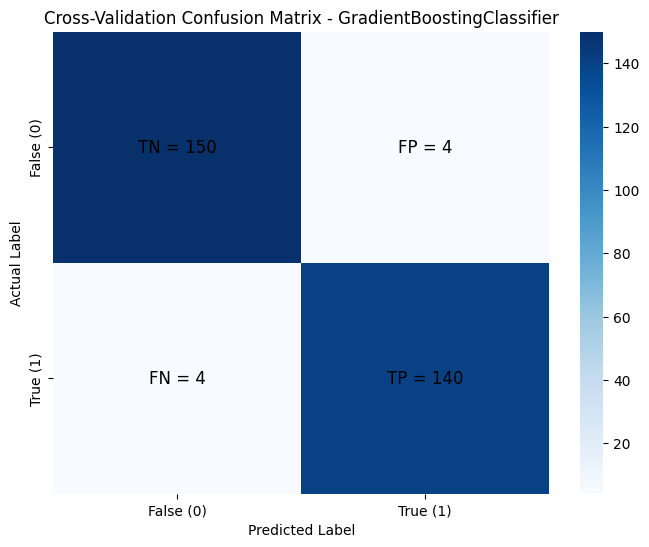

In [303]:
metrics_vanilla_gb1 = eval_classification(model=gb1,
                                         X_train=X1_train,
                                         y_train=y1_train,
                                         X_test=X1_test,
                                         y_test=y1_test)

#### XGBoost

Performance Metrics for XGBClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  94.09 ± 1.37
  Train: 100.00 ± 0.00

PRECISION:
  Test:  94.59 ± 2.47
  Train: 100.00 ± 0.00

RECALL:
  Test:  93.66 ± 3.28
  Train: 100.00 ± 0.00

F1:
  Test:  94.05 ± 1.41
  Train: 100.00 ± 0.00

ROC_AUC:
  Test:  98.75 ± 0.59
  Train: 100.00 ± 0.00

Single Run Metrics:

ACCURACY:
  Test:  96.98
  Train: 100.00

PRECISION:
  Test:  97.87
  Train: 100.00

RECALL:
  Test:  95.83
  Train: 100.00

F1:
  Test:  96.84
  Train: 100.00

ROC_AUC:
  Test:  99.27
  Train: 100.00


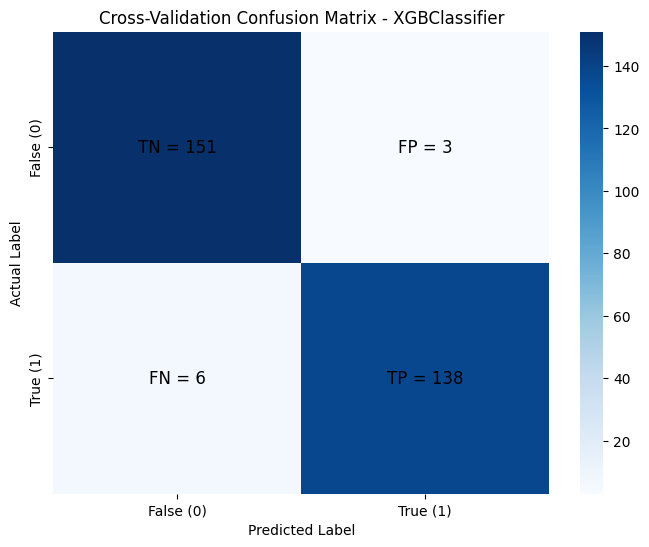

In [304]:
metrics_vanilla_xgb1 = eval_classification(model=xgb1,
                                         X_train=X1_train,
                                         y_train=y1_train,
                                         X_test=X1_test,
                                         y_test=y1_test)

> There are some overfitting models, to tackle this issue hyperparameter tuning will be done.

In [305]:
# # Printing metrics in form of classification report (Additional)
# from sklearn.metrics import classification_report

# def display_classification_reports(model_for_report):
#     model_for_report.fit(x1_train, y1_train)
#     y_pred = model_for_report.predict(x1_test)
#     print("Classification Report for", type(model_for_report).__name__)
#     print(classification_report(y1_test, y_pred))

# # Evaluate and print classification reports for all models
# for model in models:
#     display_classification_reports(model)

### Hyperparameter Tuning

In [306]:
# ?Pipeline

In [ ]:
# Pipeline and hyperparameter helpers come from the shared utils package
from utils.classification_evals_and_tuning import (
    get_model_pipeline,
    get_hyperparameters,
    tune_single_model,
    tune_all_models
)

#### Tuning Logistic Regression


Evaluating lr__C for logisticregression...
lr__C: 0.001; train: 0.889; test: 0.919; diff: -0.031
lr__C: 0.011090909090909092; train: 0.895; test: 0.916; diff: -0.021
lr__C: 0.021181818181818184; train: 0.895; test: 0.916; diff: -0.021
lr__C: 0.03127272727272727; train: 0.895; test: 0.916; diff: -0.021
lr__C: 0.041363636363636366; train: 0.895; test: 0.916; diff: -0.021
lr__C: 0.05145454545454546; train: 0.895; test: 0.916; diff: -0.021
lr__C: 0.06154545454545455; train: 0.895; test: 0.916; diff: -0.021
lr__C: 0.07163636363636364; train: 0.895; test: 0.916; diff: -0.021
lr__C: 0.08172727272727273; train: 0.895; test: 0.916; diff: -0.021
lr__C: 0.09181818181818183; train: 0.895; test: 0.916; diff: -0.021
lr__C: 0.10190909090909092; train: 0.895; test: 0.916; diff: -0.021
lr__C: 0.112; train: 0.895; test: 0.916; diff: -0.021
lr__C: 0.1220909090909091; train: 0.895; test: 0.916; diff: -0.021
lr__C: 0.13218181818181818; train: 0.893; test: 0.909; diff: -0.016
lr__C: 0.14227272727272727; tr

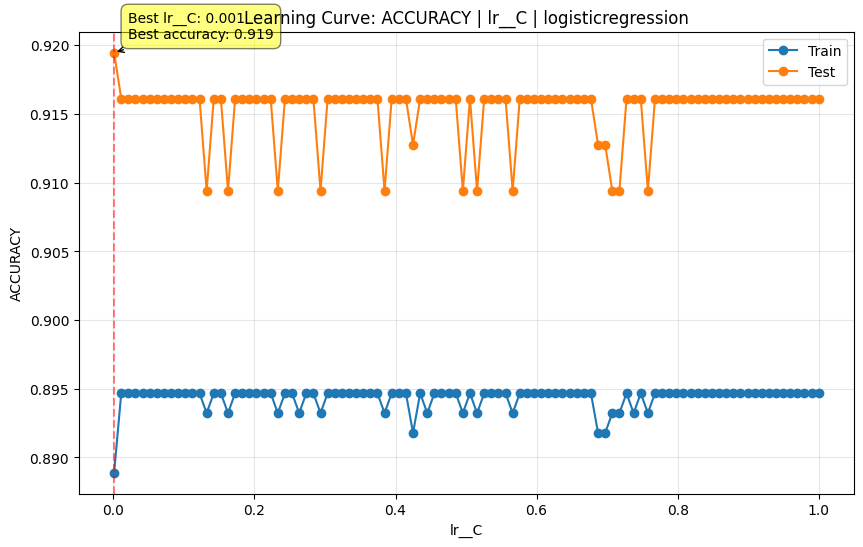


Evaluating lr__solver for logisticregression...
lr__solver: newton-cg; train: 0.962; test: 0.970; diff: -0.007
lr__solver: lbfgs; train: 0.895; test: 0.916; diff: -0.021
lr__solver: newton-cholesky; train: 0.895; test: 0.916; diff: -0.021
lr__solver: liblinear; train: 0.499; test: 0.517; diff: -0.018


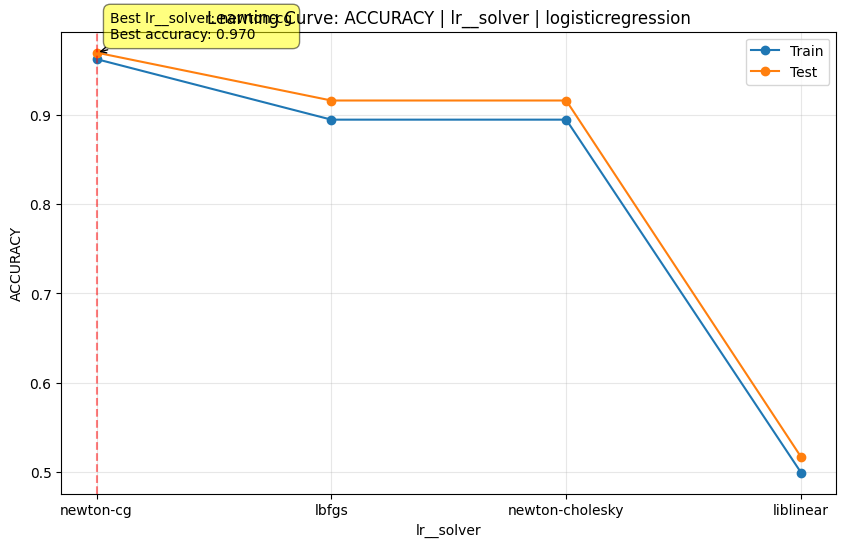


Evaluating lr__max_iter for logisticregression...
lr__max_iter: 1000; train: 0.895; test: 0.916; diff: -0.021
lr__max_iter: 5000; train: 0.895; test: 0.916; diff: -0.021
lr__max_iter: 10000; train: 0.895; test: 0.916; diff: -0.021


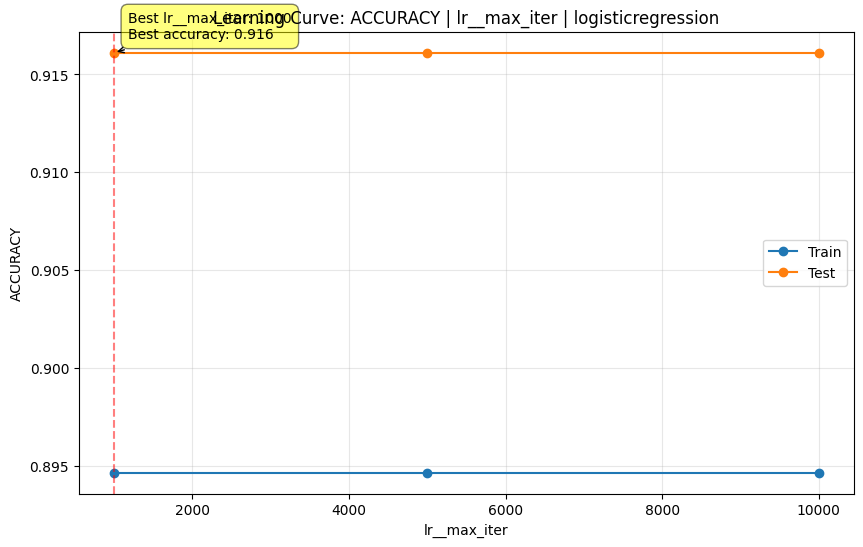

Fitting 15 folds for each of 1200 candidates, totalling 18000 fits

Grid Search Results for logisticregression:
--------------------------------------------------
Total Fit Time: 74.150s
Best accuracy: 0.949

Best Parameters:
lr__C: 0.3945454545454546
lr__max_iter: 1000
lr__penalty: l2
lr__solver: newton-cg



In [308]:
lr1_model, lr1_time = tune_single_model(
    model_name='logisticregression',
    X_train=X1_train,
    y_train=y1_train,
    X_test=X1_test,
    y_test=y1_test,
    scoring='accuracy',
    plot_learning_curves=True
)

#### Tuning K-Nearest Neighbours


Evaluating knn__n_neighbors for knn...
knn__n_neighbors: 1; train: 1.000; test: 0.628; diff: 0.372
knn__n_neighbors: 2; train: 0.824; test: 0.641; diff: 0.183
knn__n_neighbors: 3; train: 0.814; test: 0.644; diff: 0.170
knn__n_neighbors: 4; train: 0.771; test: 0.681; diff: 0.089
knn__n_neighbors: 5; train: 0.765; test: 0.658; diff: 0.107
knn__n_neighbors: 6; train: 0.743; test: 0.674; diff: 0.069
knn__n_neighbors: 7; train: 0.743; test: 0.688; diff: 0.055
knn__n_neighbors: 8; train: 0.740; test: 0.668; diff: 0.072
knn__n_neighbors: 9; train: 0.753; test: 0.681; diff: 0.072
knn__n_neighbors: 10; train: 0.742; test: 0.674; diff: 0.067
knn__n_neighbors: 11; train: 0.747; test: 0.668; diff: 0.080
knn__n_neighbors: 12; train: 0.745; test: 0.685; diff: 0.060
knn__n_neighbors: 13; train: 0.746; test: 0.685; diff: 0.061
knn__n_neighbors: 14; train: 0.750; test: 0.668; diff: 0.083
knn__n_neighbors: 15; train: 0.737; test: 0.664; diff: 0.073
knn__n_neighbors: 16; train: 0.733; test: 0.664; diff:

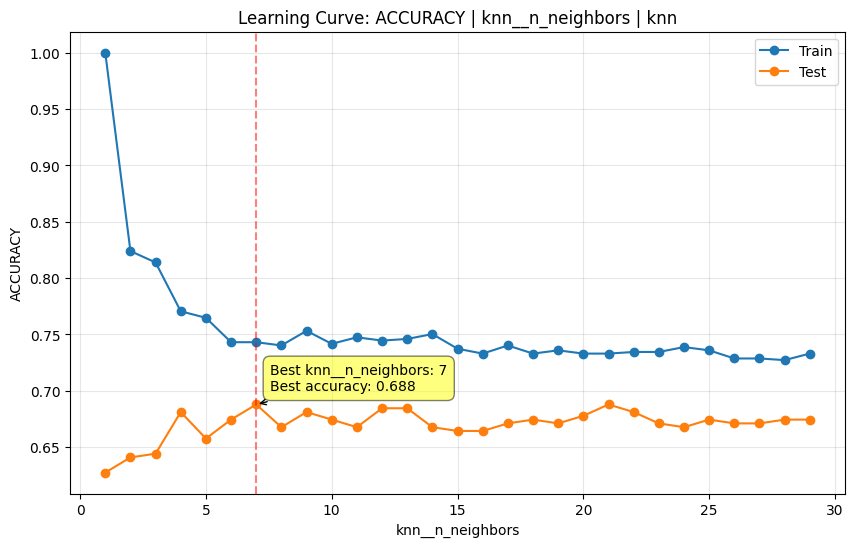


Evaluating knn__weights for knn...
knn__weights: uniform; train: 0.765; test: 0.658; diff: 0.107
knn__weights: distance; train: 1.000; test: 0.634; diff: 0.366


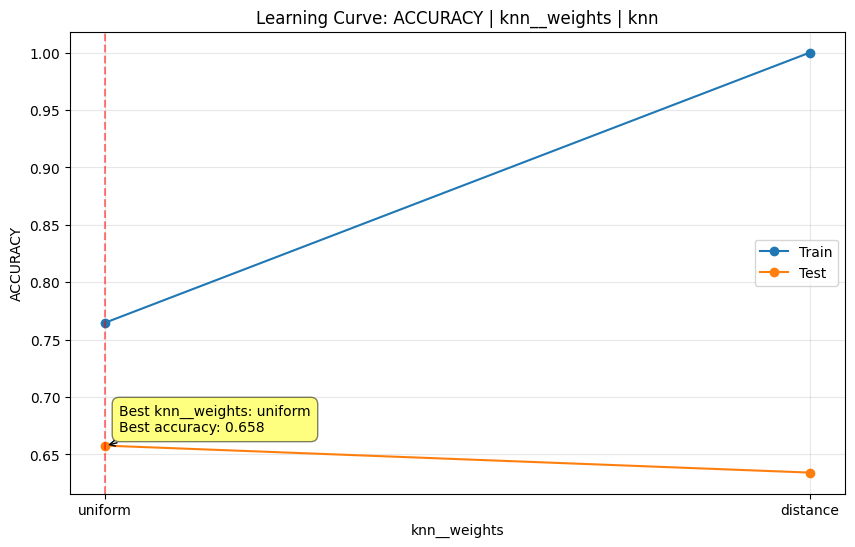


Evaluating knn__p for knn...
knn__p: 1; train: 0.765; test: 0.658; diff: 0.107
knn__p: 2; train: 0.765; test: 0.658; diff: 0.107


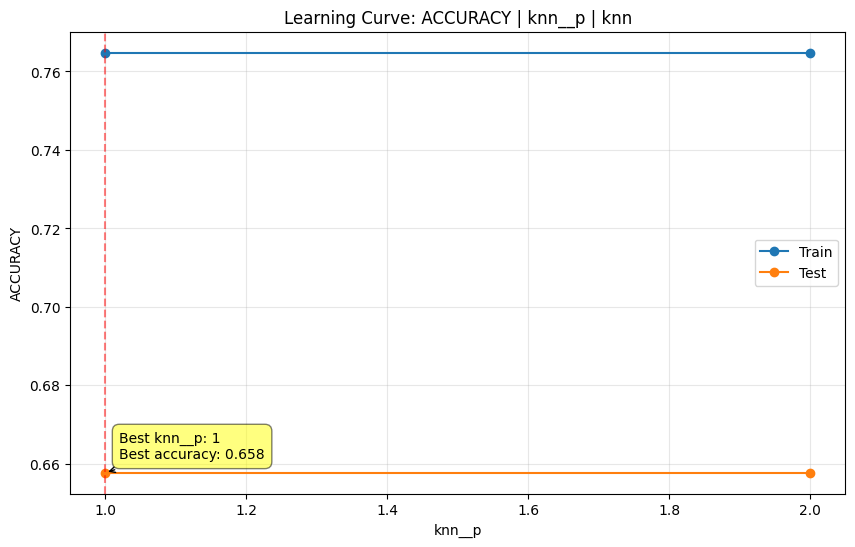


Evaluating knn__algorithm for knn...
knn__algorithm: auto; train: 0.765; test: 0.658; diff: 0.107
knn__algorithm: ball_tree; train: 0.765; test: 0.658; diff: 0.107
knn__algorithm: kd_tree; train: 0.765; test: 0.658; diff: 0.107
knn__algorithm: brute; train: 0.765; test: 0.658; diff: 0.107


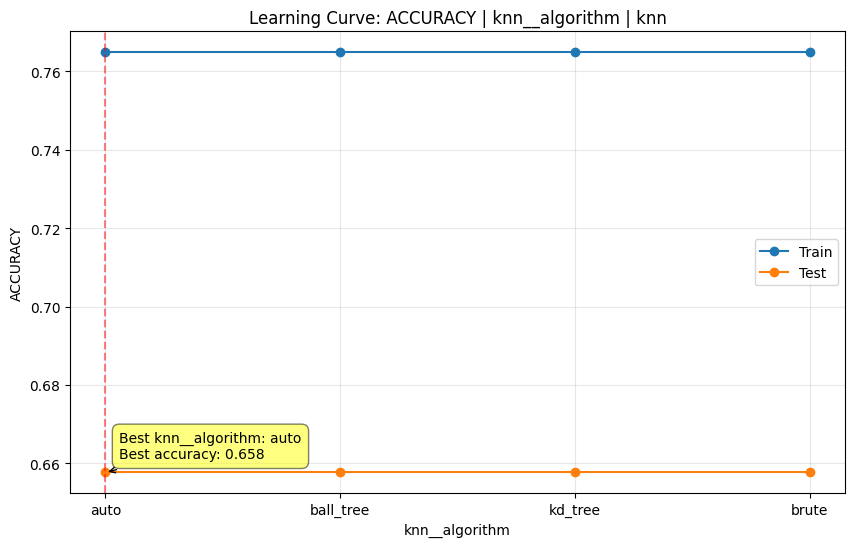


Evaluating knn__leaf_size for knn...
knn__leaf_size: 10; train: 0.765; test: 0.658; diff: 0.107
knn__leaf_size: 20; train: 0.765; test: 0.658; diff: 0.107
knn__leaf_size: 35; train: 0.765; test: 0.658; diff: 0.107


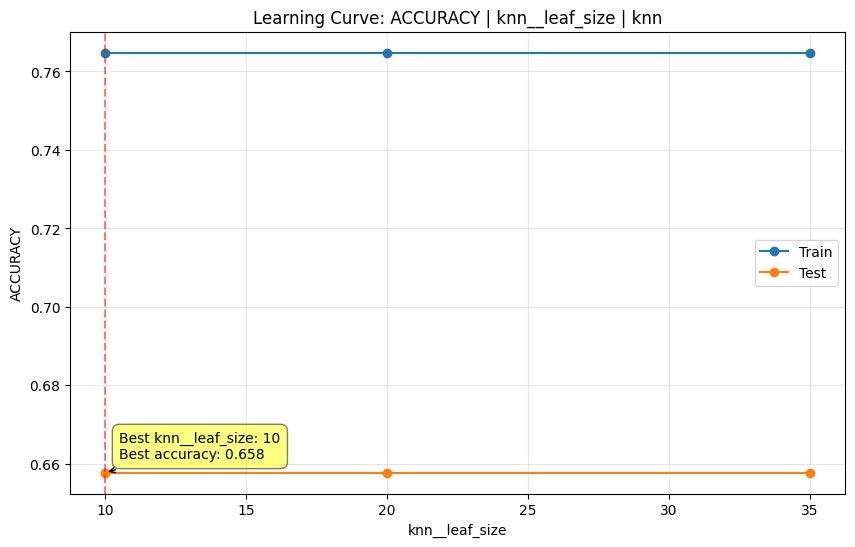

Fitting 15 folds for each of 1392 candidates, totalling 20880 fits

Grid Search Results for knn:
--------------------------------------------------
Total Fit Time: 52.941s
Best accuracy: 0.723

Best Parameters:
knn__algorithm: auto
knn__leaf_size: 10
knn__n_neighbors: 28
knn__p: 1
knn__weights: uniform



In [309]:
knn1_model, knn1_time = tune_single_model(
    model_name='knn',
    X_train=X1_train,
    y_train=y1_train,
    X_test=X1_test,
    y_test=y1_test,
    scoring='accuracy',
    plot_learning_curves=True
)

#### Tuning Decision Tree


Evaluating dt__criterion for decisiontree...
dt__criterion: entropy; train: 1.000; test: 0.973; diff: 0.027
dt__criterion: gini; train: 1.000; test: 0.943; diff: 0.057


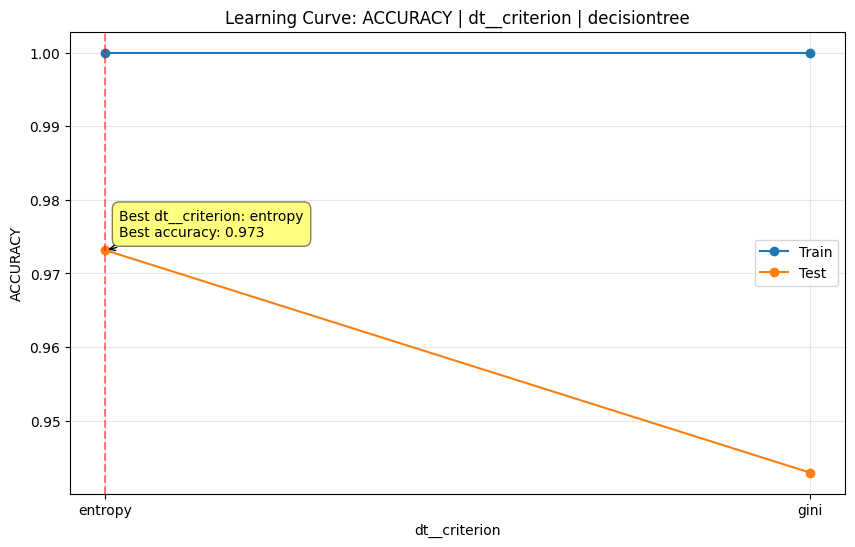


Evaluating dt__max_depth for decisiontree...
dt__max_depth: 1; train: 0.902; test: 0.903; diff: -0.001
dt__max_depth: 2; train: 0.935; test: 0.940; diff: -0.005
dt__max_depth: 3; train: 0.965; test: 0.960; diff: 0.006
dt__max_depth: 4; train: 0.974; test: 0.963; diff: 0.011
dt__max_depth: 5; train: 0.981; test: 0.963; diff: 0.018
dt__max_depth: 6; train: 0.984; test: 0.960; diff: 0.024
dt__max_depth: 7; train: 0.988; test: 0.960; diff: 0.029
dt__max_depth: 8; train: 0.990; test: 0.960; diff: 0.030
dt__max_depth: 9; train: 0.993; test: 0.953; diff: 0.040
dt__max_depth: 10; train: 0.994; test: 0.950; diff: 0.045
dt__max_depth: 11; train: 0.997; test: 0.950; diff: 0.047
dt__max_depth: 12; train: 0.999; test: 0.946; diff: 0.052
dt__max_depth: 13; train: 1.000; test: 0.943; diff: 0.057
dt__max_depth: 14; train: 1.000; test: 0.943; diff: 0.057
dt__max_depth: 15; train: 1.000; test: 0.943; diff: 0.057
dt__max_depth: 16; train: 1.000; test: 0.943; diff: 0.057
dt__max_depth: 17; train: 1.000; 

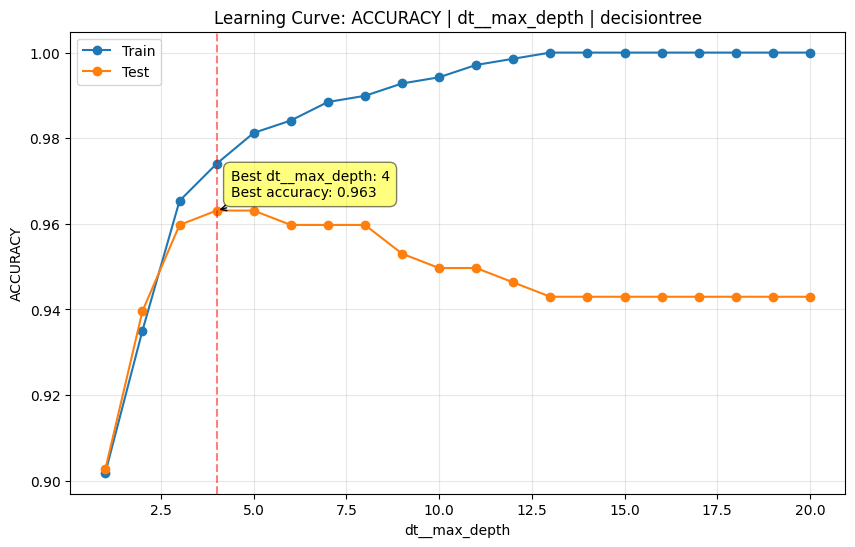


Evaluating dt__min_samples_split for decisiontree...
dt__min_samples_split: 2; train: 1.000; test: 0.943; diff: 0.057
dt__min_samples_split: 7; train: 0.988; test: 0.953; diff: 0.035
dt__min_samples_split: 12; train: 0.988; test: 0.953; diff: 0.035
dt__min_samples_split: 18; train: 0.978; test: 0.960; diff: 0.019
dt__min_samples_split: 23; train: 0.975; test: 0.953; diff: 0.022
dt__min_samples_split: 28; train: 0.970; test: 0.953; diff: 0.017
dt__min_samples_split: 34; train: 0.970; test: 0.953; diff: 0.017
dt__min_samples_split: 39; train: 0.970; test: 0.953; diff: 0.017
dt__min_samples_split: 44; train: 0.970; test: 0.953; diff: 0.017
dt__min_samples_split: 50; train: 0.947; test: 0.946; diff: 0.000


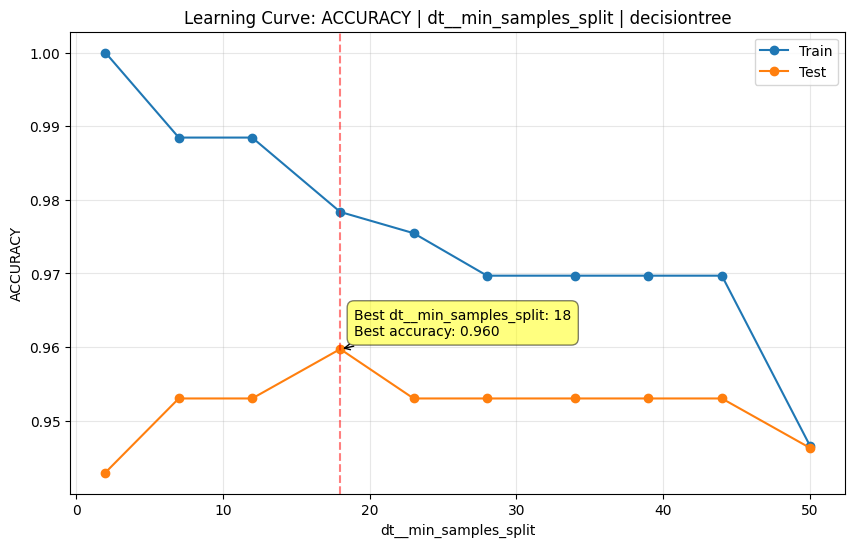


Evaluating dt__min_samples_leaf for decisiontree...
dt__min_samples_leaf: 1; train: 1.000; test: 0.943; diff: 0.057
dt__min_samples_leaf: 6; train: 0.958; test: 0.956; diff: 0.002
dt__min_samples_leaf: 11; train: 0.957; test: 0.953; diff: 0.004
dt__min_samples_leaf: 17; train: 0.957; test: 0.953; diff: 0.004
dt__min_samples_leaf: 22; train: 0.955; test: 0.956; diff: -0.001
dt__min_samples_leaf: 28; train: 0.934; test: 0.943; diff: -0.009
dt__min_samples_leaf: 33; train: 0.932; test: 0.943; diff: -0.011
dt__min_samples_leaf: 39; train: 0.928; test: 0.936; diff: -0.008
dt__min_samples_leaf: 44; train: 0.924; test: 0.933; diff: -0.009
dt__min_samples_leaf: 50; train: 0.916; test: 0.930; diff: -0.013


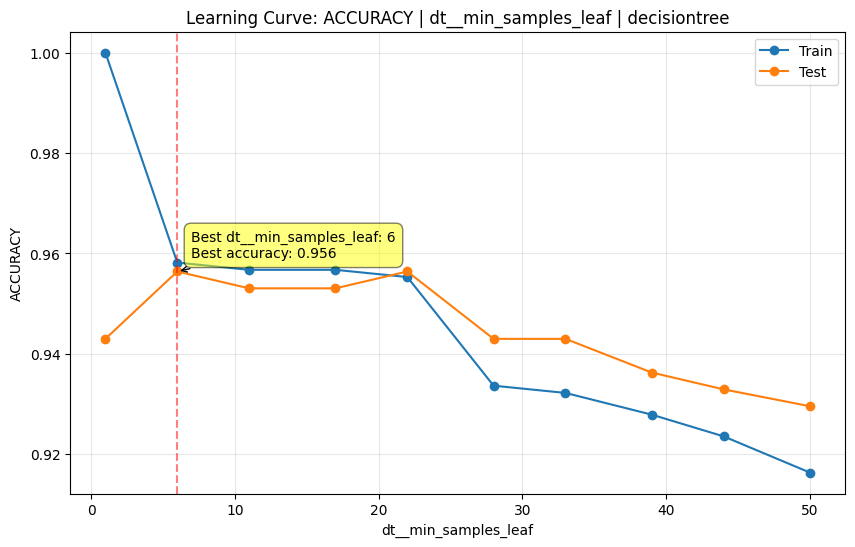

Fitting 15 folds for each of 4000 candidates, totalling 60000 fits

Grid Search Results for decisiontree:
--------------------------------------------------
Total Fit Time: 44.397s
Best accuracy: 0.942

Best Parameters:
dt__criterion: gini
dt__max_depth: 7
dt__max_features: sqrt
dt__min_samples_leaf: 1
dt__min_samples_split: 12
dt__splitter: best



In [310]:
dt1_model, dt1_time = tune_single_model(
    model_name='decisiontree',
    X_train=X1_train,
    y_train=y1_train,
    X_test=X1_test,
    y_test=y1_test,
    scoring='accuracy',
    plot_learning_curves=True
)

#### Tuning Random Forest


Evaluating rf__n_estimators for randomforest...
rf__n_estimators: 10; train: 0.999; test: 0.973; diff: 0.025
rf__n_estimators: 20; train: 0.999; test: 0.973; diff: 0.025
rf__n_estimators: 30; train: 1.000; test: 0.980; diff: 0.020
rf__n_estimators: 40; train: 1.000; test: 0.987; diff: 0.013
rf__n_estimators: 50; train: 1.000; test: 0.987; diff: 0.013
rf__n_estimators: 75; train: 1.000; test: 0.987; diff: 0.013
rf__n_estimators: 100; train: 1.000; test: 0.980; diff: 0.020


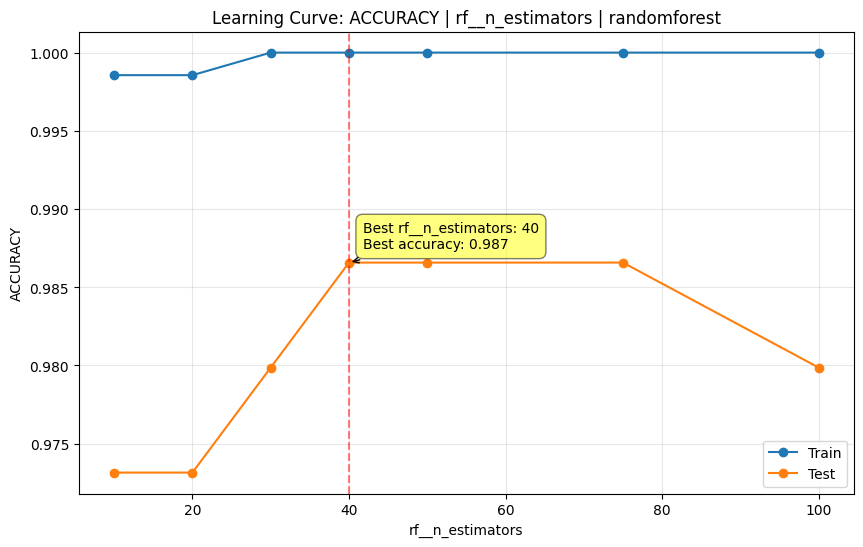


Evaluating rf__criterion for randomforest...
rf__criterion: entropy; train: 1.000; test: 0.980; diff: 0.020
rf__criterion: gini; train: 1.000; test: 0.980; diff: 0.020


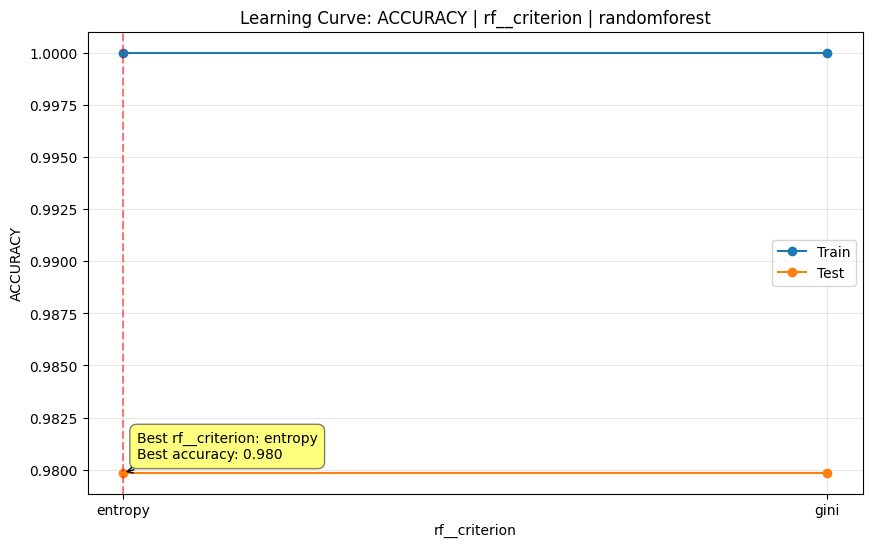


Evaluating rf__max_depth for randomforest...
rf__max_depth: 1; train: 0.947; test: 0.946; diff: 0.000
rf__max_depth: 3; train: 0.965; test: 0.956; diff: 0.009
rf__max_depth: 5; train: 0.978; test: 0.980; diff: -0.002
rf__max_depth: 7; train: 0.993; test: 0.980; diff: 0.013
rf__max_depth: 9; train: 0.994; test: 0.977; diff: 0.018
rf__max_depth: 11; train: 0.996; test: 0.980; diff: 0.016
rf__max_depth: 13; train: 1.000; test: 0.980; diff: 0.020
rf__max_depth: 15; train: 1.000; test: 0.980; diff: 0.020
rf__max_depth: 17; train: 1.000; test: 0.980; diff: 0.020
rf__max_depth: 20; train: 1.000; test: 0.980; diff: 0.020


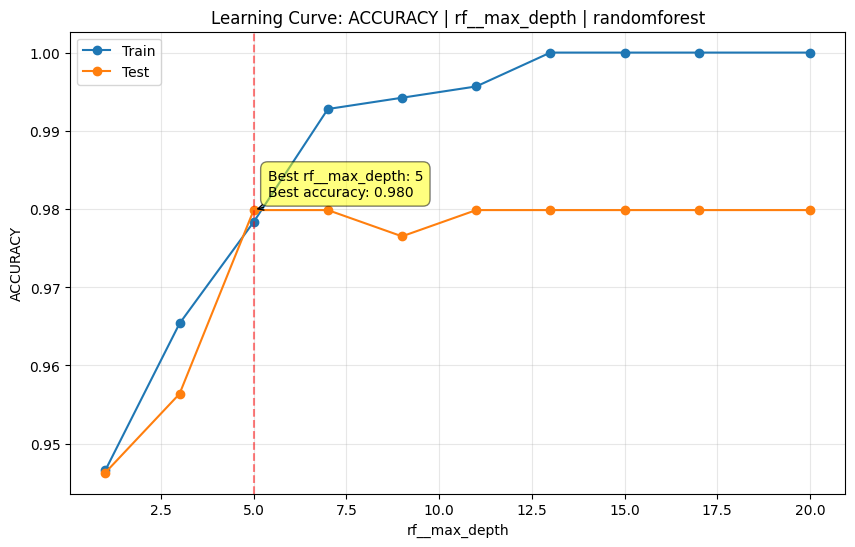


Evaluating rf__min_samples_split for randomforest...
rf__min_samples_split: 2; train: 1.000; test: 0.980; diff: 0.020
rf__min_samples_split: 5; train: 0.991; test: 0.983; diff: 0.008
rf__min_samples_split: 7; train: 0.988; test: 0.977; diff: 0.012
rf__min_samples_split: 10; train: 0.987; test: 0.980; diff: 0.007


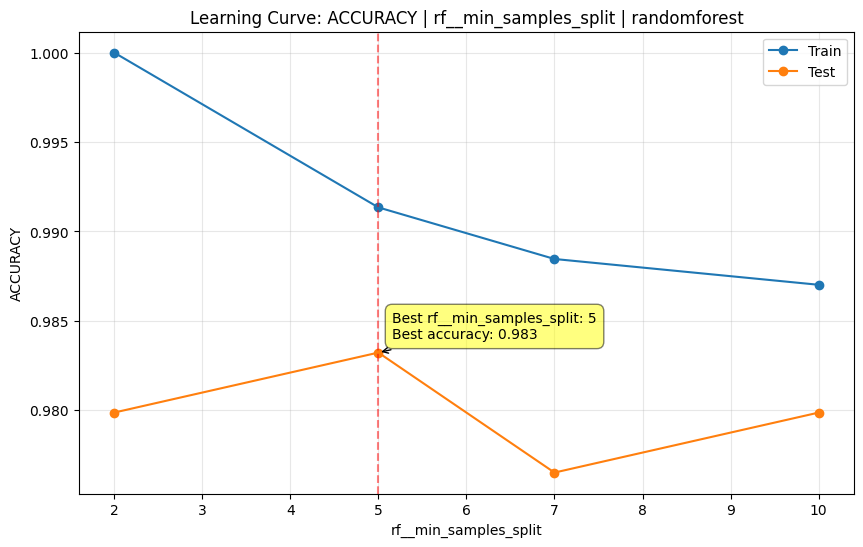


Evaluating rf__max_features for randomforest...
rf__max_features: sqrt; train: 1.000; test: 0.980; diff: 0.020
rf__max_features: log2; train: 1.000; test: 0.980; diff: 0.020


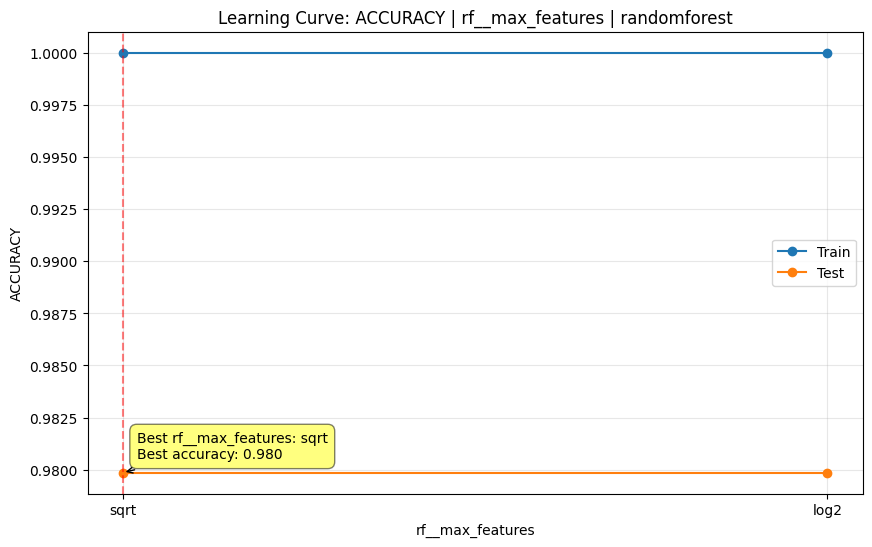


Evaluating rf__min_samples_leaf for randomforest...
rf__min_samples_leaf: 1; train: 1.000; test: 0.980; diff: 0.020
rf__min_samples_leaf: 2; train: 0.990; test: 0.980; diff: 0.010
rf__min_samples_leaf: 4; train: 0.977; test: 0.980; diff: -0.003
rf__min_samples_leaf: 6; train: 0.973; test: 0.977; diff: -0.004


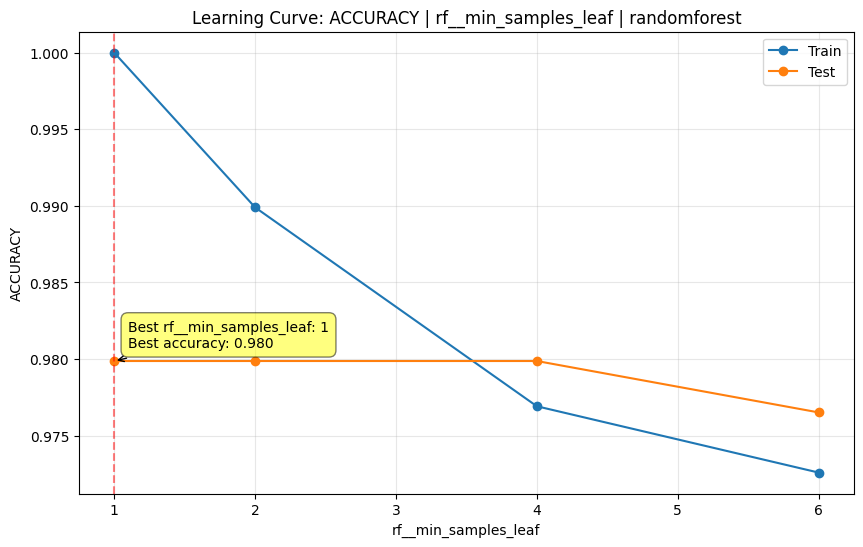

Fitting 15 folds for each of 4480 candidates, totalling 67200 fits

Grid Search Results for randomforest:
--------------------------------------------------
Total Fit Time: 638.625s
Best accuracy: 0.961

Best Parameters:
rf__criterion: gini
rf__max_depth: 9
rf__max_features: sqrt
rf__min_samples_leaf: 2
rf__min_samples_split: 2
rf__n_estimators: 100



In [311]:
rf1_model, rf1_time = tune_single_model(
    model_name='randomforest',
    X_train=X1_train,
    y_train=y1_train,
    X_test=X1_test,
    y_test=y1_test,
    scoring='accuracy',
    plot_learning_curves=True
)

#### Tuning GradientBoost


Evaluating gb__n_estimators for gb...
gb__n_estimators: 25; train: 0.980; test: 0.963; diff: 0.017
gb__n_estimators: 50; train: 0.993; test: 0.973; diff: 0.020
gb__n_estimators: 100; train: 0.999; test: 0.973; diff: 0.025
gb__n_estimators: 200; train: 1.000; test: 0.973; diff: 0.027


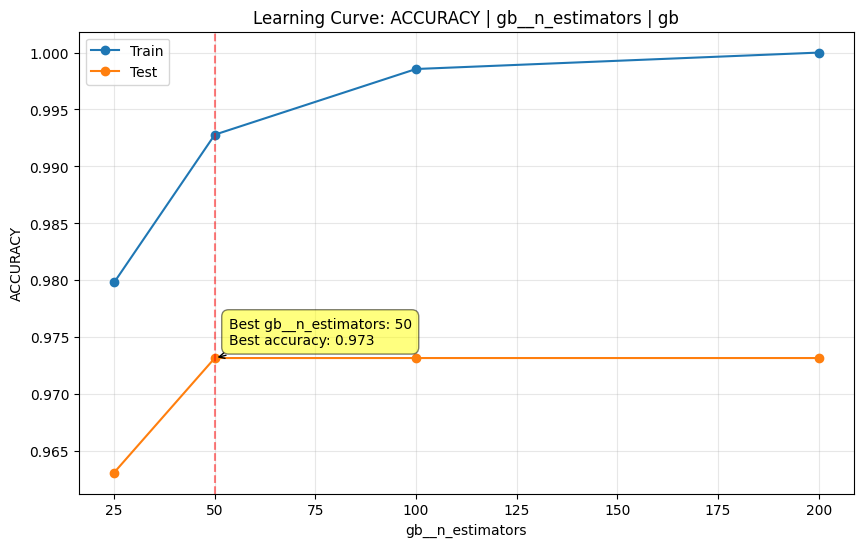


Evaluating gb__criterion for gb...
gb__criterion: friedman_mse; train: 0.999; test: 0.973; diff: 0.025
gb__criterion: squared_error; train: 0.999; test: 0.973; diff: 0.025


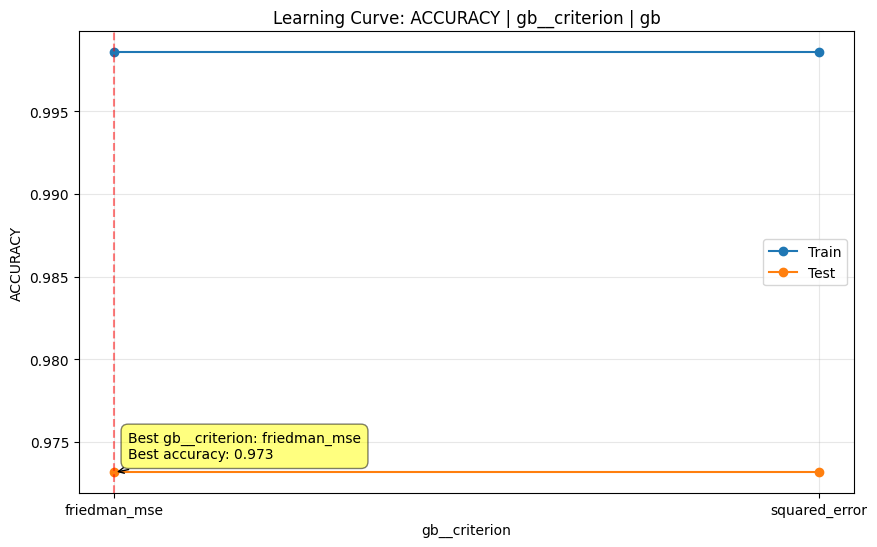


Evaluating gb__max_depth for gb...
gb__max_depth: 1; train: 0.968; test: 0.973; diff: -0.005
gb__max_depth: 3; train: 0.999; test: 0.973; diff: 0.025
gb__max_depth: 4; train: 1.000; test: 0.966; diff: 0.034
gb__max_depth: 5; train: 1.000; test: 0.970; diff: 0.030
gb__max_depth: 7; train: 1.000; test: 0.950; diff: 0.050


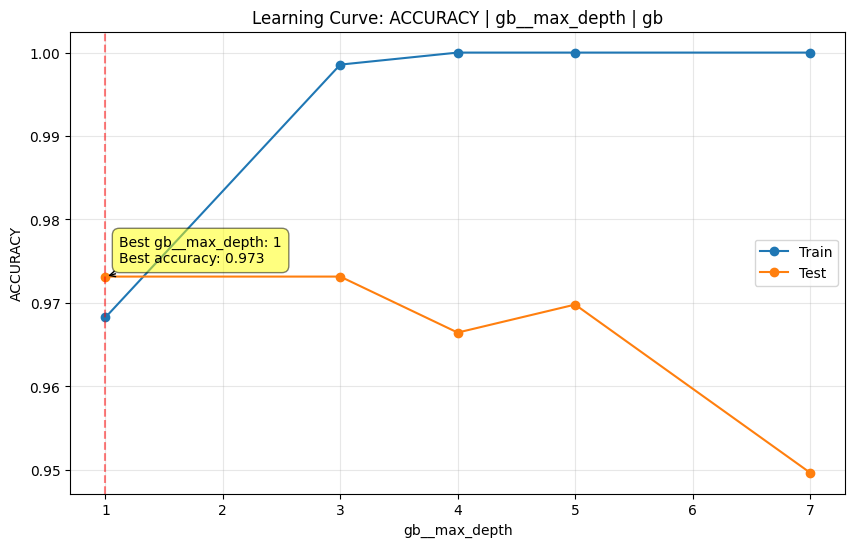


Evaluating gb__min_samples_split for gb...
gb__min_samples_split: 2; train: 0.999; test: 0.973; diff: 0.025
gb__min_samples_split: 3; train: 0.999; test: 0.970; diff: 0.029
gb__min_samples_split: 5; train: 0.999; test: 0.977; diff: 0.022
gb__min_samples_split: 7; train: 0.999; test: 0.973; diff: 0.025


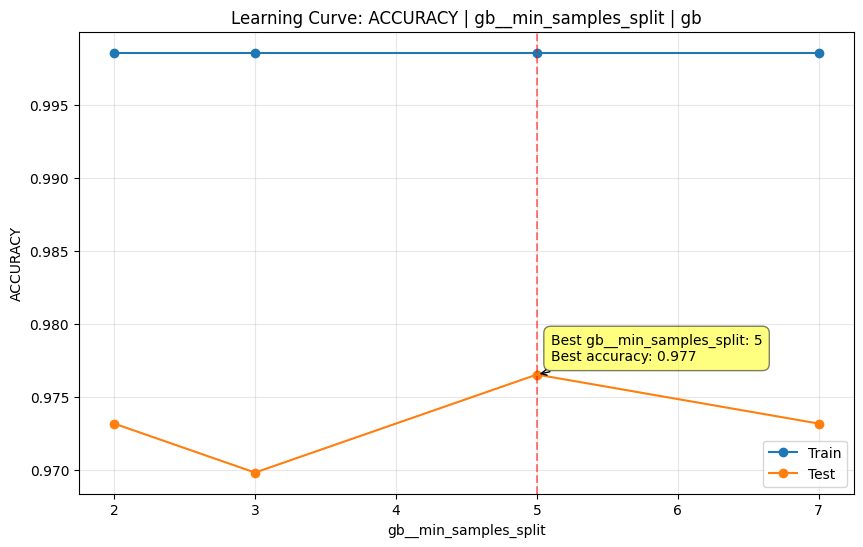


Evaluating gb__min_samples_leaf for gb...
gb__min_samples_leaf: 2; train: 0.999; test: 0.970; diff: 0.029
gb__min_samples_leaf: 3; train: 0.999; test: 0.970; diff: 0.029
gb__min_samples_leaf: 5; train: 0.999; test: 0.970; diff: 0.029
gb__min_samples_leaf: 7; train: 0.999; test: 0.970; diff: 0.029


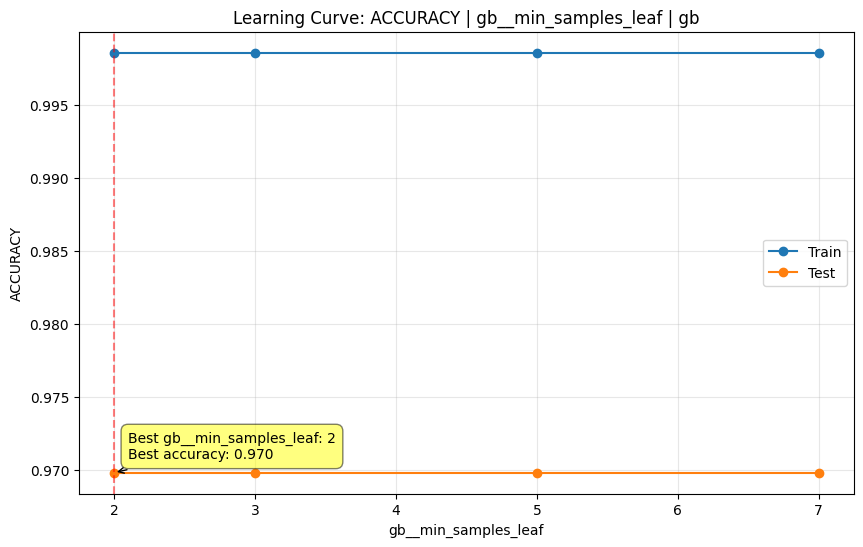

Fitting 15 folds for each of 640 candidates, totalling 9600 fits

Grid Search Results for gb:
--------------------------------------------------
Total Fit Time: 197.475s
Best accuracy: 0.958

Best Parameters:
gb__criterion: friedman_mse
gb__loss: exponential
gb__max_depth: 4
gb__max_features: sqrt
gb__min_samples_leaf: 3
gb__min_samples_split: 7
gb__n_estimators: 50



In [312]:
gb1_model, gb1_time = tune_single_model(
    model_name='gb',
    X_train=X1_train,
    y_train=y1_train,
    X_test=X1_test,
    y_test=y1_test,
    scoring='accuracy',
    plot_learning_curves=True
)

#### Tuning XGBoost


Evaluating xgb__eta for xgboost...
xgb__eta: 0.1; train: 0.999; test: 0.966; diff: 0.032
xgb__eta: 0.1473684210526316; train: 1.000; test: 0.960; diff: 0.040
xgb__eta: 0.19473684210526315; train: 1.000; test: 0.963; diff: 0.037
xgb__eta: 0.24210526315789474; train: 1.000; test: 0.966; diff: 0.034
xgb__eta: 0.2894736842105263; train: 1.000; test: 0.966; diff: 0.034
xgb__eta: 0.33684210526315794; train: 1.000; test: 0.970; diff: 0.030
xgb__eta: 0.38421052631578945; train: 1.000; test: 0.966; diff: 0.034
xgb__eta: 0.43157894736842106; train: 1.000; test: 0.966; diff: 0.034
xgb__eta: 0.4789473684210527; train: 1.000; test: 0.963; diff: 0.037
xgb__eta: 0.5263157894736842; train: 1.000; test: 0.966; diff: 0.034
xgb__eta: 0.5736842105263158; train: 1.000; test: 0.970; diff: 0.030
xgb__eta: 0.6210526315789474; train: 1.000; test: 0.966; diff: 0.034
xgb__eta: 0.6684210526315789; train: 1.000; test: 0.963; diff: 0.037
xgb__eta: 0.7157894736842105; train: 1.000; test: 0.966; diff: 0.034
xgb__eta

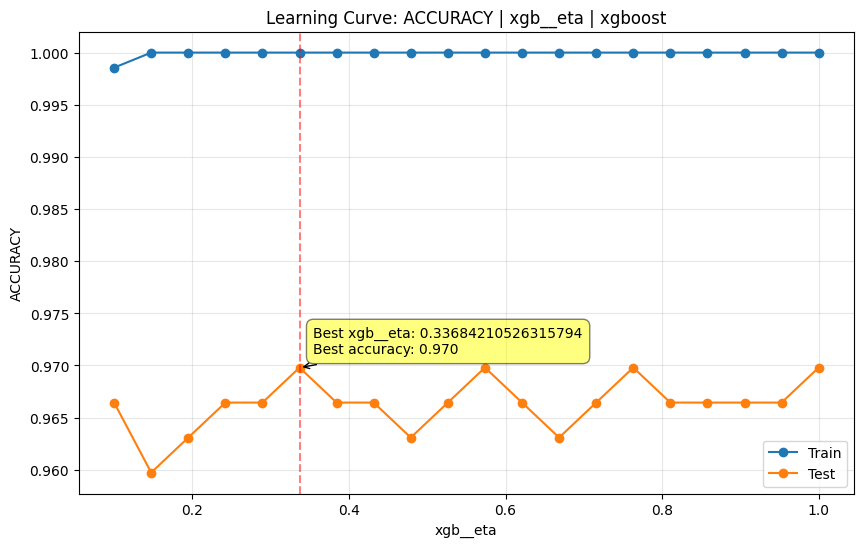


Evaluating xgb__n_estimators for xgboost...
xgb__n_estimators: 10; train: 0.981; test: 0.966; diff: 0.015
xgb__n_estimators: 25; train: 0.999; test: 0.963; diff: 0.035
xgb__n_estimators: 50; train: 1.000; test: 0.966; diff: 0.034
xgb__n_estimators: 75; train: 1.000; test: 0.966; diff: 0.034
xgb__n_estimators: 100; train: 1.000; test: 0.970; diff: 0.030


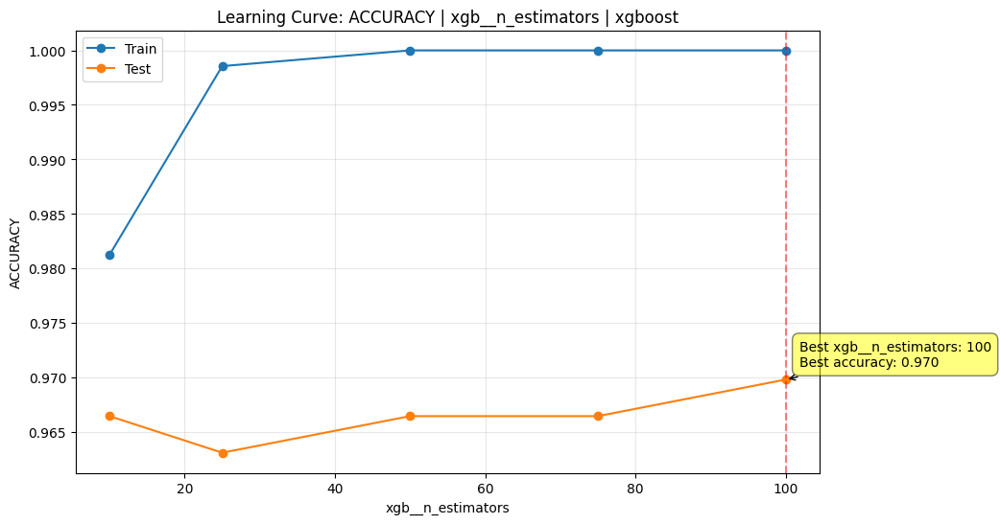


Evaluating xgb__max_depth for xgboost...
xgb__max_depth: 1; train: 0.975; test: 0.973; diff: 0.002
xgb__max_depth: 3; train: 1.000; test: 0.970; diff: 0.030
xgb__max_depth: 5; train: 1.000; test: 0.963; diff: 0.037
xgb__max_depth: 7; train: 1.000; test: 0.970; diff: 0.030
xgb__max_depth: 9; train: 1.000; test: 0.966; diff: 0.034
xgb__max_depth: 11; train: 1.000; test: 0.966; diff: 0.034
xgb__max_depth: 13; train: 1.000; test: 0.966; diff: 0.034
xgb__max_depth: 15; train: 1.000; test: 0.966; diff: 0.034
xgb__max_depth: 17; train: 1.000; test: 0.966; diff: 0.034
xgb__max_depth: 20; train: 1.000; test: 0.966; diff: 0.034


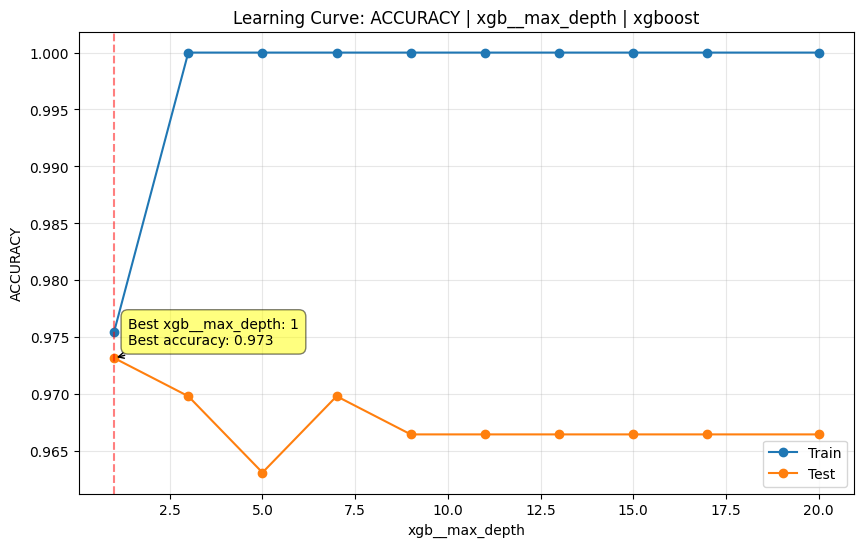


Evaluating xgb__nthread for xgboost...
xgb__nthread: 2; train: 1.000; test: 0.970; diff: 0.030
xgb__nthread: 4; train: 1.000; test: 0.970; diff: 0.030
xgb__nthread: 6; train: 1.000; test: 0.970; diff: 0.030
xgb__nthread: 8; train: 1.000; test: 0.970; diff: 0.030


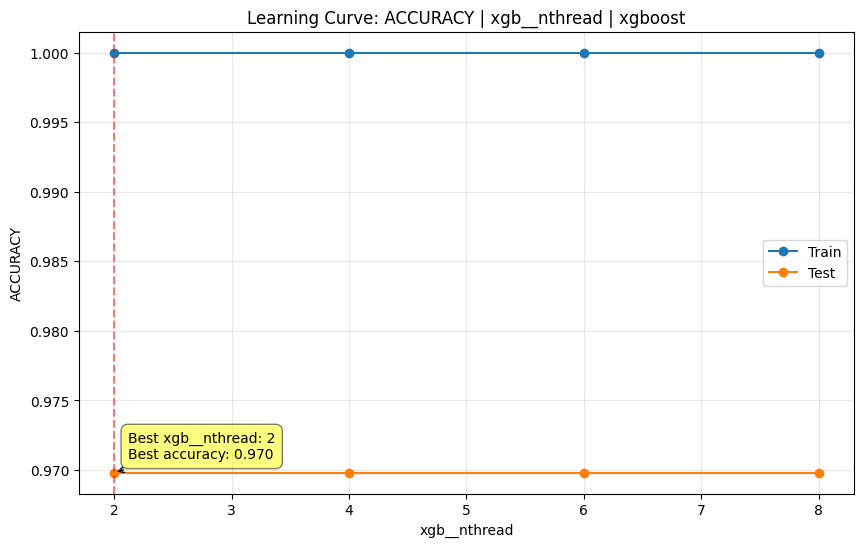


Evaluating xgb__tree_method for xgboost...
xgb__tree_method: approx; train: 1.000; test: 0.966; diff: 0.034
xgb__tree_method: hist; train: 1.000; test: 0.970; diff: 0.030


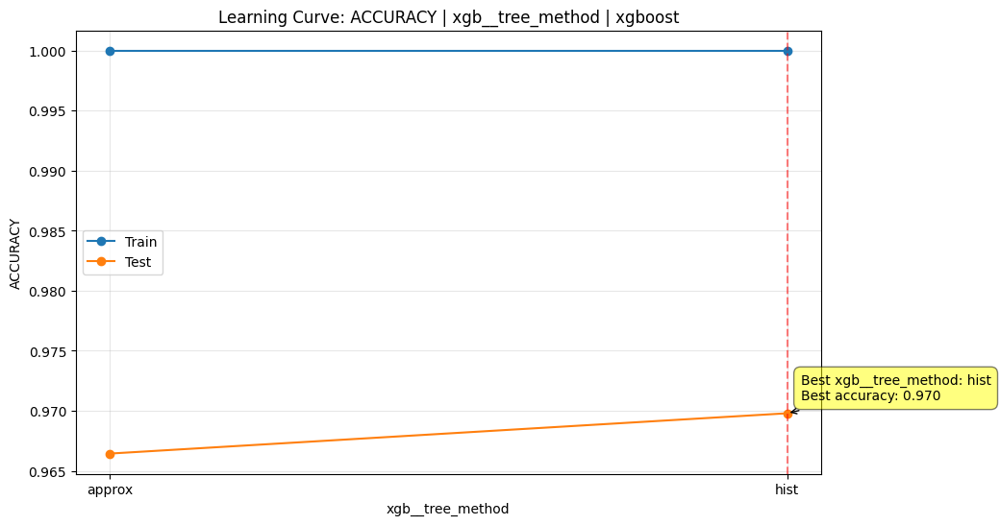

Fitting 15 folds for each of 8000 candidates, totalling 120000 fits

Grid Search Results for xgboost:
--------------------------------------------------
Total Fit Time: 1564.463s
Best accuracy: 0.958

Best Parameters:
xgb__eta: 0.4789473684210527
xgb__max_depth: 1
xgb__n_estimators: 100
xgb__nthread: 2
xgb__tree_method: approx



In [313]:
xgb1_model, xgb1_time = tune_single_model(
    model_name='xgboost',
    X_train=X1_train,
    y_train=y1_train,
    X_test=X1_test,
    y_test=y1_test,
    scoring='accuracy',
    plot_learning_curves=True
)

### Train Tuned Models

In [314]:
# Initiatialize object for each model
lr1_tuned = LogisticRegression(random_state=42, C=0.3945454545454546, max_iter=1000, penalty='l2', solver='newton-cg')
knn1_tuned = KNeighborsClassifier(algorithm = 'auto', n_neighbors = 28, p = 1, weights = 'uniform', leaf_size=10)
dt1_tuned = DecisionTreeClassifier(random_state=42, criterion = 'gini', max_depth = 7, max_features = 'sqrt', min_samples_leaf = 1, min_samples_split = 12, splitter = 'best')
rf1_tuned = RandomForestClassifier(random_state=42, criterion = 'gini', max_depth=9, max_features = 'sqrt', min_samples_leaf = 2, min_samples_split=2, n_estimators = 100)
gb1_tuned = GradientBoostingClassifier(random_state=42, criterion = 'friedman_mse', loss = 'exponential', max_depth = 4, max_features = 'sqrt', min_samples_leaf = 3, min_samples_split = 7, n_estimators = 50)
xgb1_tuned = XGBClassifier(random_state=42, eta=0.4789473684210527, max_depth = 1, n_estimators=100, nthread=2, tree_method='approx')

models = [lr1_tuned, knn1_tuned, dt1_tuned, rf1_tuned, gb1_tuned, xgb1_tuned]

# Train models
for model in models :
    model.fit(X1_train, y1_train)

### Evaluate Tuned Models

#### Logistic Regression

Performance Metrics for LogisticRegression:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  94.91 ± 2.42
  Train: 94.95 ± 1.89

PRECISION:
  Test:  96.92 ± 2.33
  Train: 97.03 ± 1.65

RECALL:
  Test:  92.81 ± 3.49
  Train: 92.75 ± 2.39

F1:
  Test:  94.79 ± 2.51
  Train: 94.83 ± 1.96

ROC_AUC:
  Test:  98.18 ± 1.36
  Train: 98.43 ± 0.96

Single Run Metrics:

ACCURACY:
  Test:  95.97
  Train: 94.66

PRECISION:
  Test:  97.83
  Train: 97.55

RECALL:
  Test:  93.75
  Train: 91.64

F1:
  Test:  95.74
  Train: 94.50

ROC_AUC:
  Test:  98.85
  Train: 98.43


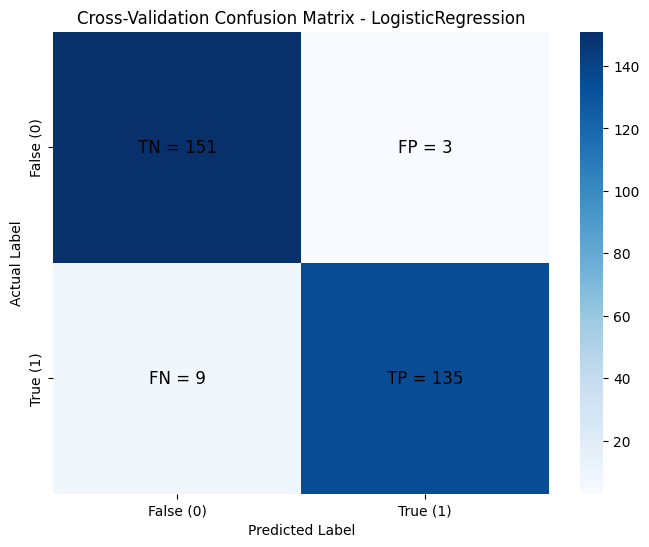

In [315]:
metrics_tuned_lr1 = eval_classification(model=lr1_tuned,
                                       X_train=X1_train,
                                       y_train=y1_train,
                                       X_test=X1_test,
                                       y_test=y1_test)

#### K-Nearest Neighbours

Performance Metrics for KNeighborsClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  72.29 ± 2.70
  Train: 72.94 ± 0.80

PRECISION:
  Test:  76.90 ± 3.43
  Train: 77.53 ± 1.19

RECALL:
  Test:  63.97 ± 5.13
  Train: 64.77 ± 2.26

F1:
  Test:  69.72 ± 3.54
  Train: 70.55 ± 1.25

ROC_AUC:
  Test:  76.55 ± 2.81
  Train: 79.56 ± 0.75

Single Run Metrics:

ACCURACY:
  Test:  67.45
  Train: 72.73

PRECISION:
  Test:  72.82
  Train: 77.05

RECALL:
  Test:  52.08
  Train: 64.84

F1:
  Test:  60.73
  Train: 70.42

ROC_AUC:
  Test:  71.65
  Train: 79.54


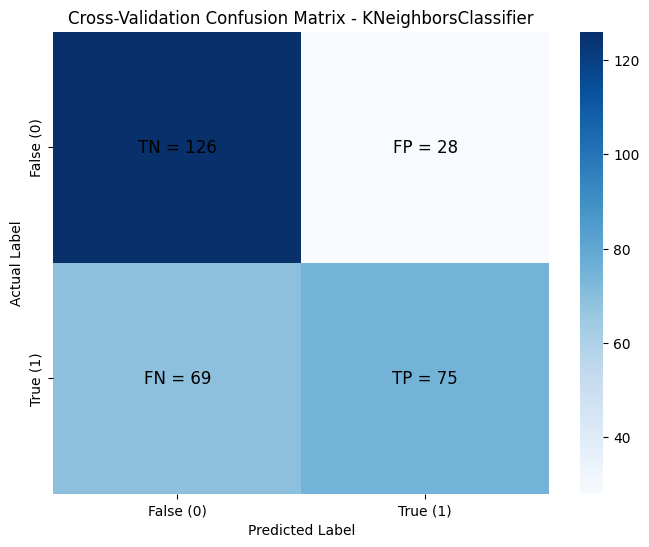

In [316]:
metrics_tuned_knn1 = eval_classification(model=knn1_tuned,
                                        X_train=X1_train,
                                        y_train=y1_train,
                                        X_test=X1_test,
                                        y_test=y1_test)

#### Decision Tree

Performance Metrics for DecisionTreeClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  94.18 ± 1.82
  Train: 97.07 ± 0.68

PRECISION:
  Test:  95.36 ± 2.86
  Train: 98.57 ± 1.00

RECALL:
  Test:  92.99 ± 2.62
  Train: 95.53 ± 1.04

F1:
  Test:  94.12 ± 1.84
  Train: 97.02 ± 0.69

ROC_AUC:
  Test:  95.43 ± 1.55
  Train: 99.23 ± 0.28

Single Run Metrics:

ACCURACY:
  Test:  96.31
  Train: 97.40

PRECISION:
  Test:  97.16
  Train: 99.10

RECALL:
  Test:  95.14
  Train: 95.68

F1:
  Test:  96.14
  Train: 97.36

ROC_AUC:
  Test:  97.29
  Train: 99.30


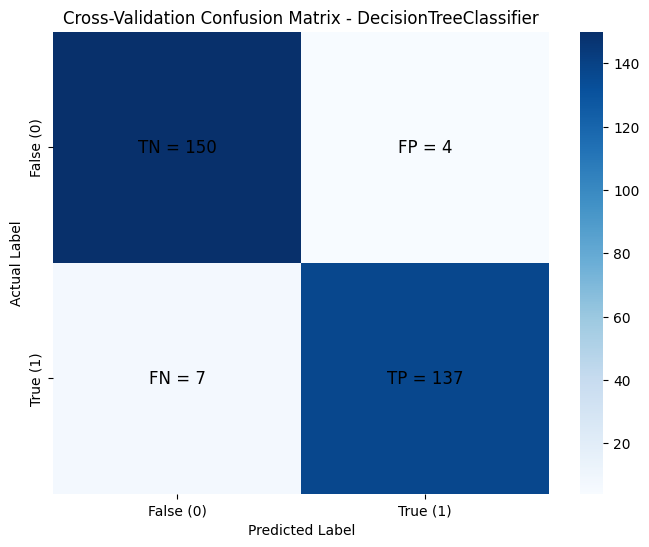

In [317]:
metrics_tuned_dt1 = eval_classification(model=dt1_tuned,
                                       X_train=X1_train,
                                       y_train=y1_train,
                                       X_test=X1_test,
                                       y_test=y1_test)

#### Random Forest

Performance Metrics for RandomForestClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  96.06 ± 1.62
  Train: 98.89 ± 0.23

PRECISION:
  Test:  96.74 ± 2.27
  Train: 99.73 ± 0.16

RECALL:
  Test:  95.39 ± 2.41
  Train: 98.05 ± 0.47

F1:
  Test:  96.03 ± 1.62
  Train: 98.89 ± 0.23

ROC_AUC:
  Test:  99.08 ± 0.45
  Train: 99.93 ± 0.03

Single Run Metrics:

ACCURACY:
  Test:  97.99
  Train: 98.99

PRECISION:
  Test:  97.92
  Train: 99.42

RECALL:
  Test:  97.92
  Train: 98.56

F1:
  Test:  97.92
  Train: 98.99

ROC_AUC:
  Test:  99.42
  Train: 99.92


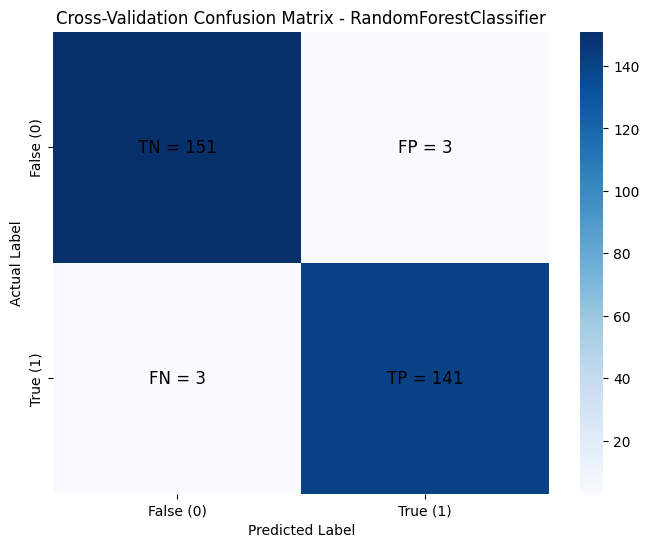

In [318]:
metrics_tuned_rf1 = eval_classification(model=rf1_tuned,
                                       X_train=X1_train,
                                       y_train=y1_train,
                                       X_test=X1_test,
                                       y_test=y1_test)

#### GradientBoost

Performance Metrics for GradientBoostingClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  95.82 ± 1.35
  Train: 98.93 ± 0.20

PRECISION:
  Test:  96.64 ± 2.30
  Train: 99.88 ± 0.17

RECALL:
  Test:  95.01 ± 1.95
  Train: 97.98 ± 0.43

F1:
  Test:  95.79 ± 1.34
  Train: 98.92 ± 0.21

ROC_AUC:
  Test:  98.99 ± 0.36
  Train: 99.98 ± 0.01

Single Run Metrics:

ACCURACY:
  Test:  96.98
  Train: 98.70

PRECISION:
  Test:  97.20
  Train: 99.71

RECALL:
  Test:  96.53
  Train: 97.69

F1:
  Test:  96.86
  Train: 98.69

ROC_AUC:
  Test:  99.01
  Train: 99.97


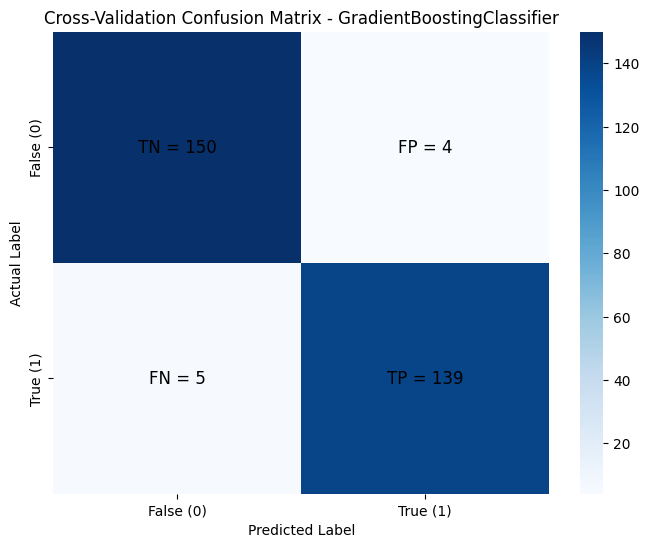

In [319]:
metrics_tuned_gb1 = eval_classification(model=gb1_tuned,
                                       X_train=X1_train,
                                       y_train=y1_train,
                                       X_test=X1_test,
                                       y_test=y1_test)

#### XGBoost

Performance Metrics for XGBClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  95.77 ± 1.48
  Train: 98.21 ± 0.23

PRECISION:
  Test:  96.11 ± 2.32
  Train: 99.44 ± 0.32

RECALL:
  Test:  95.49 ± 2.22
  Train: 96.97 ± 0.54

F1:
  Test:  95.77 ± 1.47
  Train: 98.19 ± 0.24

ROC_AUC:
  Test:  98.84 ± 0.64
  Train: 99.84 ± 0.04

Single Run Metrics:

ACCURACY:
  Test:  97.32
  Train: 97.84

PRECISION:
  Test:  97.22
  Train: 99.40

RECALL:
  Test:  97.22
  Train: 96.25

F1:
  Test:  97.22
  Train: 97.80

ROC_AUC:
  Test:  99.06
  Train: 99.77


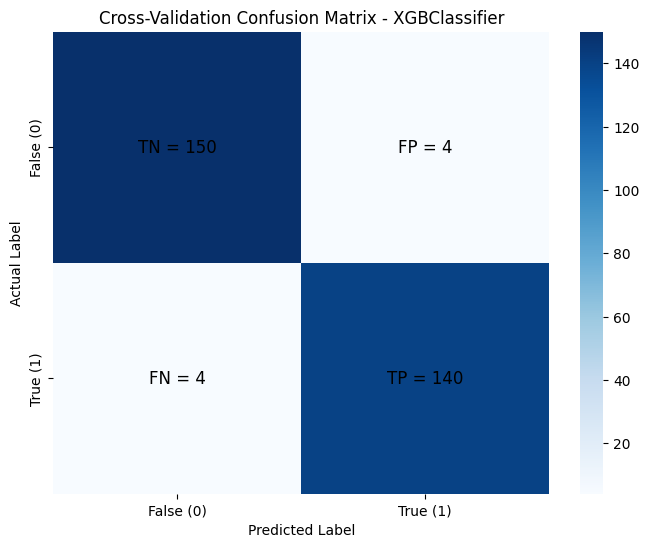

In [320]:
metrics_tuned_xgb1 = eval_classification(model=xgb1_tuned,
                                        X_train=X1_train,
                                        y_train=y1_train,
                                        X_test=X1_test,
                                        y_test=y1_test)

## **Case 2 : With Feature Scaling**

### Train Vanilla Models

In [321]:
# Initiatialize object for each model
lr2 = LogisticRegression(random_state=42)
knn2 = KNeighborsClassifier()
dt2 = DecisionTreeClassifier(random_state=42)
rf2 = RandomForestClassifier(random_state=42)
gb2 = GradientBoostingClassifier(random_state=42)
xgb2 = XGBClassifier(random_state=42)

models = [lr2, knn2, dt2, rf2, gb2, xgb2]

# Train models
for model in models :
    model.fit(X2_train, y2_train)

### Evaluate Vanilla Models

#### Logistic Regression

Performance Metrics for LogisticRegression:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  96.25 ± 1.15
  Train: 96.79 ± 0.29

PRECISION:
  Test:  97.40 ± 1.75
  Train: 97.75 ± 0.26

RECALL:
  Test:  95.10 ± 2.45
  Train: 95.80 ± 0.47

F1:
  Test:  96.20 ± 1.17
  Train: 96.76 ± 0.30

ROC_AUC:
  Test:  98.99 ± 0.59
  Train: 99.19 ± 0.14

Single Run Metrics:

ACCURACY:
  Test:  96.98
  Train: 96.83

PRECISION:
  Test:  96.55
  Train: 97.65

RECALL:
  Test:  97.22
  Train: 95.97

F1:
  Test:  96.89
  Train: 96.80

ROC_AUC:
  Test:  99.31
  Train: 99.17


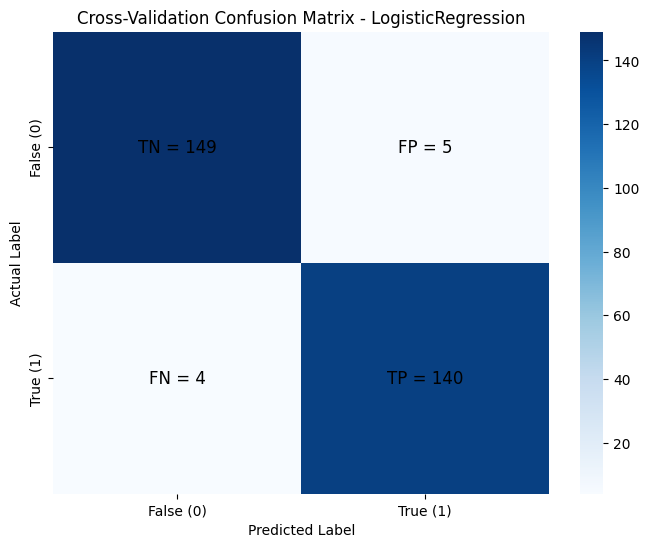

In [322]:
metrics_vanilla_lr2 = eval_classification(model=lr2,
                                         X_train=X2_train,
                                         y_train=y2_train,
                                         X_test=X2_test,
                                         y_test=y2_test)

#### K-Nearest Neighbours

Performance Metrics for KNeighborsClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  95.34 ± 1.01
  Train: 96.56 ± 0.27

PRECISION:
  Test:  97.52 ± 1.39
  Train: 98.92 ± 0.41

RECALL:
  Test:  93.09 ± 2.29
  Train: 94.16 ± 0.53

F1:
  Test:  95.22 ± 1.08
  Train: 96.48 ± 0.28

ROC_AUC:
  Test:  97.99 ± 0.79
  Train: 99.54 ± 0.07

Single Run Metrics:

ACCURACY:
  Test:  97.99
  Train: 96.83

PRECISION:
  Test:  99.29
  Train: 99.09

RECALL:
  Test:  96.53
  Train: 94.52

F1:
  Test:  97.89
  Train: 96.76

ROC_AUC:
  Test:  99.15
  Train: 99.57


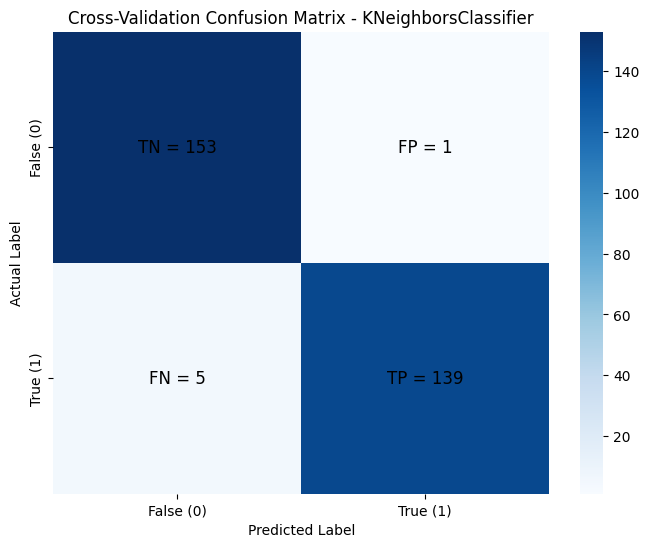

In [323]:
metrics_vanilla_knn2 = eval_classification(model=knn2,
                                          X_train=X2_train,
                                          y_train=y2_train,
                                          X_test=X2_test,
                                          y_test=y2_test)

#### Decision Tree

Performance Metrics for DecisionTreeClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  93.80 ± 1.04
  Train: 100.00 ± 0.00

PRECISION:
  Test:  94.14 ± 2.70
  Train: 100.00 ± 0.00

RECALL:
  Test:  93.56 ± 2.41
  Train: 100.00 ± 0.00

F1:
  Test:  93.79 ± 1.01
  Train: 100.00 ± 0.00

ROC_AUC:
  Test:  93.79 ± 1.04
  Train: 100.00 ± 0.00

Single Run Metrics:

ACCURACY:
  Test:  94.30
  Train: 100.00

PRECISION:
  Test:  92.62
  Train: 100.00

RECALL:
  Test:  95.83
  Train: 100.00

F1:
  Test:  94.20
  Train: 100.00

ROC_AUC:
  Test:  94.35
  Train: 100.00


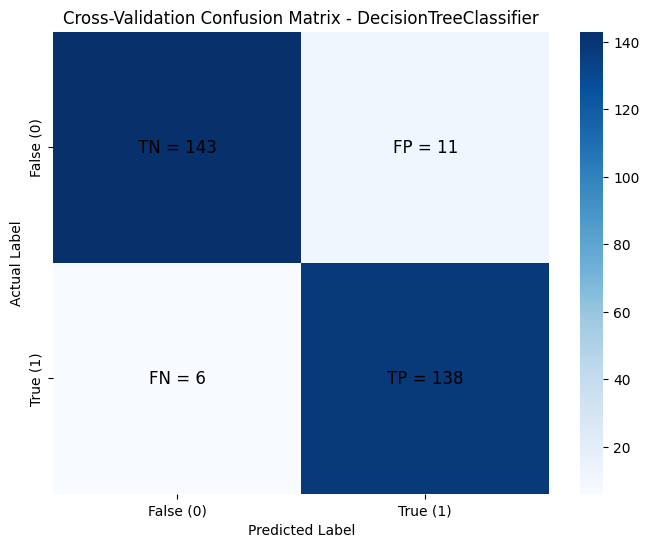

In [324]:
metrics_vanilla_dt2 = eval_classification(model=dt2,
                                         X_train=X2_train,
                                         y_train=y2_train,
                                         X_test=X2_test,
                                         y_test=y2_test)

#### Random Forest

Performance Metrics for RandomForestClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  95.62 ± 1.35
  Train: 100.00 ± 0.00

PRECISION:
  Test:  96.35 ± 1.94
  Train: 100.00 ± 0.00

RECALL:
  Test:  94.91 ± 2.50
  Train: 100.00 ± 0.00

F1:
  Test:  95.59 ± 1.37
  Train: 100.00 ± 0.00

ROC_AUC:
  Test:  98.94 ± 0.47
  Train: 100.00 ± 0.00

Single Run Metrics:

ACCURACY:
  Test:  97.99
  Train: 100.00

PRECISION:
  Test:  98.59
  Train: 100.00

RECALL:
  Test:  97.22
  Train: 100.00

F1:
  Test:  97.90
  Train: 100.00

ROC_AUC:
  Test:  99.15
  Train: 100.00


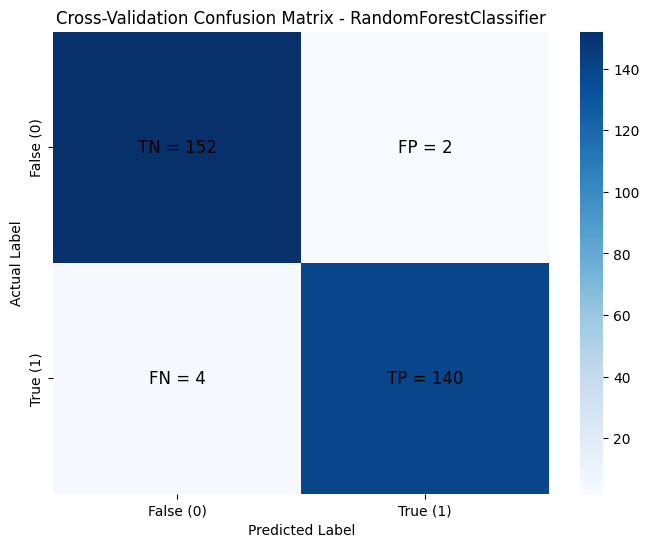

In [325]:
metrics_vanilla_rf2 = eval_classification(model=rf2,
                                         X_train=X2_train,
                                         y_train=y2_train,
                                         X_test=X2_test,
                                         y_test=y2_test)

#### GradientBoost

Performance Metrics for GradientBoostingClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  95.00 ± 1.47
  Train: 99.95 ± 0.08

PRECISION:
  Test:  95.67 ± 2.06
  Train: 100.00 ± 0.00

RECALL:
  Test:  94.33 ± 2.60
  Train: 99.90 ± 0.16

F1:
  Test:  94.96 ± 1.50
  Train: 99.95 ± 0.08

ROC_AUC:
  Test:  98.73 ± 0.52
  Train: 100.00 ± 0.00

Single Run Metrics:

ACCURACY:
  Test:  97.32
  Train: 99.86

PRECISION:
  Test:  97.22
  Train: 100.00

RECALL:
  Test:  97.22
  Train: 99.71

F1:
  Test:  97.22
  Train: 99.86

ROC_AUC:
  Test:  98.98
  Train: 99.99


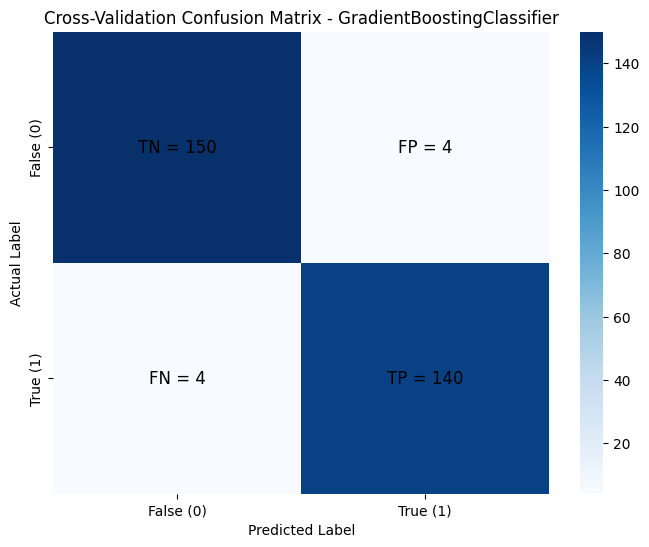

In [326]:
metrics_vanilla_gb2 = eval_classification(model=gb2,
                                         X_train=X2_train,
                                         y_train=y2_train,
                                         X_test=X2_test,
                                         y_test=y2_test)

#### XGBoost

Performance Metrics for XGBClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  94.09 ± 1.37
  Train: 100.00 ± 0.00

PRECISION:
  Test:  94.59 ± 2.47
  Train: 100.00 ± 0.00

RECALL:
  Test:  93.66 ± 3.28
  Train: 100.00 ± 0.00

F1:
  Test:  94.05 ± 1.41
  Train: 100.00 ± 0.00

ROC_AUC:
  Test:  98.75 ± 0.59
  Train: 100.00 ± 0.00

Single Run Metrics:

ACCURACY:
  Test:  96.98
  Train: 100.00

PRECISION:
  Test:  97.87
  Train: 100.00

RECALL:
  Test:  95.83
  Train: 100.00

F1:
  Test:  96.84
  Train: 100.00

ROC_AUC:
  Test:  99.27
  Train: 100.00


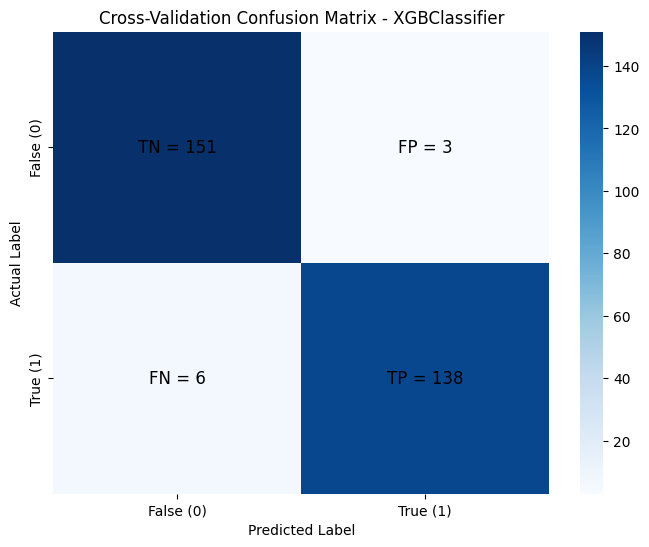

In [327]:
metrics_vanilla_xgb2 = eval_classification(model=xgb2,
                                         X_train=X2_train,
                                         y_train=y2_train,
                                         X_test=X2_test,
                                         y_test=y2_test)

Overfitting happens in some models, the same case with before normalization/standardization case. The solution will be the same which is hyperparameter tuning will be done.

### Hyperparameter Tuning

In [328]:
# # Define pipeline for each model
# # (Another approach where scaling is done utilizing pipelines) 
# def get_model_pipeline(model_name: str) -> Pipeline:
#     """
#     Create a pipeline for a specific model.
    
#     Parameters:
#     -----------
#     model_name : str
#         Name of the model to create pipeline for
        
#     Returns:
#     --------
#     Pipeline
#         Scikit-learn pipeline with the specified model
#     """
#     pipelines = {
#         'logisticregression': Pipeline([
#             ('scaling', StandardScaler()),
#             ('lr', LogisticRegression(random_state=42))
#         ]),
#         'knn': Pipeline([
#             ('scaling', StandardScaler()),
#             ('knn', KNeighborsClassifier())
#         ]),
#         'decisiontree': Pipeline([
#             ('scaling', StandardScaler()),
#             ('dt', DecisionTreeClassifier(random_state=42))
#         ]),
#         'randomforest': Pipeline([
#             ('scaling', StandardScaler()),
#             ('rf', RandomForestClassifier(random_state=42))
#         ]),
#         'gb': Pipeline([
#             ('scaling', StandardScaler()),
#             ('gb', GradientBoostingClassifier(random_state=42))
#         ]),
#         'xgboost': Pipeline([
#             ('scaling', StandardScaler()),
#             ('xgb', XGBClassifier(random_state=42))
#         ])
#     }
    
#     return pipelines.get(model_name.lower())

#### Tuning Logistic Regression


Evaluating lr__C for logisticregression...
lr__C: 0.001; train: 0.949; test: 0.960; diff: -0.010
lr__C: 0.011090909090909092; train: 0.957; test: 0.980; diff: -0.023
lr__C: 0.021181818181818184; train: 0.958; test: 0.980; diff: -0.022
lr__C: 0.03127272727272727; train: 0.964; test: 0.980; diff: -0.016
lr__C: 0.041363636363636366; train: 0.965; test: 0.980; diff: -0.014
lr__C: 0.05145454545454546; train: 0.967; test: 0.977; diff: -0.010
lr__C: 0.06154545454545455; train: 0.968; test: 0.977; diff: -0.008
lr__C: 0.07163636363636364; train: 0.970; test: 0.977; diff: -0.007
lr__C: 0.08172727272727273; train: 0.970; test: 0.977; diff: -0.007
lr__C: 0.09181818181818183; train: 0.970; test: 0.977; diff: -0.007
lr__C: 0.10190909090909092; train: 0.971; test: 0.977; diff: -0.005
lr__C: 0.112; train: 0.970; test: 0.977; diff: -0.007
lr__C: 0.1220909090909091; train: 0.970; test: 0.977; diff: -0.007
lr__C: 0.13218181818181818; train: 0.968; test: 0.977; diff: -0.008
lr__C: 0.14227272727272727; tr

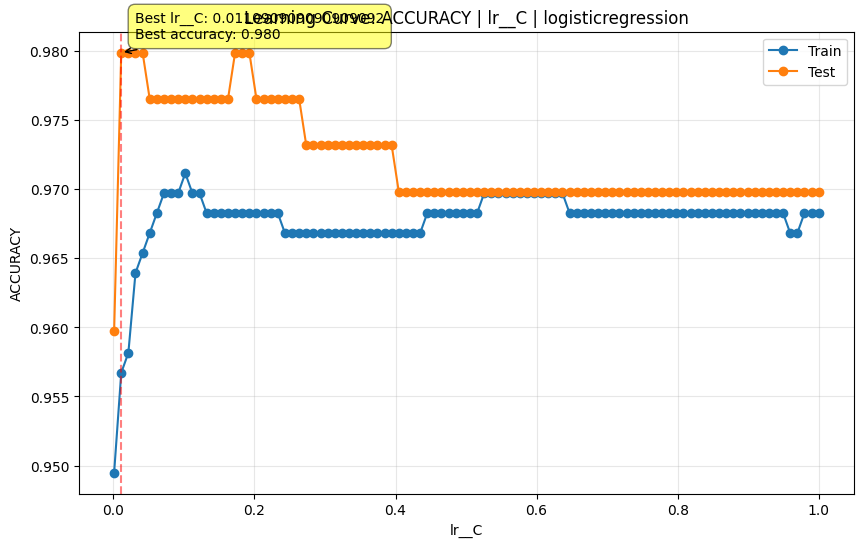


Evaluating lr__solver for logisticregression...
lr__solver: newton-cg; train: 0.968; test: 0.970; diff: -0.002
lr__solver: lbfgs; train: 0.968; test: 0.970; diff: -0.002
lr__solver: newton-cholesky; train: 0.968; test: 0.970; diff: -0.002
lr__solver: liblinear; train: 0.968; test: 0.973; diff: -0.005


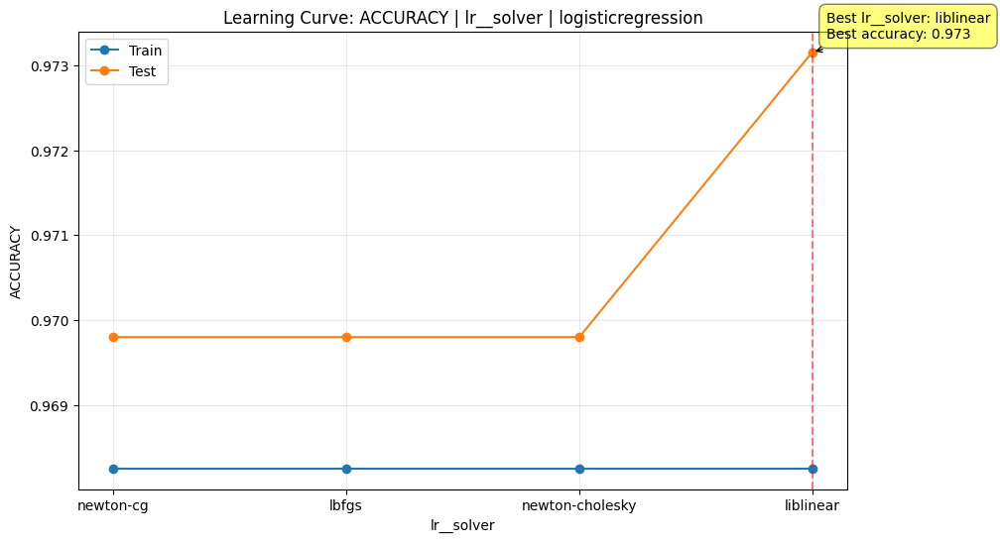


Evaluating lr__max_iter for logisticregression...
lr__max_iter: 1000; train: 0.968; test: 0.970; diff: -0.002
lr__max_iter: 5000; train: 0.968; test: 0.970; diff: -0.002
lr__max_iter: 10000; train: 0.968; test: 0.970; diff: -0.002


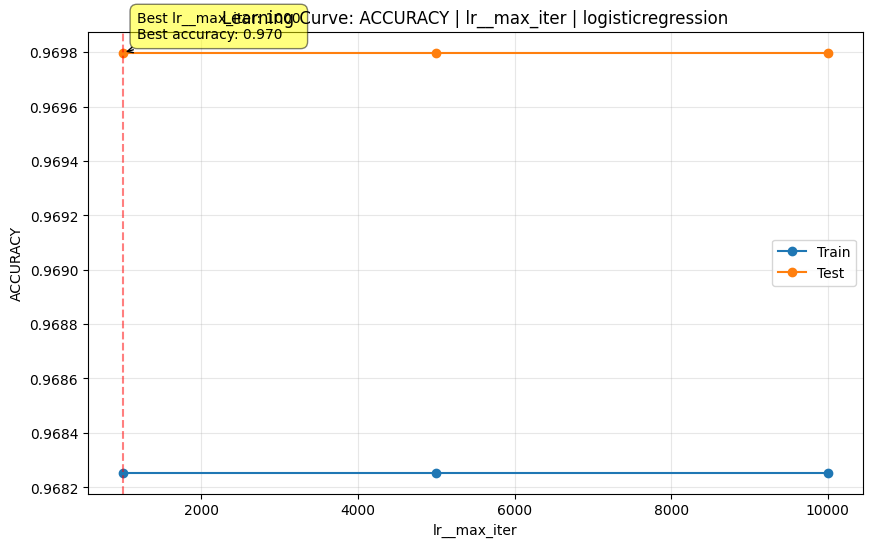

Fitting 15 folds for each of 1200 candidates, totalling 18000 fits

Grid Search Results for logisticregression:
--------------------------------------------------
Total Fit Time: 22.764s
Best accuracy: 0.965

Best Parameters:
lr__C: 0.29363636363636364
lr__max_iter: 1000
lr__penalty: l2
lr__solver: newton-cg



In [329]:
lr2_model, lr2_time = tune_single_model(
    model_name='logisticregression',
    X_train=X2_train,
    y_train=y2_train,
    X_test=X2_test,
    y_test=y2_test,
    scoring='accuracy',
    plot_learning_curves=True
)

#### Tuning K-Nearest Neighbours


Evaluating knn__n_neighbors for knn...
knn__n_neighbors: 1; train: 1.000; test: 0.956; diff: 0.044
knn__n_neighbors: 2; train: 0.964; test: 0.956; diff: 0.008
knn__n_neighbors: 3; train: 0.971; test: 0.980; diff: -0.009
knn__n_neighbors: 4; train: 0.965; test: 0.973; diff: -0.008
knn__n_neighbors: 5; train: 0.968; test: 0.980; diff: -0.012
knn__n_neighbors: 6; train: 0.961; test: 0.977; diff: -0.015
knn__n_neighbors: 7; train: 0.961; test: 0.983; diff: -0.022
knn__n_neighbors: 8; train: 0.960; test: 0.987; diff: -0.027
knn__n_neighbors: 9; train: 0.964; test: 0.983; diff: -0.019
knn__n_neighbors: 10; train: 0.960; test: 0.987; diff: -0.027
knn__n_neighbors: 11; train: 0.962; test: 0.987; diff: -0.024
knn__n_neighbors: 12; train: 0.957; test: 0.987; diff: -0.030
knn__n_neighbors: 13; train: 0.961; test: 0.987; diff: -0.026
knn__n_neighbors: 14; train: 0.955; test: 0.987; diff: -0.031
knn__n_neighbors: 15; train: 0.958; test: 0.987; diff: -0.028
knn__n_neighbors: 16; train: 0.957; test:

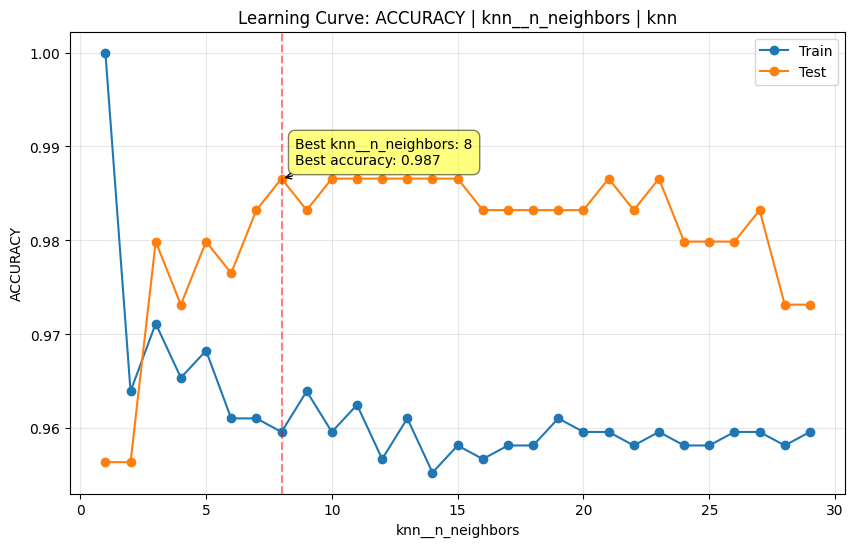


Evaluating knn__weights for knn...
knn__weights: uniform; train: 0.968; test: 0.980; diff: -0.012
knn__weights: distance; train: 1.000; test: 0.980; diff: 0.020


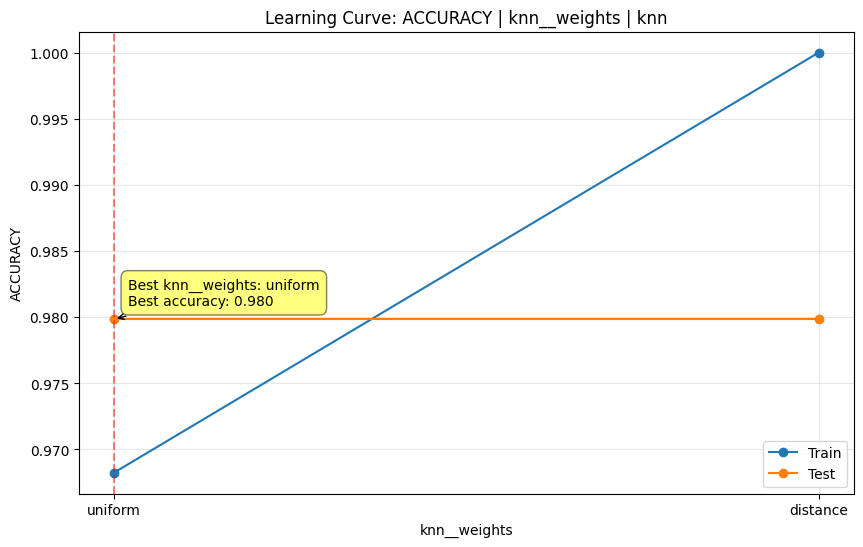


Evaluating knn__p for knn...
knn__p: 1; train: 0.968; test: 0.977; diff: -0.008
knn__p: 2; train: 0.968; test: 0.980; diff: -0.012


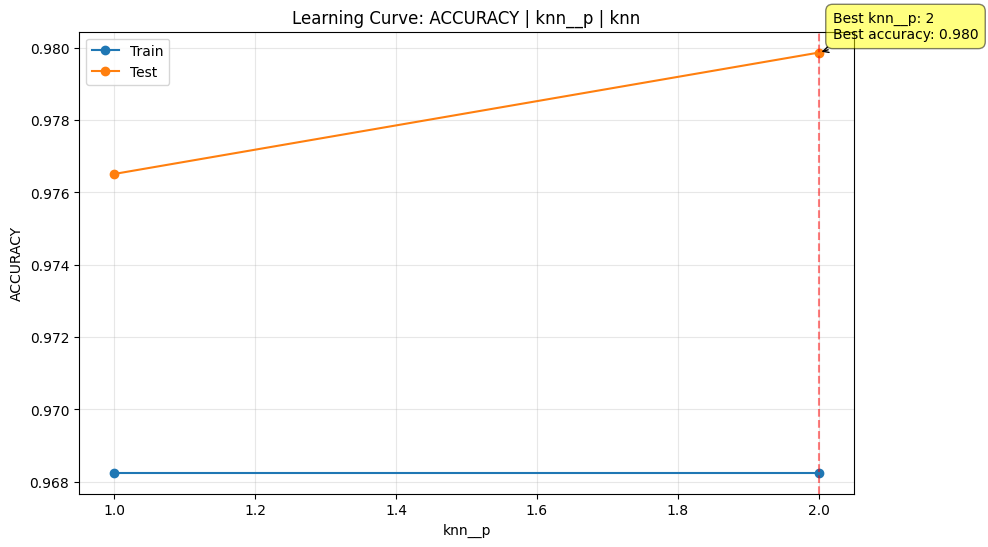


Evaluating knn__algorithm for knn...
knn__algorithm: auto; train: 0.968; test: 0.980; diff: -0.012
knn__algorithm: ball_tree; train: 0.968; test: 0.980; diff: -0.012
knn__algorithm: kd_tree; train: 0.968; test: 0.980; diff: -0.012
knn__algorithm: brute; train: 0.968; test: 0.980; diff: -0.012


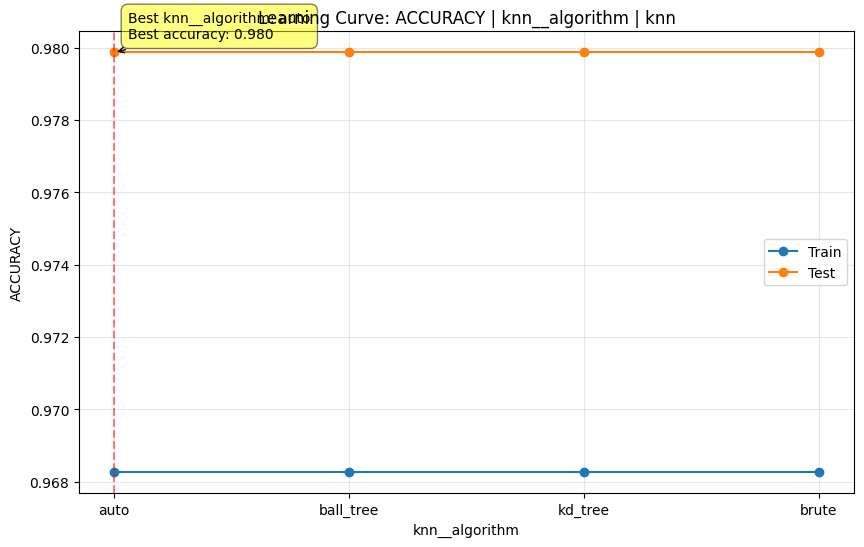


Evaluating knn__leaf_size for knn...
knn__leaf_size: 10; train: 0.968; test: 0.980; diff: -0.012
knn__leaf_size: 20; train: 0.968; test: 0.980; diff: -0.012
knn__leaf_size: 35; train: 0.968; test: 0.980; diff: -0.012


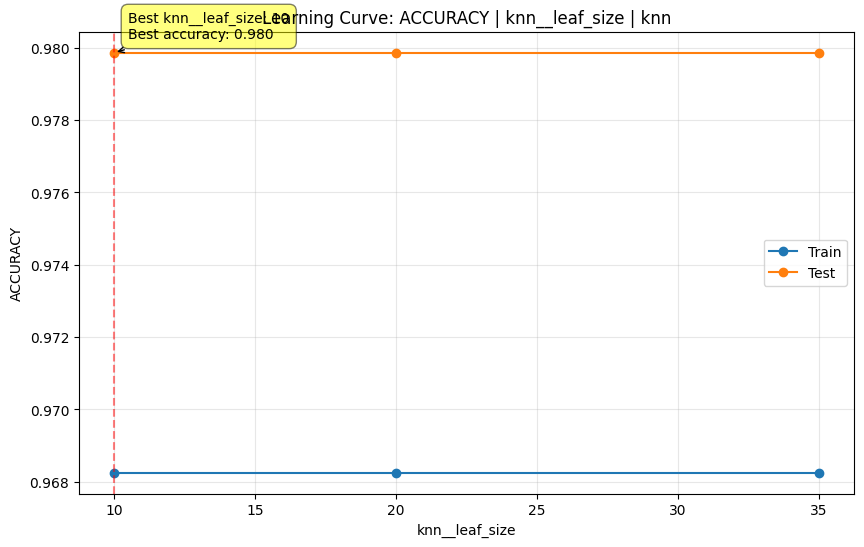

Fitting 15 folds for each of 1392 candidates, totalling 20880 fits

Grid Search Results for knn:
--------------------------------------------------
Total Fit Time: 88.833s
Best accuracy: 0.958

Best Parameters:
knn__algorithm: auto
knn__leaf_size: 10
knn__n_neighbors: 17
knn__p: 2
knn__weights: distance



In [330]:
knn2_model, knn2_time = tune_single_model(
    model_name='knn',
    X_train=X2_train,
    y_train=y2_train,
    X_test=X2_test,
    y_test=y2_test,
    scoring='accuracy',
    plot_learning_curves=True
)

#### Tuning Decision Tree


Evaluating dt__criterion for decisiontree...
dt__criterion: entropy; train: 1.000; test: 0.973; diff: 0.027
dt__criterion: gini; train: 1.000; test: 0.943; diff: 0.057


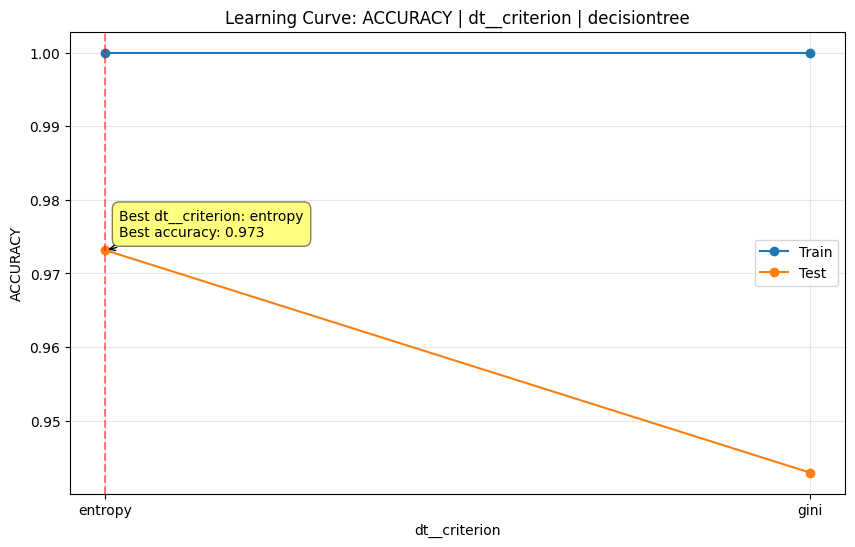


Evaluating dt__max_depth for decisiontree...
dt__max_depth: 1; train: 0.902; test: 0.903; diff: -0.001
dt__max_depth: 2; train: 0.935; test: 0.940; diff: -0.005
dt__max_depth: 3; train: 0.965; test: 0.960; diff: 0.006
dt__max_depth: 4; train: 0.974; test: 0.963; diff: 0.011
dt__max_depth: 5; train: 0.981; test: 0.963; diff: 0.018
dt__max_depth: 6; train: 0.984; test: 0.960; diff: 0.024
dt__max_depth: 7; train: 0.988; test: 0.960; diff: 0.029
dt__max_depth: 8; train: 0.990; test: 0.960; diff: 0.030
dt__max_depth: 9; train: 0.993; test: 0.953; diff: 0.040
dt__max_depth: 10; train: 0.994; test: 0.950; diff: 0.045
dt__max_depth: 11; train: 0.997; test: 0.950; diff: 0.047
dt__max_depth: 12; train: 0.999; test: 0.946; diff: 0.052
dt__max_depth: 13; train: 1.000; test: 0.943; diff: 0.057
dt__max_depth: 14; train: 1.000; test: 0.943; diff: 0.057
dt__max_depth: 15; train: 1.000; test: 0.943; diff: 0.057
dt__max_depth: 16; train: 1.000; test: 0.943; diff: 0.057
dt__max_depth: 17; train: 1.000; 

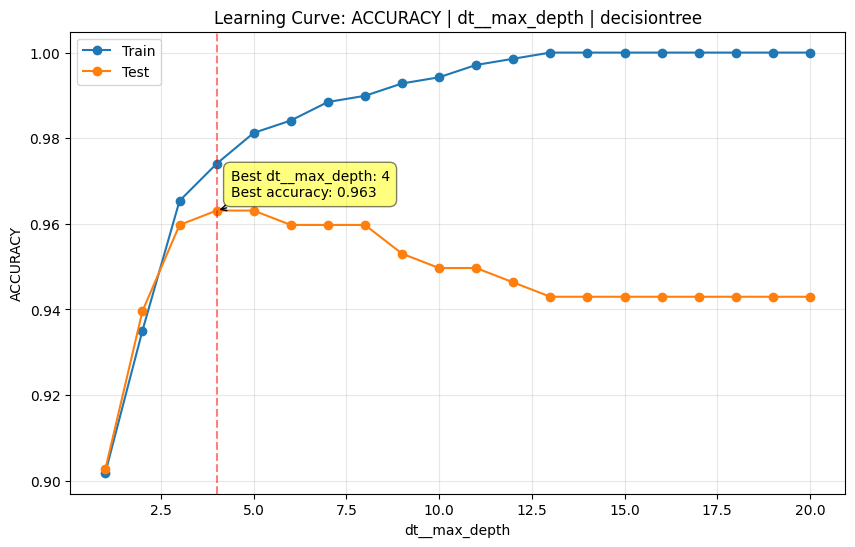


Evaluating dt__min_samples_split for decisiontree...
dt__min_samples_split: 2; train: 1.000; test: 0.943; diff: 0.057
dt__min_samples_split: 7; train: 0.988; test: 0.953; diff: 0.035
dt__min_samples_split: 12; train: 0.988; test: 0.953; diff: 0.035
dt__min_samples_split: 18; train: 0.978; test: 0.960; diff: 0.019
dt__min_samples_split: 23; train: 0.975; test: 0.953; diff: 0.022
dt__min_samples_split: 28; train: 0.970; test: 0.953; diff: 0.017
dt__min_samples_split: 34; train: 0.970; test: 0.953; diff: 0.017
dt__min_samples_split: 39; train: 0.970; test: 0.953; diff: 0.017
dt__min_samples_split: 44; train: 0.970; test: 0.953; diff: 0.017
dt__min_samples_split: 50; train: 0.947; test: 0.946; diff: 0.000


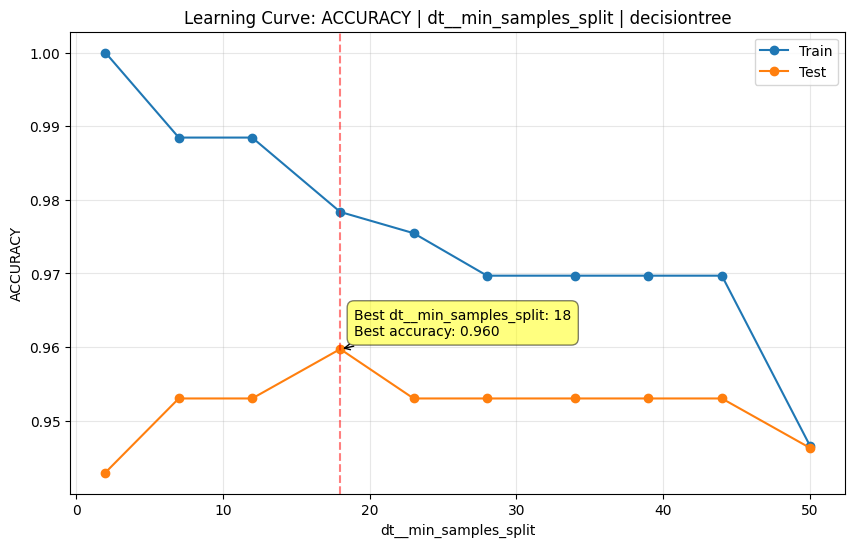


Evaluating dt__min_samples_leaf for decisiontree...
dt__min_samples_leaf: 1; train: 1.000; test: 0.943; diff: 0.057
dt__min_samples_leaf: 6; train: 0.958; test: 0.956; diff: 0.002
dt__min_samples_leaf: 11; train: 0.957; test: 0.953; diff: 0.004
dt__min_samples_leaf: 17; train: 0.957; test: 0.953; diff: 0.004
dt__min_samples_leaf: 22; train: 0.955; test: 0.956; diff: -0.001
dt__min_samples_leaf: 28; train: 0.934; test: 0.943; diff: -0.009
dt__min_samples_leaf: 33; train: 0.932; test: 0.943; diff: -0.011
dt__min_samples_leaf: 39; train: 0.928; test: 0.936; diff: -0.008
dt__min_samples_leaf: 44; train: 0.924; test: 0.933; diff: -0.009
dt__min_samples_leaf: 50; train: 0.916; test: 0.930; diff: -0.013


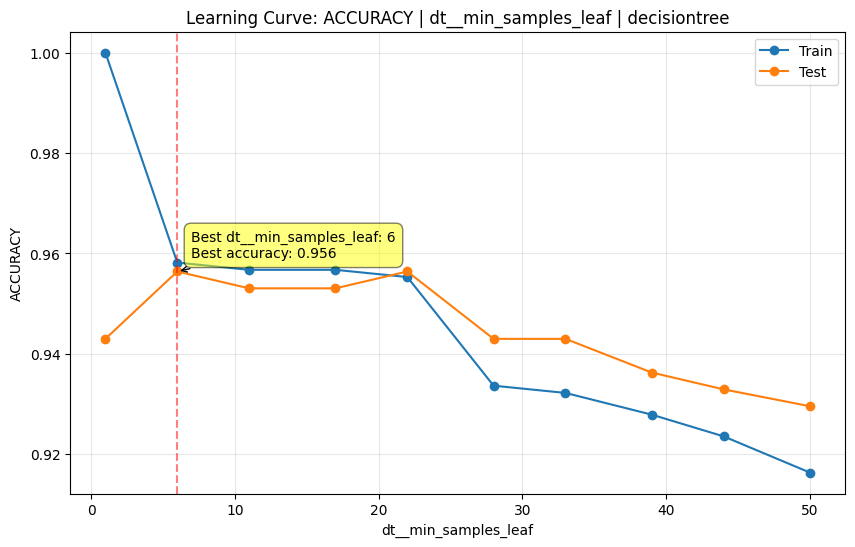

Fitting 15 folds for each of 4000 candidates, totalling 60000 fits

Grid Search Results for decisiontree:
--------------------------------------------------
Total Fit Time: 60.376s
Best accuracy: 0.942

Best Parameters:
dt__criterion: gini
dt__max_depth: 7
dt__max_features: sqrt
dt__min_samples_leaf: 1
dt__min_samples_split: 12
dt__splitter: best



In [331]:
dt2_model, dt2_time = tune_single_model(
    model_name='decisiontree',
    X_train=X2_train,
    y_train=y2_train,
    X_test=X2_test,
    y_test=y2_test,
    scoring='accuracy',
    plot_learning_curves=True
)

#### Tuning Random Forest


Evaluating rf__n_estimators for randomforest...
rf__n_estimators: 10; train: 0.999; test: 0.973; diff: 0.025
rf__n_estimators: 20; train: 0.999; test: 0.973; diff: 0.025
rf__n_estimators: 30; train: 1.000; test: 0.980; diff: 0.020
rf__n_estimators: 40; train: 1.000; test: 0.987; diff: 0.013
rf__n_estimators: 50; train: 1.000; test: 0.987; diff: 0.013
rf__n_estimators: 75; train: 1.000; test: 0.987; diff: 0.013
rf__n_estimators: 100; train: 1.000; test: 0.980; diff: 0.020


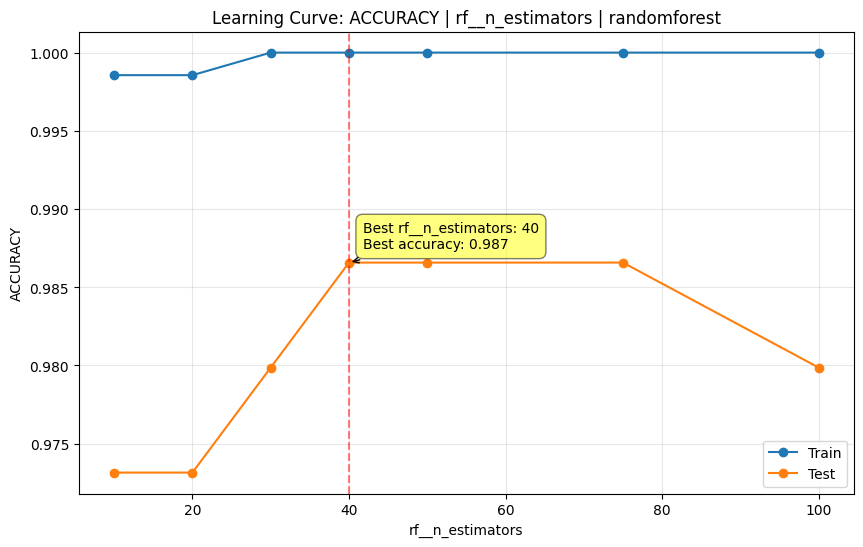


Evaluating rf__criterion for randomforest...
rf__criterion: entropy; train: 1.000; test: 0.980; diff: 0.020
rf__criterion: gini; train: 1.000; test: 0.980; diff: 0.020


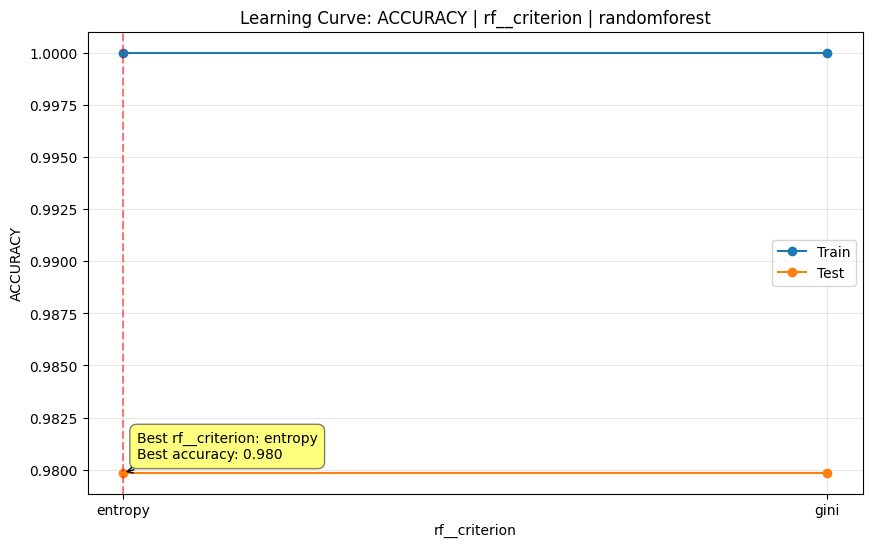


Evaluating rf__max_depth for randomforest...
rf__max_depth: 1; train: 0.947; test: 0.946; diff: 0.000
rf__max_depth: 3; train: 0.965; test: 0.956; diff: 0.009
rf__max_depth: 5; train: 0.978; test: 0.977; diff: 0.002
rf__max_depth: 7; train: 0.993; test: 0.980; diff: 0.013
rf__max_depth: 9; train: 0.994; test: 0.977; diff: 0.018
rf__max_depth: 11; train: 0.996; test: 0.980; diff: 0.016
rf__max_depth: 13; train: 1.000; test: 0.980; diff: 0.020
rf__max_depth: 15; train: 1.000; test: 0.980; diff: 0.020
rf__max_depth: 17; train: 1.000; test: 0.980; diff: 0.020
rf__max_depth: 20; train: 1.000; test: 0.980; diff: 0.020


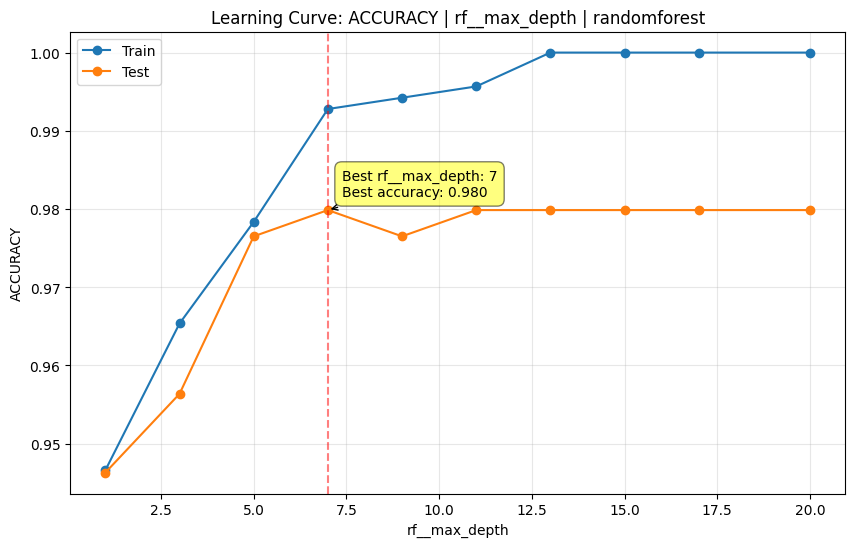


Evaluating rf__min_samples_split for randomforest...
rf__min_samples_split: 2; train: 1.000; test: 0.980; diff: 0.020
rf__min_samples_split: 5; train: 0.991; test: 0.983; diff: 0.008
rf__min_samples_split: 7; train: 0.988; test: 0.977; diff: 0.012
rf__min_samples_split: 10; train: 0.987; test: 0.980; diff: 0.007


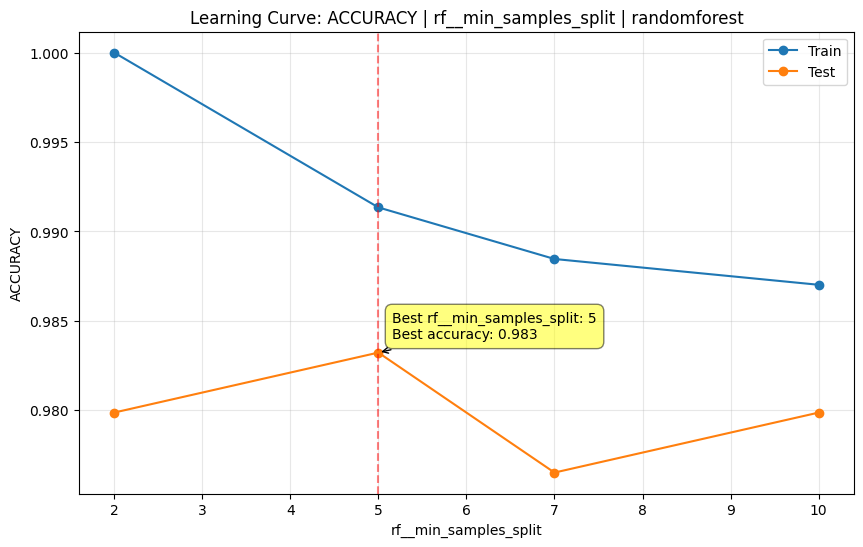


Evaluating rf__max_features for randomforest...
rf__max_features: sqrt; train: 1.000; test: 0.980; diff: 0.020
rf__max_features: log2; train: 1.000; test: 0.980; diff: 0.020


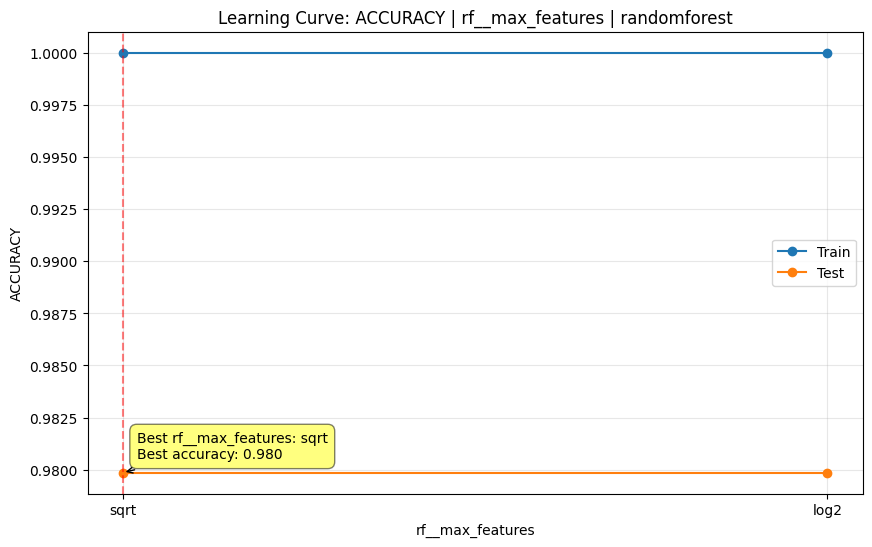


Evaluating rf__min_samples_leaf for randomforest...
rf__min_samples_leaf: 1; train: 1.000; test: 0.980; diff: 0.020
rf__min_samples_leaf: 2; train: 0.990; test: 0.980; diff: 0.010
rf__min_samples_leaf: 4; train: 0.977; test: 0.980; diff: -0.003
rf__min_samples_leaf: 6; train: 0.973; test: 0.977; diff: -0.004


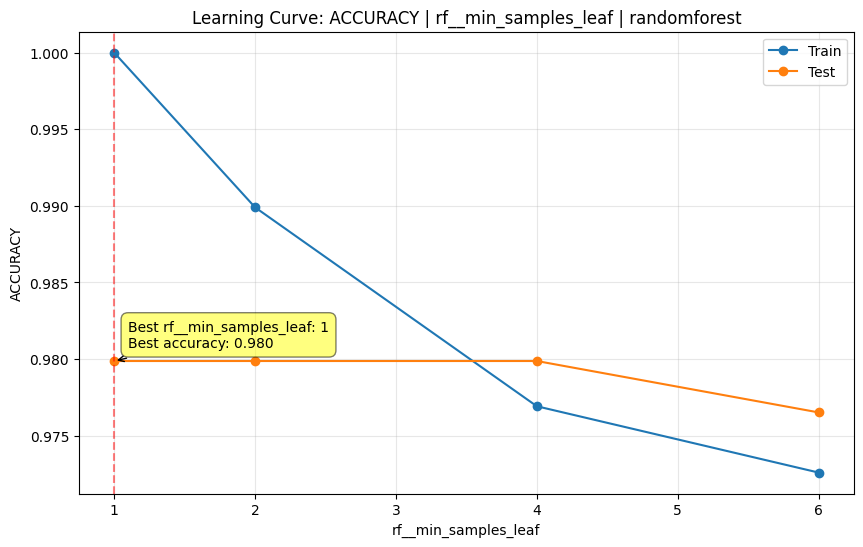

Fitting 15 folds for each of 4480 candidates, totalling 67200 fits

Grid Search Results for randomforest:
--------------------------------------------------
Total Fit Time: 719.646s
Best accuracy: 0.960

Best Parameters:
rf__criterion: gini
rf__max_depth: 9
rf__max_features: sqrt
rf__min_samples_leaf: 2
rf__min_samples_split: 2
rf__n_estimators: 100



In [332]:
rf2_model, rf2_time = tune_single_model(
    model_name='randomforest',
    X_train=X2_train,
    y_train=y2_train,
    X_test=X2_test,
    y_test=y2_test,
    scoring='accuracy',
    plot_learning_curves=True
)

#### Tuning GradientBoost


Evaluating gb__n_estimators for gb...
gb__n_estimators: 25; train: 0.980; test: 0.963; diff: 0.017
gb__n_estimators: 50; train: 0.993; test: 0.973; diff: 0.020
gb__n_estimators: 100; train: 0.999; test: 0.973; diff: 0.025
gb__n_estimators: 200; train: 1.000; test: 0.973; diff: 0.027


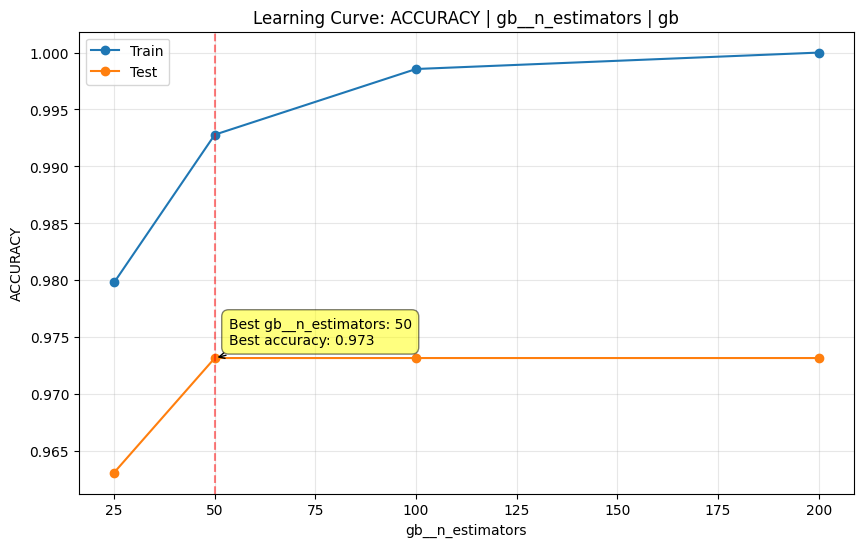


Evaluating gb__criterion for gb...
gb__criterion: friedman_mse; train: 0.999; test: 0.973; diff: 0.025
gb__criterion: squared_error; train: 0.999; test: 0.973; diff: 0.025


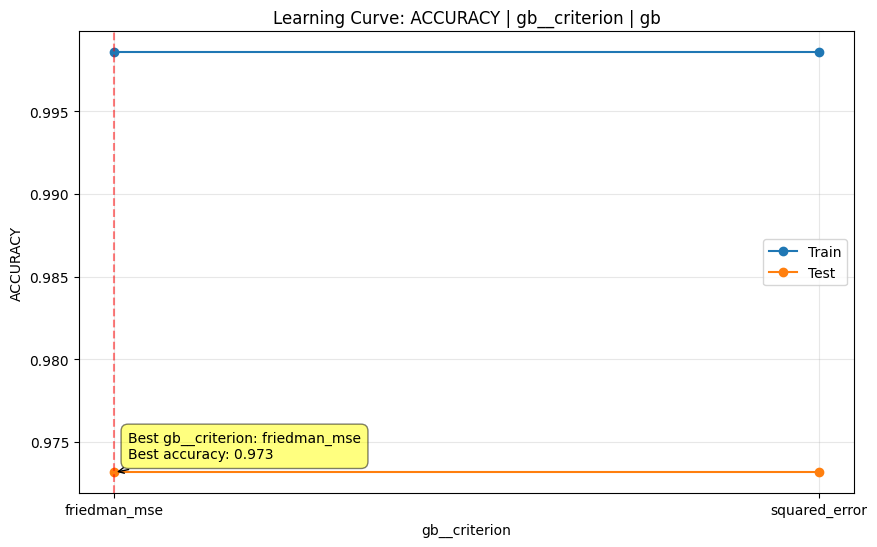


Evaluating gb__max_depth for gb...
gb__max_depth: 1; train: 0.968; test: 0.973; diff: -0.005
gb__max_depth: 3; train: 0.999; test: 0.973; diff: 0.025
gb__max_depth: 4; train: 1.000; test: 0.966; diff: 0.034
gb__max_depth: 5; train: 1.000; test: 0.970; diff: 0.030
gb__max_depth: 7; train: 1.000; test: 0.950; diff: 0.050


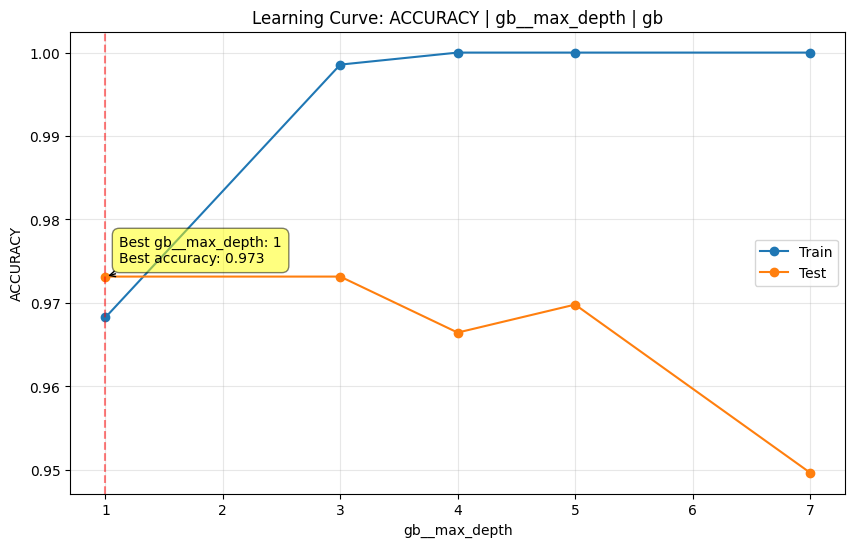


Evaluating gb__min_samples_split for gb...
gb__min_samples_split: 2; train: 0.999; test: 0.973; diff: 0.025
gb__min_samples_split: 3; train: 0.999; test: 0.970; diff: 0.029
gb__min_samples_split: 5; train: 0.999; test: 0.977; diff: 0.022
gb__min_samples_split: 7; train: 0.999; test: 0.973; diff: 0.025


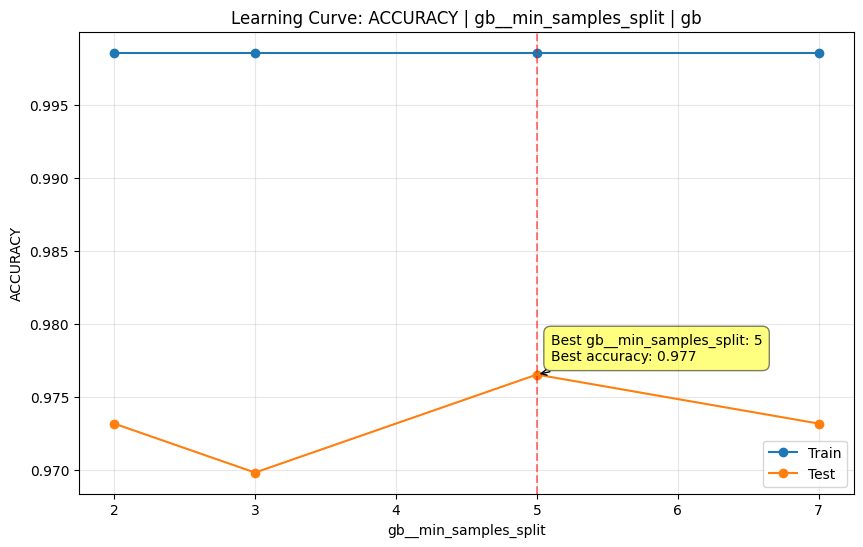


Evaluating gb__min_samples_leaf for gb...
gb__min_samples_leaf: 2; train: 0.999; test: 0.970; diff: 0.029
gb__min_samples_leaf: 3; train: 0.999; test: 0.970; diff: 0.029
gb__min_samples_leaf: 5; train: 0.999; test: 0.970; diff: 0.029
gb__min_samples_leaf: 7; train: 0.999; test: 0.970; diff: 0.029


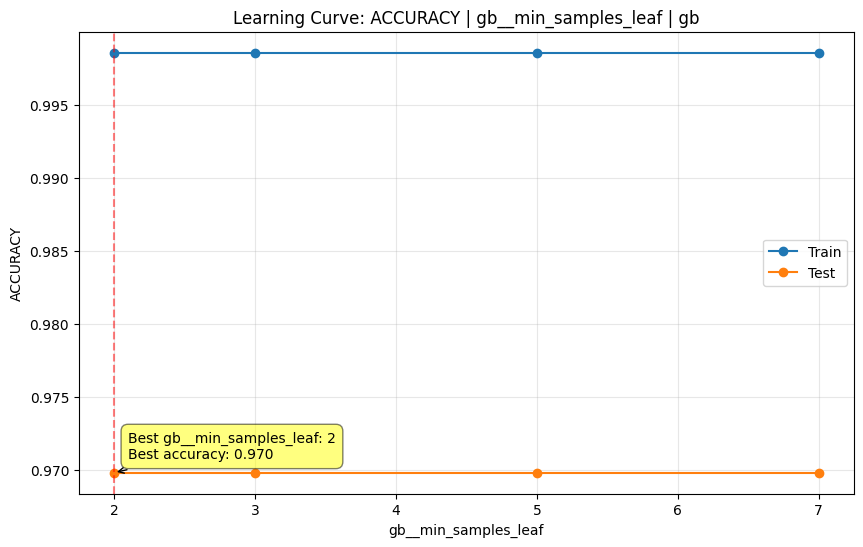

Fitting 15 folds for each of 640 candidates, totalling 9600 fits

Grid Search Results for gb:
--------------------------------------------------
Total Fit Time: 171.096s
Best accuracy: 0.958

Best Parameters:
gb__criterion: friedman_mse
gb__loss: exponential
gb__max_depth: 4
gb__max_features: sqrt
gb__min_samples_leaf: 3
gb__min_samples_split: 7
gb__n_estimators: 50



In [333]:
gb2_model, gb2_time = tune_single_model(
    model_name='gb',
    X_train=X2_train,
    y_train=y2_train,
    X_test=X2_test,
    y_test=y2_test,
    scoring='accuracy',
    plot_learning_curves=True
)

#### Tuning XGBoost


Evaluating xgb__eta for xgboost...
xgb__eta: 0.1; train: 0.999; test: 0.966; diff: 0.032
xgb__eta: 0.1473684210526316; train: 1.000; test: 0.960; diff: 0.040
xgb__eta: 0.19473684210526315; train: 1.000; test: 0.963; diff: 0.037
xgb__eta: 0.24210526315789474; train: 1.000; test: 0.966; diff: 0.034
xgb__eta: 0.2894736842105263; train: 1.000; test: 0.966; diff: 0.034
xgb__eta: 0.33684210526315794; train: 1.000; test: 0.970; diff: 0.030
xgb__eta: 0.38421052631578945; train: 1.000; test: 0.966; diff: 0.034
xgb__eta: 0.43157894736842106; train: 1.000; test: 0.966; diff: 0.034
xgb__eta: 0.4789473684210527; train: 1.000; test: 0.963; diff: 0.037
xgb__eta: 0.5263157894736842; train: 1.000; test: 0.966; diff: 0.034
xgb__eta: 0.5736842105263158; train: 1.000; test: 0.970; diff: 0.030
xgb__eta: 0.6210526315789474; train: 1.000; test: 0.966; diff: 0.034
xgb__eta: 0.6684210526315789; train: 1.000; test: 0.963; diff: 0.037
xgb__eta: 0.7157894736842105; train: 1.000; test: 0.966; diff: 0.034
xgb__eta

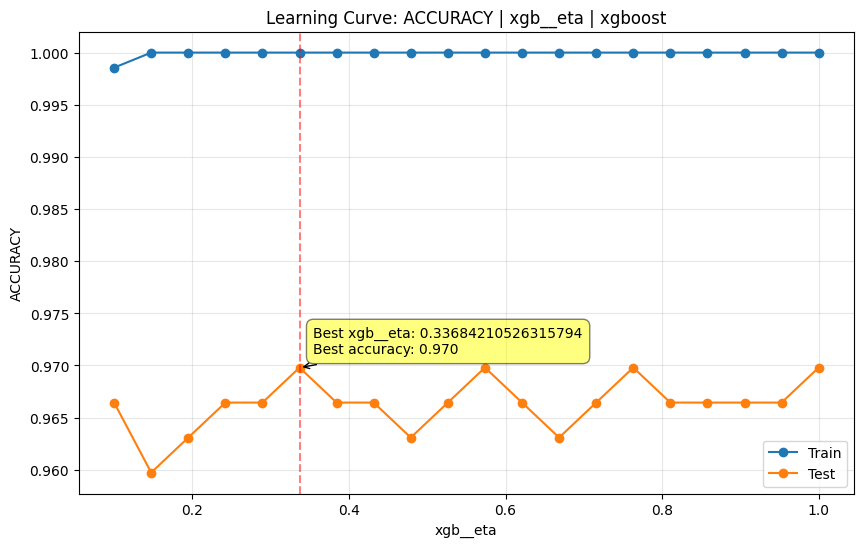


Evaluating xgb__n_estimators for xgboost...
xgb__n_estimators: 10; train: 0.981; test: 0.966; diff: 0.015
xgb__n_estimators: 25; train: 0.999; test: 0.963; diff: 0.035
xgb__n_estimators: 50; train: 1.000; test: 0.966; diff: 0.034
xgb__n_estimators: 75; train: 1.000; test: 0.966; diff: 0.034
xgb__n_estimators: 100; train: 1.000; test: 0.970; diff: 0.030


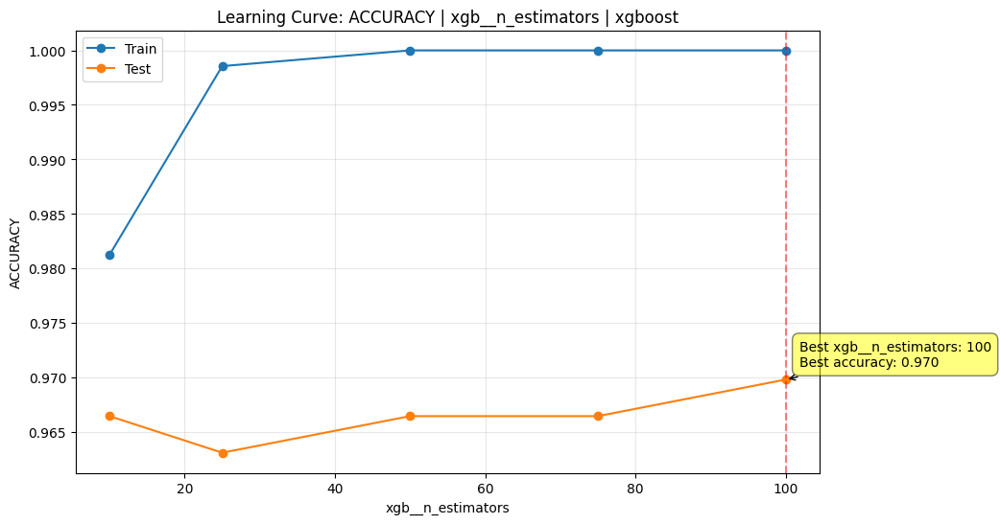


Evaluating xgb__max_depth for xgboost...
xgb__max_depth: 1; train: 0.975; test: 0.973; diff: 0.002
xgb__max_depth: 3; train: 1.000; test: 0.970; diff: 0.030
xgb__max_depth: 5; train: 1.000; test: 0.963; diff: 0.037
xgb__max_depth: 7; train: 1.000; test: 0.970; diff: 0.030
xgb__max_depth: 9; train: 1.000; test: 0.966; diff: 0.034
xgb__max_depth: 11; train: 1.000; test: 0.966; diff: 0.034
xgb__max_depth: 13; train: 1.000; test: 0.966; diff: 0.034
xgb__max_depth: 15; train: 1.000; test: 0.966; diff: 0.034
xgb__max_depth: 17; train: 1.000; test: 0.966; diff: 0.034
xgb__max_depth: 20; train: 1.000; test: 0.966; diff: 0.034


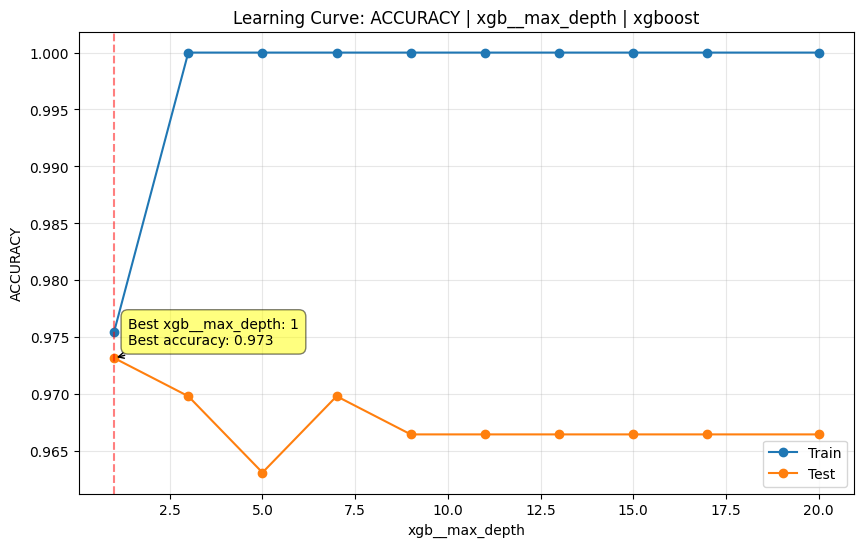


Evaluating xgb__nthread for xgboost...
xgb__nthread: 2; train: 1.000; test: 0.970; diff: 0.030
xgb__nthread: 4; train: 1.000; test: 0.970; diff: 0.030
xgb__nthread: 6; train: 1.000; test: 0.970; diff: 0.030
xgb__nthread: 8; train: 1.000; test: 0.970; diff: 0.030


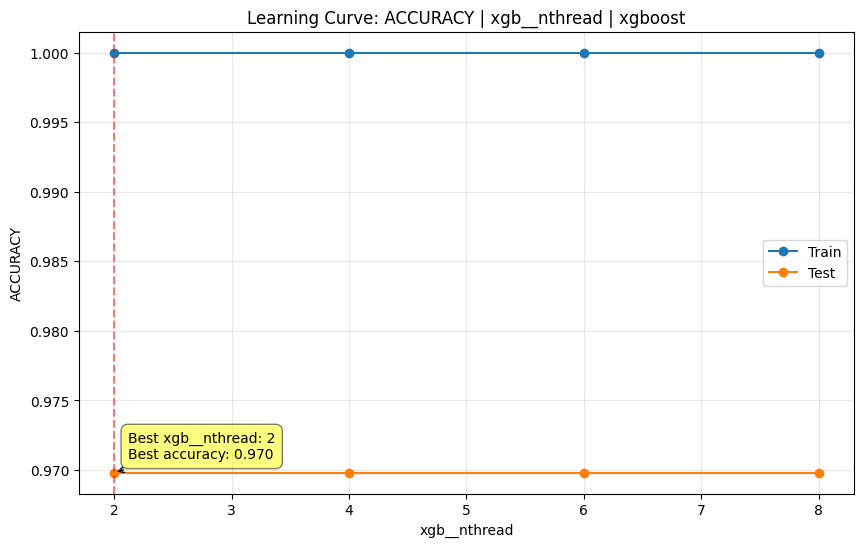


Evaluating xgb__tree_method for xgboost...
xgb__tree_method: approx; train: 1.000; test: 0.966; diff: 0.034
xgb__tree_method: hist; train: 1.000; test: 0.970; diff: 0.030


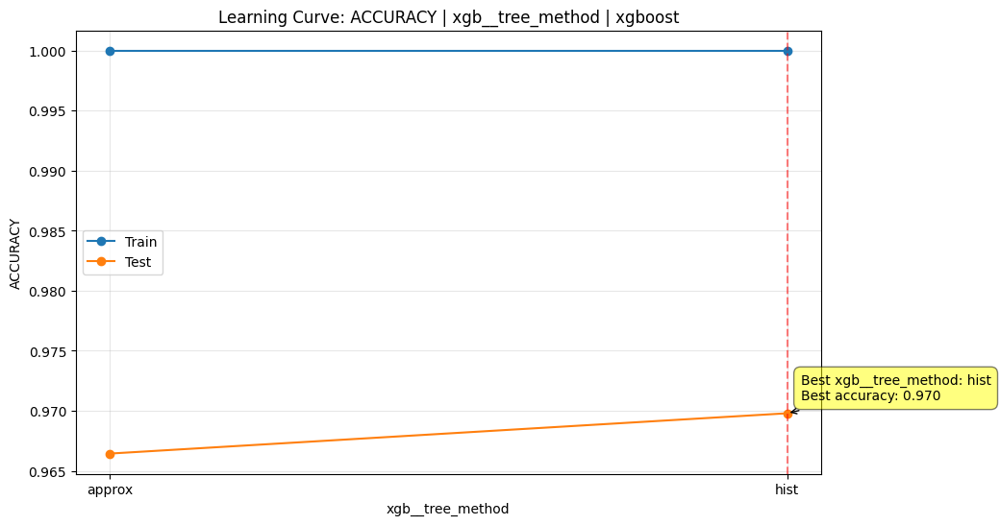

Fitting 15 folds for each of 8000 candidates, totalling 120000 fits

Grid Search Results for xgboost:
--------------------------------------------------
Total Fit Time: 1384.199s
Best accuracy: 0.958

Best Parameters:
xgb__eta: 0.4789473684210527
xgb__max_depth: 1
xgb__n_estimators: 100
xgb__nthread: 2
xgb__tree_method: approx



In [334]:
xgb2_model, xgb2_time = tune_single_model(
    model_name='xgboost',
    X_train=X2_train,
    y_train=y2_train,
    X_test=X2_test,
    y_test=y2_test,
    scoring='accuracy',
    plot_learning_curves=True
)

### Train Tuned Models

In [93]:
# Initiatialize object for each model
lr2_tuned = LogisticRegression(random_state=42, C=0.13218181818181818, max_iter=1000, penalty='l2', solver='newton-cg')
knn2_tuned = KNeighborsClassifier(algorithm = 'auto', leaf_size=10, n_neighbors = 6, p = 2, weights = 'distance')
dt2_tuned = DecisionTreeClassifier(random_state=42, criterion = 'gini', max_depth = 7, max_features = 'sqrt', min_samples_leaf = 1, min_samples_split = 12, splitter = 'best')
rf2_tuned = RandomForestClassifier(random_state=42, criterion = 'gini', max_depth = 9, max_features = 'sqrt', min_samples_leaf = 2, min_samples_split = 2, n_estimators = 100)
gb2_tuned = GradientBoostingClassifier(random_state=42, criterion = 'friedman_mse', loss = 'exponential', max_depth = 4, max_features = 'sqrt', min_samples_leaf = 3, min_samples_split = 7, n_estimators = 50)
xgb2_tuned = XGBClassifier(random_state=42, eta=0.4789473684210527, max_depth = 1, n_estimators=100, nthread=2, tree_method='approx')

models = [lr2_tuned, knn2_tuned, dt2_tuned, rf2_tuned, gb2_tuned, xgb2_tuned]

# Train models
for model in models :
    model.fit(X2_train, y2_train)

### Evaluate Tuned Models

#### Logistic Regression

Performance Metrics for LogisticRegression:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  96.35 ± 1.24
  Train: 96.91 ± 0.31

PRECISION:
  Test:  98.33 ± 1.18
  Train: 98.83 ± 0.23

RECALL:
  Test:  94.34 ± 2.69
  Train: 94.96 ± 0.60

F1:
  Test:  96.26 ± 1.31
  Train: 96.85 ± 0.33

ROC_AUC:
  Test:  99.01 ± 0.59
  Train: 99.11 ± 0.14

Single Run Metrics:

ACCURACY:
  Test:  97.65
  Train: 96.83

PRECISION:
  Test:  98.58
  Train: 98.51

RECALL:
  Test:  96.53
  Train: 95.10

F1:
  Test:  97.54
  Train: 96.77

ROC_AUC:
  Test:  99.30
  Train: 99.09


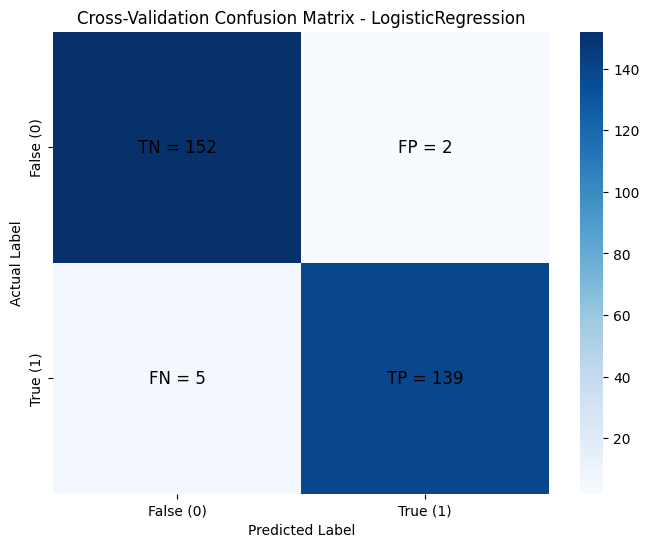

In [336]:
metrics_tuned_lr2 = eval_classification(model=lr2_tuned,
                                       X_train=X2_train,
                                       y_train=y2_train,
                                       X_test=X2_test,
                                       y_test=y2_test)

#### K-Nearest Neighbours

Performance Metrics for KNeighborsClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  95.38 ± 1.44
  Train: 100.00 ± 0.00

PRECISION:
  Test:  97.89 ± 1.22
  Train: 100.00 ± 0.00

RECALL:
  Test:  92.80 ± 2.78
  Train: 100.00 ± 0.00

F1:
  Test:  95.25 ± 1.53
  Train: 100.00 ± 0.00

ROC_AUC:
  Test:  98.06 ± 0.78
  Train: 100.00 ± 0.00

Single Run Metrics:

ACCURACY:
  Test:  98.32
  Train: 100.00

PRECISION:
  Test:  99.29
  Train: 100.00

RECALL:
  Test:  97.22
  Train: 100.00

F1:
  Test:  98.25
  Train: 100.00

ROC_AUC:
  Test:  99.17
  Train: 100.00


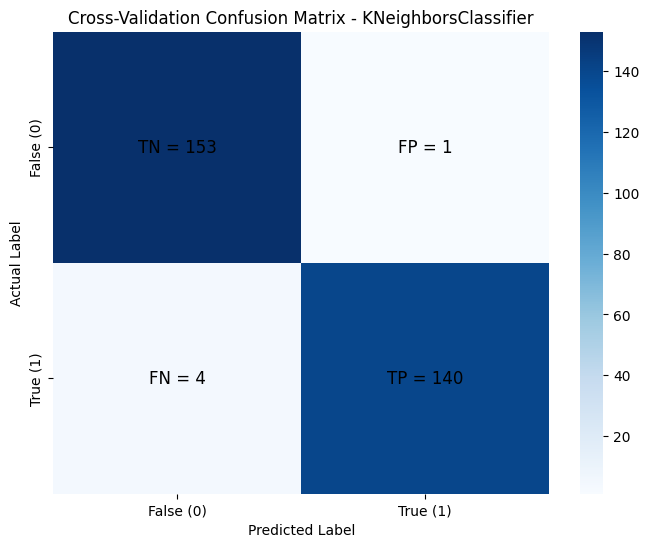

In [337]:
metrics_tuned_knn2 = eval_classification(model=knn2_tuned,
                                       X_train=X2_train,
                                       y_train=y2_train,
                                       X_test=X2_test,
                                       y_test=y2_test)

#### Decision Tree

Performance Metrics for DecisionTreeClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  94.18 ± 1.82
  Train: 97.07 ± 0.68

PRECISION:
  Test:  95.36 ± 2.86
  Train: 98.57 ± 1.00

RECALL:
  Test:  92.99 ± 2.62
  Train: 95.53 ± 1.04

F1:
  Test:  94.12 ± 1.84
  Train: 97.02 ± 0.69

ROC_AUC:
  Test:  95.43 ± 1.55
  Train: 99.23 ± 0.28

Single Run Metrics:

ACCURACY:
  Test:  96.31
  Train: 97.40

PRECISION:
  Test:  97.16
  Train: 99.10

RECALL:
  Test:  95.14
  Train: 95.68

F1:
  Test:  96.14
  Train: 97.36

ROC_AUC:
  Test:  97.29
  Train: 99.30


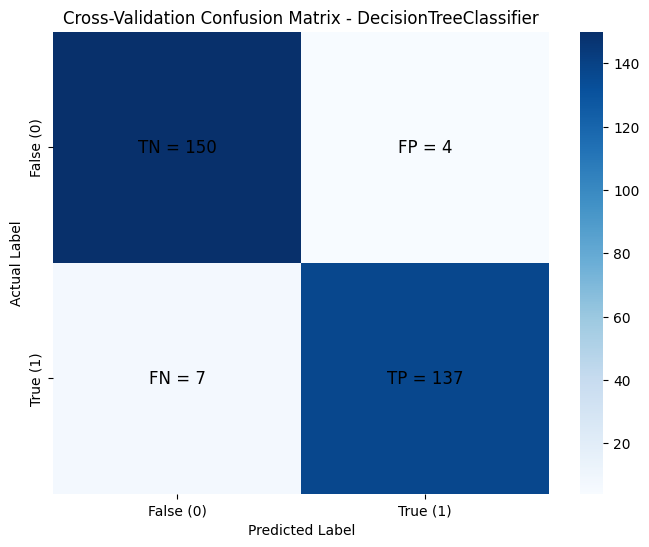

In [338]:
metrics_tuned_dt2 = eval_classification(model=dt2_tuned,
                                       X_train=X2_train,
                                       y_train=y2_train,
                                       X_test=X2_test,
                                       y_test=y2_test)

#### Random Forest

Performance Metrics for RandomForestClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  95.96 ± 1.66
  Train: 98.89 ± 0.23

PRECISION:
  Test:  96.56 ± 2.34
  Train: 99.73 ± 0.16

RECALL:
  Test:  95.39 ± 2.41
  Train: 98.05 ± 0.47

F1:
  Test:  95.94 ± 1.65
  Train: 98.89 ± 0.23

ROC_AUC:
  Test:  99.08 ± 0.45
  Train: 99.93 ± 0.03

Single Run Metrics:

ACCURACY:
  Test:  97.99
  Train: 98.99

PRECISION:
  Test:  97.92
  Train: 99.42

RECALL:
  Test:  97.92
  Train: 98.56

F1:
  Test:  97.92
  Train: 98.99

ROC_AUC:
  Test:  99.52
  Train: 99.92


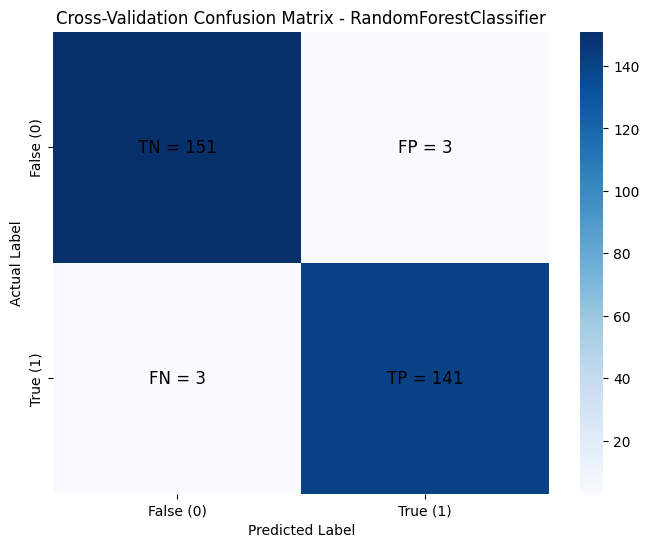

In [339]:
metrics_tuned_rf2 = eval_classification(model=rf2_tuned,
                                       X_train=X2_train,
                                       y_train=y2_train,
                                       X_test=X2_test,
                                       y_test=y2_test)

#### GradientBoost

Performance Metrics for GradientBoostingClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  95.82 ± 1.35
  Train: 98.93 ± 0.20

PRECISION:
  Test:  96.64 ± 2.30
  Train: 99.88 ± 0.17

RECALL:
  Test:  95.01 ± 1.95
  Train: 97.98 ± 0.43

F1:
  Test:  95.79 ± 1.34
  Train: 98.92 ± 0.21

ROC_AUC:
  Test:  98.99 ± 0.36
  Train: 99.98 ± 0.01

Single Run Metrics:

ACCURACY:
  Test:  96.98
  Train: 98.70

PRECISION:
  Test:  97.20
  Train: 99.71

RECALL:
  Test:  96.53
  Train: 97.69

F1:
  Test:  96.86
  Train: 98.69

ROC_AUC:
  Test:  99.03
  Train: 99.97


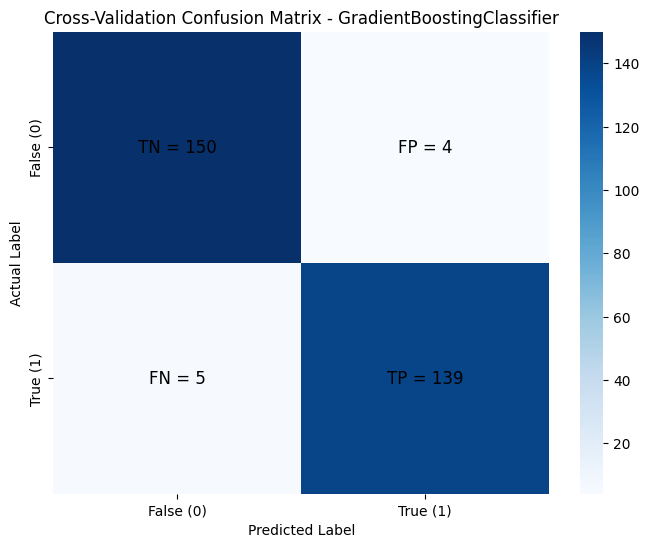

In [340]:
metrics_tuned_gb2 = eval_classification(model=gb2_tuned,
                                       X_train=X2_train,
                                       y_train=y2_train,
                                       X_test=X2_test,
                                       y_test=y2_test)

#### XGBoost

Performance Metrics for XGBClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  95.77 ± 1.48
  Train: 98.21 ± 0.23

PRECISION:
  Test:  96.11 ± 2.32
  Train: 99.44 ± 0.32

RECALL:
  Test:  95.49 ± 2.22
  Train: 96.97 ± 0.54

F1:
  Test:  95.77 ± 1.47
  Train: 98.19 ± 0.24

ROC_AUC:
  Test:  98.84 ± 0.64
  Train: 99.84 ± 0.04

Single Run Metrics:

ACCURACY:
  Test:  97.32
  Train: 97.84

PRECISION:
  Test:  97.22
  Train: 99.40

RECALL:
  Test:  97.22
  Train: 96.25

F1:
  Test:  97.22
  Train: 97.80

ROC_AUC:
  Test:  99.06
  Train: 99.77


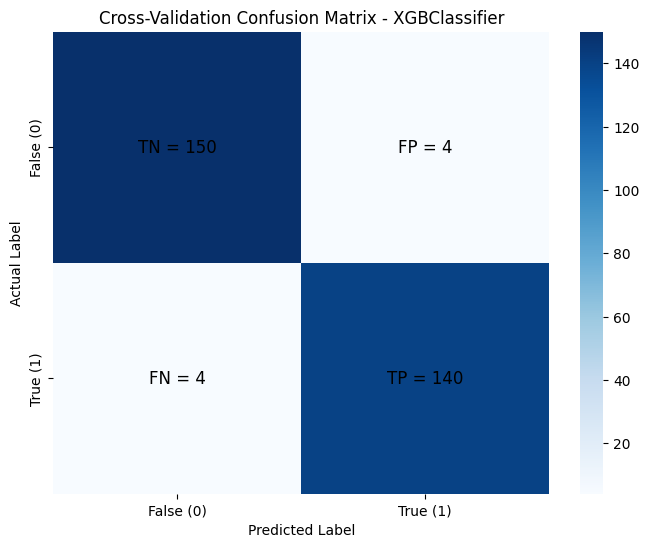

In [341]:
metrics_tuned_xgb2 = eval_classification(model=xgb2_tuned,
                                       X_train=X2_train,
                                       y_train=y2_train,
                                       X_test=X2_test,
                                       y_test=y2_test)

## **Model Comparison**

> In the beginning we knew that the target variable is balanced (50:50), so the main evaluation metric we will use is **Accuracy**. As for the secondary evaluation metric we will be using **Recall** because in business context we want to reduce the number of customers/users that is predicted not clicked on the ad while actually he/she wanted to clicked on the ad (False Negative).

### **Case 1 : Without Feature Scaling**

In [342]:
# Creating models dict
models1_dict = {}
models1_dict['Logistic Regression'] = lr1_tuned
models1_dict['K-Nearest Neighbors'] = knn1_tuned
models1_dict['Decision Tree'] = dt1_tuned
models1_dict['Random Forest'] = rf1_tuned
models1_dict['GradientBoost'] = gb1_tuned
models1_dict['XGBoost'] = xgb1_tuned

In [ ]:
# Create comparison for case 1: without scaling
grid_search_times1 = [lr1_time, knn1_time, dt1_time, rf1_time, gb1_time, xgb1_time] # grid search times
prediction_times1 = [] # fit-prediction times
accuracy_train_cv1 = [] # train cross-validated accuracy
accuracy_test_cv1 = [] # test cross-validated accuracy
recall_train_cv1 = [] # train cross-validated recall
recall_test_cv1 = [] # test cross-validated recall

for name, model in models1_dict.items():
    # Time the fit-prediction
    start = time.time()
    y_pred1 = model.predict(X1_test)
    y_pred_train1 = model.predict(X1_train)
    end = time.time()
    
    # Cross-validation with multiple metrics
    cv = RepeatedStratifiedKFold(random_state=42, n_repeats=5)
    scoring = {'accuracy': 'accuracy', 'recall': 'recall'}
    score = cross_validate(model, X1_train, y1_train, 
                          cv=cv, scoring=scoring, 
                          return_train_score=True)
    
    # Store results
    accuracy_train_cv1.append(score['train_accuracy'].mean())
    accuracy_test_cv1.append(score['test_accuracy'].mean())
    recall_train_cv1.append(score['train_recall'].mean())
    recall_test_cv1.append(score['test_recall'].mean())
    prediction_times1.append(end - start)
    
eval_dict1 = {
    'Model': models1_dict.keys(),
    'Accuracy (Test)': accuracy_test_cv1,
    'Accuracy (Train)': accuracy_train_cv1,
    'Recall (Test)': recall_test_cv1,
    'Recall (Train)': recall_train_cv1,
    'Prediction Times': prediction_times1,
    'Fit Times': grid_search_times1
}

# Create and format DataFrame
print('======== Case 1: Without Scaling ========')
print("Note: Accuracy and Recall are Cross-Validated")
eval_df1 = pd.DataFrame(data=eval_dict1)
eval_df1.style.format(precision=3)

======== Case 1: Without Scaling ========
Note: Accuracy and Recall are Cross-Validated


,Model,Accuracy (Test),Accuracy (Train),Recall (Test),Recall (Train),Prediction Times,Fit Times
0,Logistic Regression,0.943,0.947,0.920,0.925,0.003,74.150
1,K-Nearest Neighbors,0.719,0.730,0.636,0.647,0.019,52.940
2,Decision Tree,0.940,0.971,0.931,0.958,0.002,44.400
3,Random Forest,0.958,0.989,0.954,0.980,0.008,638.620
4,GradientBoost,0.958,0.990,0.950,0.980,0.003,197.480
5,XGBoost,0.955,0.982,0.953,0.970,0.003,1564.460


**Major Findings :**
- `Decision Tree` had the lowest fit time of all the models but the accuracy is second lowest accuracy overall.
- `XGBoost` had the highest cross validated accuracy but `Gradient Boosting` has the highest cross validated recall.
- Due to the non-scaled data, distance based algorithms like `K-Nearest Neighbours` suffered heavily as the accuracy and recall scores is the lowest of all models tested. Linear algorithms like `Logistic Regression` also suffered from this case.

### **Case 2 : With Feature Scaling**

In [344]:
# Creating models dict
models2_dict = {}
models2_dict['Logistic Regression'] = lr2_tuned
models2_dict['K-Nearest Neighbors'] = knn2_tuned
models2_dict['Decision Tree'] = dt2_tuned
models2_dict['Random Forest'] = rf2_tuned
models2_dict['GradientBoost'] = gb2_tuned
models2_dict['XGBoost'] = xgb2_tuned

In [345]:
# Create comparison for case 2: with scaling
grid_search_times2 = [lr2_time, knn2_time, dt2_time, rf2_time, gb2_time, xgb2_time] # grid search times
prediction_times2 = [] # fit-prediction times
accuracy_train_cv2 = [] # train cross-validated accuracy
accuracy_test_cv2 = [] # test cross-validated accuracy
recall_train_cv2 = [] # train cross-validated recall
recall_test_cv2 = [] # test cross-validated recall

for name, model in models1_dict.items():
    # Time the fit-prediction
    start = time.time()
    y_pred2 = model.predict(X2_test)
    y_pred_train2 = model.predict(X2_train)
    end = time.time()
    
    # Cross-validation with multiple metrics
    cv = RepeatedStratifiedKFold(random_state=42, n_repeats=5)
    scoring = {'accuracy': 'accuracy', 'recall': 'recall'}
    score = cross_validate(model, X2_train, y2_train, 
                          cv=cv, scoring=scoring, 
                          return_train_score=True)
    
    # Store results
    accuracy_train_cv2.append(score['train_accuracy'].mean())
    accuracy_test_cv2.append(score['test_accuracy'].mean())
    recall_train_cv2.append(score['train_recall'].mean())
    recall_test_cv2.append(score['test_recall'].mean())
    prediction_times2.append(end - start)
    
eval_dict2 = {
    'Model': models2_dict.keys(),
    'Accuracy (Test)': accuracy_test_cv2,
    'Accuracy (Train)': accuracy_train_cv2,
    'Recall (Test)': recall_test_cv2,
    'Recall (Train)': recall_train_cv2,
    'Prediction Times': prediction_times2,
    'Fit Times': grid_search_times2
}

# Create and format DataFrame
print('======== Case 2: With Scaling ========')
print("Note: Accuracy and Recall are Cross-Validated")
eval_df2 = pd.DataFrame(data=eval_dict2)
eval_df2.style.format(precision=3)

======== Case 2: With Scaling ========
Note: Accuracy and Recall are Cross-Validated


,Model,Accuracy (Test),Accuracy (Train),Recall (Test),Recall (Train),Prediction Times,Fit Times
0,Logistic Regression,0.963,0.968,0.949,0.953,0.003,22.760
1,K-Nearest Neighbors,0.950,0.951,0.906,0.909,0.021,88.830
2,Decision Tree,0.940,0.971,0.931,0.958,0.001,60.380
3,Random Forest,0.958,0.989,0.954,0.980,0.007,719.650
4,GradientBoost,0.957,0.990,0.950,0.980,0.001,171.100
5,XGBoost,0.955,0.982,0.953,0.970,0.003,1384.200


**Major Findings :**
- The overall fit time of all models decrease after scalling is applied, this is because it's now easier for the algorithm to do the calcuation.
- `Logistic Regression` had the highest cross validated accuracy, but `Gradient Boosting` has the highest cross validated recall.
- With normalized data, the previously poor performing distance based and linear models have shone through. The performance of `K-Nearest Neighbours` improved really significant while for the `Logistic Regression` not only the performance in accuracy and recall increased but also the fit time became much faster. 

### **Conclusion**

**By taking consideration of not only the above evaluation metrics but also the simplicity, explainability and fit and elapsed times, the model that will be chosen is the `Logistic Regression` model with normalization/standardization**

## Selected Model Analysis : Logistic Regression

### Confusion Matrix

Performance Metrics for LogisticRegression:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  96.35 ± 1.24
  Train: 96.91 ± 0.31

PRECISION:
  Test:  98.33 ± 1.18
  Train: 98.83 ± 0.23

RECALL:
  Test:  94.34 ± 2.69
  Train: 94.96 ± 0.60

F1:
  Test:  96.26 ± 1.31
  Train: 96.85 ± 0.33

ROC_AUC:
  Test:  99.01 ± 0.59
  Train: 99.11 ± 0.14

Single Run Metrics:

ACCURACY:
  Test:  97.65
  Train: 96.83

PRECISION:
  Test:  98.58
  Train: 98.51

RECALL:
  Test:  96.53
  Train: 95.10

F1:
  Test:  97.54
  Train: 96.77

ROC_AUC:
  Test:  99.30
  Train: 99.09


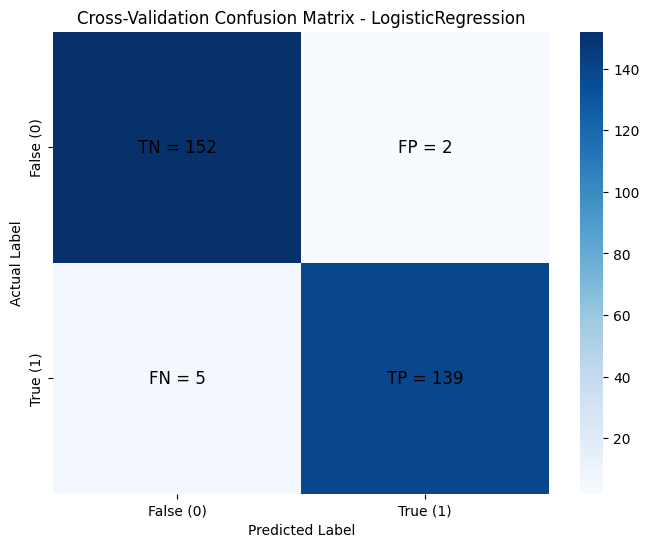

In [347]:
metrics_tuned_lr2 = eval_classification(model=lr2_tuned,
                                       X_train=X2_train,
                                       y_train=y2_train,
                                       X_test=X2_test,
                                       y_test=y2_test)

**Major Findings :**

From the test set confusion matrix above, from 144 people that clicked on an ad the algorithm correctly classified 139 of them and incorrectly classified 5 of them. Similarly, out of 154 people that did not click on an ad the algorithm correctly classified 152 of them and only incorrectly classified only 2.

### Feature Importances

#### Coefficient Analysis

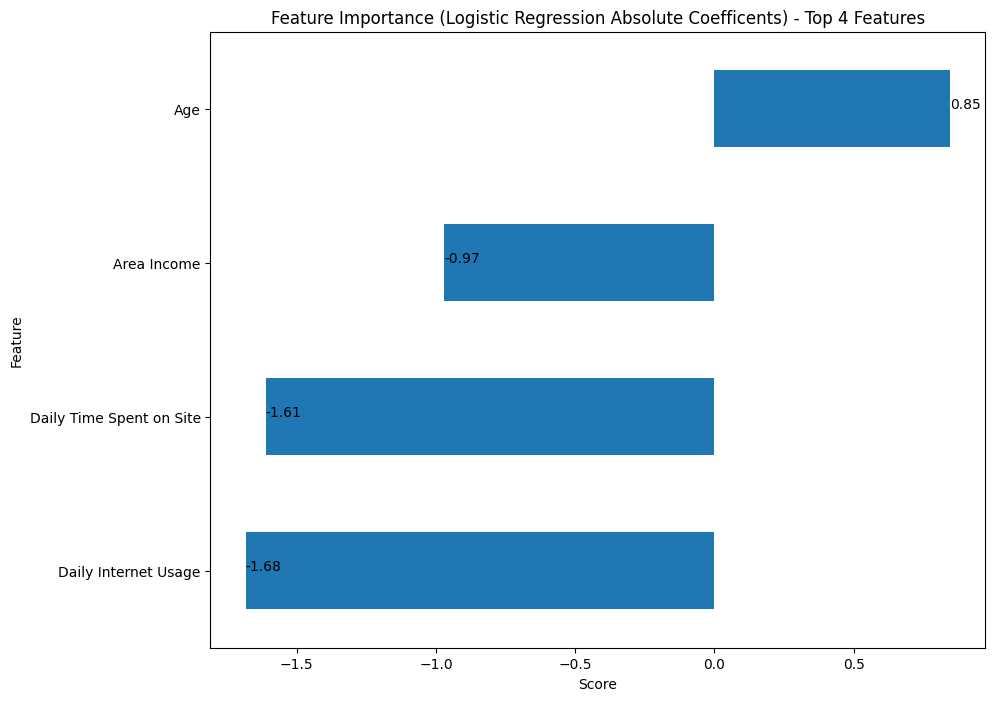

In [378]:
# Logistic regression feature importance
lg_features_importance = pd.DataFrame({'Feature': X1.columns, 'Coefficient': lr2_tuned.coef_[0]})
lg_features_importance['Abs_Coefficient'] = lg_features_importance['Coefficient'].abs()
lg_features_importance = lg_features_importance.sort_values(by='Abs_Coefficient', ascending=False).head(4)

# Plot the horizontal bar plot
ax = lg_features_importance.plot(x='Feature', y='Coefficient', kind='barh', figsize=(10, 8), legend=False)

# Add labels to each bar
for bar_position, bar_value in enumerate(lg_features_importance['Coefficient']):
    ax.text(bar_value, bar_position, f'{bar_value:.2f}')

# ax.bar_label(ax.containers[0], fmt='%.2f')

plt.title('Feature Importance (Logistic Regression Absolute Coefficents) - Top 4 Features')
plt.xlabel('Score')
plt.ylabel('Feature')
plt.show()

In the model generated using the logistic regression algorithm, the features contributing to the prediction results sorted from the most important are Daily Internet Usage, Daily Time Spent on Site, Area Income, and lastly Age. The interpreted coefficient gave us several info :

- The lower the `Daily Internet Usage`, `Daily Time Spent on Site`, and `Area Income`, the higher the chances that the customer will click on an ad and vice versa.
- The higher the `Age`, the bigger the odds that the customer will click on an ad and vice versa.

#### Shap Analysis

In [389]:
from sklearn.inspection import permutation_importance
import shap

# Function for model feature importance score based on calculation methods
def feature_importance(model, method='gini_importance'):
    # Method 1 : Gini Importance
    if method == 'gini_importance':
        gini_importance = model.feature_importances_
        gini_importance_df = pd.Series(gini_importance, index=X2_train.columns).nlargest(20)
        display(gini_importance_df)

        # Plotting method 1
        plt.figure(figsize=(10, 8))
        plt.barh(X2_train.columns, gini_importance_df.sort_values(ascending=False), color='skyblue')
        plt.xlabel('Gini Importance')
        plt.title('Feature Importance - Gini Importance')
        plt.gca().invert_yaxis()  # Invert y-axis for better visualization
        # plt.bar_label(bars)  # Add bar labels using the bars container
        plt.show()

    # Method 2 : Permutation Importance
    elif method == 'permutation_importance':
        perm_importance = permutation_importance(model, X2_test, y2_test, n_repeats=10, random_state=42)
        perm_importance_df = pd.Series(perm_importance.importances_mean, index=X2_train.columns).nlargest(20)
        display(perm_importance_df)

        # Plotting method 2
        plt.figure(figsize=(10, 8))
        plt.barh(perm_importance_df.index, perm_importance_df.sort_values(ascending=False), color='skyblue')
        plt.xlabel('Permutation Importance')
        plt.title('Feature Importance - Permutation Importance')
        plt.gca().invert_yaxis()  # Invert y-axis for better visualization
        # plt.bar_label(bars)  # Add bar labels using the bars container
        plt.show()

    # Method 3 : SHAP (SHapley Additive exPlanations) Values
    elif method == 'shap':
        # Determine the appropriate SHAP explainer based on the model type
        try:
            # Sampling background data to improve performance
            if X2_train.shape[0] > 1000:
                # Option 1: Random sampling
                background = shap.sample(X2_train, 100)
                
                # Option 2: K-means clustering sampling (alternative approach)
                # background = shap.kmeans(X_train, 100)
            else:
                background = X2_train

            # Check for tree-based models
            if hasattr(model, 'feature_importances_') or str(type(model)).lower().find('tree') != -1:
                explainer = shap.TreeExplainer(model)
                shap_values = explainer.shap_values(X2_test)
                
            # Check for linear models
            elif hasattr(model, 'coef_') or str(type(model)).lower().find('linear') != -1:
                explainer = shap.LinearExplainer(model, background)
                shap_values = explainer.shap_values(X2_test)
            
            # For KNN and other kernel-based models
            elif str(type(model)).lower().find('neighbors') != -1:
                # Use KernelExplainer with sampled background data
                explainer = shap.KernelExplainer(model.predict_proba, background)
                shap_values = explainer.shap_values(X2_test)
            
            # Fallback for other model types
            else:
                explainer = shap.KernelExplainer(model.predict_proba, background)
                shap_values = explainer.shap_values(X2_test)
            
            # Determine the correct SHAP values and expected value
            if isinstance(shap_values, list):
                # For multi-class, use the values for the positive class (typically index 1)
                shap_values_plot = shap_values[1]
                base_value = explainer.expected_value[1] if isinstance(explainer.expected_value, list) else explainer.expected_value
            else:
                # For binary classification with a single array
                shap_values_plot = shap_values
                base_value = explainer.expected_value

            # Summary plot (bar plot)
            plt.figure(figsize=(10, 8))
            shap.summary_plot(shap_values_plot, X2_test, plot_type='bar', show=False)
            plt.title('SHAP Feature Importance')
            plt.tight_layout()
            plt.show()
            plt.close()

            # Summary swarm plot
            plt.figure(figsize=(10, 8))
            shap.summary_plot(shap_values_plot, X2_test, show=False)
            plt.title('SHAP Summary Plot')
            plt.tight_layout()
            plt.show()
            plt.close()

            # Force plot for the first instance
            shap.force_plot(base_value, shap_values_plot[0], X2_test.iloc[0, :], matplotlib=True, show=False)
            plt.title('SHAP Force Plot (First Instance)')
            plt.tight_layout()
            plt.show()
            plt.close()
        
        except Exception as e:
            print(f"Error calculating SHAP values: {e}")
            print("SHAP calculation may not be supported for this model type.")

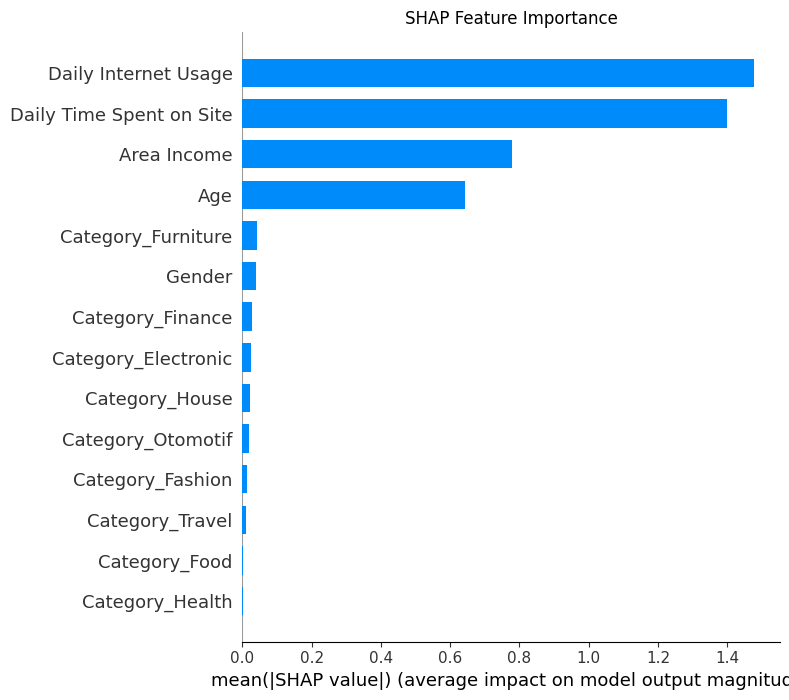

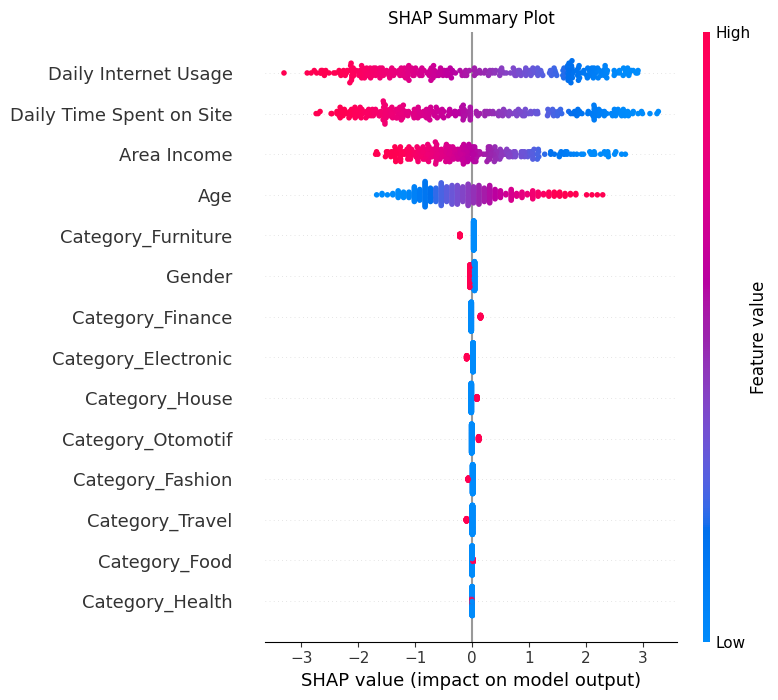

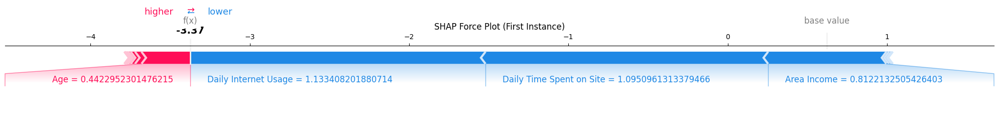

In [390]:
# Shap feature importance in logistic regression
feature_importance(lr2_tuned, method='shap')

##### SHAP Swarm Plot Interpretation:  
The more positive the x-axis (SHAP Value), the greater the feature's importance in influencing the model's predictions. This importance needs to be related to whether higher or lower values of the feature (on the y-axis) increase or decrease the predicted outcome. For example, smaller values of `Daily Internet Usage` are associated with a higher probability of clicking on advertisements. Similarly, the same applies to `Daily Time Spent on Site` and `Area Income`.

##### SHAP Force Plot Interpretation:  
The force plot illustrates the impact of individual feature values on the prediction. In this case, we focus on analyzing the positive class (`explainer.expected_value[1]`), meaning the interpretation aligns with the swarm plot. Features pushing the prediction higher (positive SHAP values) and those pushing it lower (negative SHAP values) are visualized in the context of their contribution to the outcome.

---

##### Additional Context on SHAP Interpretations:  
- **Swarm Plot:**  
  The SHAP swarm plot provides a global interpretation of the model, summarizing how different values of features impact the prediction across the dataset. Points on the right side of the plot (positive SHAP values) indicate a strong positive influence on the outcome, while those on the left (negative SHAP values) indicate a negative influence. The color gradient (usually red to blue) shows the feature value's magnitude and direction (high or low).

- **Force Plot:**  
  The SHAP force plot gives a local interpretation for a single prediction or a small subset. It visually breaks down the prediction by showing how each feature value contributes positively or negatively to the model's output relative to the baseline (`explainer.expected_value`). This allows you to trace the "forces" driving the prediction for a specific instance.

#### LIME (Local Interpretable Model-agnostic Explanations)

In [211]:
# Change the target column to categorical
change_target_dtype(df_model, target_type='categorical')


Analysis for Instance 0

Prediction: Not Clicked
Confidence: 96.69%

Feature Contributions:
- Daily Internet Usage > 0.88: decreases probability by 0.371
- Daily Time Spent on Site > 0.85: decreases probability by 0.331
- Area Income > 0.79: decreases probability by 0.207
- -0.12 < Age <= 0.67: increases probability by 0.052
- Category_House <= 0.00: decreases probability by 0.025
- Category_Travel <= 0.00: increases probability by 0.018
- Category_Fashion <= 0.00: increases probability by 0.018
- Category_Electronic <= 0.00: increases probability by 0.017
- Gender <= 0.00: increases probability by 0.012
- Category_Furniture <= 0.00: increases probability by 0.011
- Category_Otomotif <= 0.00: decreases probability by 0.009
- Category_Finance <= 0.00: decreases probability by 0.009
- Category_Health <= 0.00: increases probability by 0.006
- Category_Food > 0.00: increases probability by 0.001

Actual Values:
- Daily Time Spent on Site: 1.10
- Age: 0.44
- Area Income: 0.81
- Daily Inter

<Figure size 1000x600 with 0 Axes>

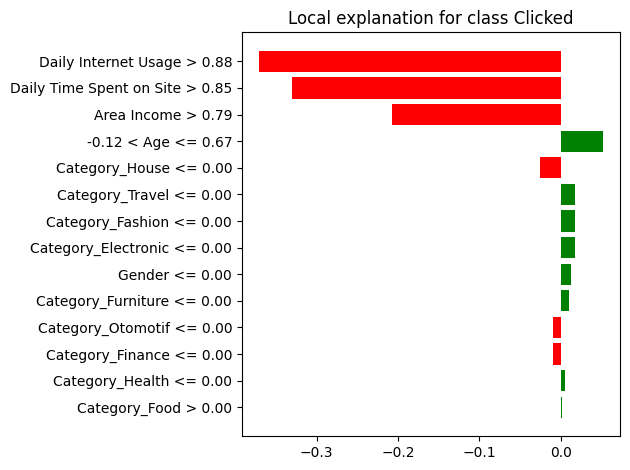

In [217]:
from lime import lime_tabular

class AdClickExplainer:
    def __init__(self, model, X_train, feature_names, categorical_features=None):
        """
        Initialize the LIME explainer for ad click predictions
        
        Parameters:
        model: Trained model with predict_proba method
        X_train: Training data used to train the model
        feature_names: List of feature names
        categorical_features: List of indices of categorical features (if any)
        """
        self.model = model
        self.feature_names = feature_names
        self.class_names = ['Not Clicked', 'Clicked']
        
        # Convert training data to numpy if it's pandas
        X_train_array = X_train.values if isinstance(X_train, pd.DataFrame) else np.array(X_train)
        
        # Initialize LIME explainer
        self.explainer = lime_tabular.LimeTabularExplainer(
            training_data=X_train_array,
            feature_names=feature_names,
            class_names=self.class_names,
            categorical_features=categorical_features,
            mode='classification',
            random_state=42  # for reproducibility
        )
    
    def explain_prediction(self, instance, num_features=None):
        """
        Explain a specific prediction using LIME
        
        Parameters:
        instance: Instance to explain (can be DataFrame row or array)
        num_features: Number of features to include in explanation (default: all)
        
        Returns:
        explanation: LIME explanation object
        """
        if num_features is None:
            num_features = len(self.feature_names)
            
        # Convert instance to numpy array if it's a pandas Series
        if isinstance(instance, pd.Series):
            instance = instance.to_numpy()
            
        # Get explanation
        try:
            explanation = self.explainer.explain_instance(
                data_row=instance,
                predict_fn=self.model.predict_proba,
                num_features=num_features,
                top_labels=2  # for binary classification
            )
            return explanation
        except Exception as e:
            print(f"Error generating explanation: {str(e)}")
            return None
    
    def analyze_prediction(self, instance, instance_id=None):
        """
        Analyze and display detailed prediction explanation
        
        Parameters:
        instance: Instance to analyze
        instance_id: Optional identifier for the instance
        
        Returns:
        tuple: (explanation object, prediction probability)
        """
        # Get explanation
        explanation = self.explain_prediction(instance)
        if explanation is None:
            return None, None
            
        # Convert instance to numpy array if it's a pandas Series
        if isinstance(instance, pd.Series):
            instance_array = instance.to_numpy().reshape(1, -1)
        else:
            instance_array = instance.reshape(1, -1)
            
        # Get prediction probability
        pred_proba = self.model.predict_proba(instance_array)[0]
        prediction = self.class_names[1] if pred_proba[1] > 0.5 else self.class_names[0]
        
        # Print analysis
        print(f"\n{'='*50}")
        if instance_id is not None:
            print(f"Analysis for Instance {instance_id}")
        print(f"{'='*50}")
        
        print(f"\nPrediction: {prediction}")
        print(f"Confidence: {max(pred_proba):.2%}")
        
        print("\nFeature Contributions:")
        feature_weights = explanation.as_list()
        for feature, weight in sorted(feature_weights, key=lambda x: abs(x[1]), reverse=True):
            direction = "increases" if weight > 0 else "decreases"
            print(f"- {feature}: {direction} probability by {abs(weight):.3f}")
        
        print("\nActual Values:")
        if isinstance(instance, pd.Series):
            for feature in self.feature_names:
                print(f"- {feature}: {instance[feature]:.2f}")
        else:
            for i, feature in enumerate(self.feature_names):
                print(f"- {feature}: {instance[i]:.2f}")
        
        return explanation, pred_proba
    
    def plot_explanation(self, explanation, save_path=None):
        """
        Plot and optionally save the LIME explanation
        
        Parameters:
        explanation: LIME explanation object
        save_path: Optional path to save the plot
        """
        plt.figure(figsize=(10, 6))
        explanation.as_pyplot_figure()
        plt.tight_layout()
        
        if save_path:
            plt.savefig(save_path, bbox_inches='tight', dpi=300)
            print(f"\nPlot saved to: {save_path}")
        
        plt.show()

# Class usage:
# Initialize explainer
explainer = AdClickExplainer(
    model=lr2_tuned,
    X_train=X2_train,
    feature_names=list(X2_test.columns)
)

# Analyze a specific instance
sample_idx = 0 # Change this to analyze a different instance (0 for Not Clicked, 1 for Clicked)
sample_instance = X2_test.iloc[sample_idx]
explanation, pred_proba = explainer.analyze_prediction(
    instance=sample_instance,
    instance_id=sample_idx
)

# Plot the explanation
explainer.plot_explanation(explanation)

##### Understanding LIME (Local Interpretable Model-agnostic Explanations)

##### What is LIME?
LIME is a technique that explains individual predictions of any machine learning model (the "model-agnostic" part) by approximating the model locally with a simpler, interpretable model. Think of it as "zooming in" on a particular prediction and understanding what happened in that specific case.

##### How LIME Works
1. **Local Approximation**: 
   - Takes a specific instance you want to explain
   - Creates similar samples around that instance by slightly varying the feature values
   - Weights these samples based on how close they are to the original instance
   - Fits a simple linear model to this local region

2. **Feature Perturbation**:
   - LIME randomly modifies feature values to create new samples
   - These modifications help understand how the model's predictions change when features change
   - The closer a sample is to the original instance, the more weight it gets in the explanation

##### Interpreting LIME Results

##### Feature Contributions
- **Positive Values**: Feature pushes prediction toward the predicted class
- **Negative Values**: Feature pushes prediction away from the predicted class
- **Magnitude**: Larger absolute values indicate stronger influence

Example interpretation:

- Feature: income > 50000
- Weight: 0.3
- Interpretation: Having income above 50000 increases the probability of loan approval by 0.3

##### LIME Plots
1. **Bar Charts**:
   - Bars extending right (positive): Support the predicted class
   - Bars extending left (negative): Oppose the predicted class
   - Length of bars: Strength of influence
   - Features are typically ordered by absolute importance

2. **Explanation Quality**:
   - R² score shows how well the local linear approximation fits
   - Higher R² means more reliable explanations

##### When to Use LIME

##### Good Use Cases:
- Explaining individual predictions to stakeholders
- Debugging model behavior on specific instances
- Building trust in model decisions
- Compliance requirements (e.g., "right to explanation")
- When global feature importance isn't enough

##### Limitations:
1. **Stability**:
   - Different runs might give slightly different explanations
   - Consider running multiple times for important decisions

2. **Computational Cost**:
   - Generating explanations takes time
   - Not suitable for real-time explanations of many predictions

3. **Local Validity**:
   - Explanations are only valid for similar instances
   - Don't extrapolate to very different cases

##### Best Practices:
1. **Feature Selection**:
   - Start with fewer features for clearer explanations
   - Gradually increase if needed for better understanding

2. **Sample Size**:
   - More samples generally give more stable explanations
   - Balance with computational constraints

3. **Kernel Width**:
   - Controls the size of the "local" region
   - Smaller width = more local, but potentially less stable

##### Example Interpretation

##### Example explanation output:
Prediction: Loan Approved (Probability: 85%)

Feature Contributions:
- credit_score > 750: +0.4
- income > 60000: +0.3
- debt_to_income < 0.2: +0.2
- age > 35: +0.1

This tells us:

1. Credit score was the strongest positive factor
2. High income was the second most important
3. Low debt-to-income ratio also supported approval
4. Age had a minor positive influence

Tips for Using LIME in Practice

1. Always validate explanations against domain knowledge
2. Use multiple techniques (e.g., SHAP + LIME) for important decisions
3. Consider the audience when presenting explanations
4. Document assumptions and limitations
5. Monitor explanation stability over time

Comparison with Other Methods

- SHAP: More theoretically grounded but slower
- Feature Importance: Simpler but only global insights
- Partial Dependence Plots: Better for understanding feature relationships
- Counterfactuals: More actionable but less comprehensive

# **Business Recommendation & Model Impact Simulation**

## Business Recommendation

Based on the insights that we got in EDA combining that with the feature importance from the logistic regression model, the following business recommendations are formulated :

- **Optimize Ad Placement for Active Internet Users**:<br>
Users who heavily utilize the internet are typically less responsive to ads which could be due to ad fatigue or a situation where they are exposed to a higher volume of ads. Over time, they may become tired or "fatigued" of seeing advertisements, leading to decreased responsiveness. To enhance ad performance, optimizing ad placement for users with lower internet usage or devising strategies to make ads more noticeable to this demographic, such as employing captivating visuals or distinctive offers, could be explored.

- **Site Content Personalization**:<br>
Now, the case is different from point 1, where the scope of analysis is that customer is now on our site. Given that users are more likely to click on ads when spending less time on our site, it becomes crucial to focus on content personalization and enhancing user engagement. Customizing content to maintain user interest without overwhelming them is key. This can involve strategies such as recommending relevant content and leveraging user data to tailor the user experience.

- **Age-Targeted Advertising**:<br>
Given the higher engagement levels observed among older demographics, it's strategic to refine our ad campaigns to resonate more effectively with this audience segment. This could involve crafting messaging and visuals that reflect the life experiences and preferences typical of older age groups. Additionally, leveraging insights from market research to identify products or services that align with the needs and aspirations of this demographic can enhance the effectiveness of our advertising efforts.

- **Income-Level Advertising**:<br>
Areas with lower income levels often exhibit higher ad click rates. Thus, creating ad campaigns with budget-friendly offerings that cater to individuals with lower incomes could be beneficial. Additionally, adjusting the ad messaging to emphasize cost-effective solutions may further enhance effectiveness.

## Business Simulation (Model Impact on Business)

In [150]:
df['Clicked on Ad'].value_counts()

Clicked on Ad
0    500
1    500
Name: count, dtype: int64

The initial condition (before model implementation) indicates that there are 50% of customers/users who do not click on the ads targeted to them. This is certainly disadvantageous for the company because it will increase the cost incurred by the company in displaying those ads on a platform. In this case, the total profit obtained by the company before and after model implementation will be calculated. Previously, several assumptions will be made such as:

Cost per Advertisement : Rp.6,000 <br>
Revenue per Ad clicked: Rp.15,000

*reference : 
- https://www.semrush.com/blog/google-ads-cost/
- https://www.businessofapps.com/ads/cpc/research/cpc-rates/ 

**Before model implementation:**

- **No. Users Advertised**:<br>
All User = 1000

- **Ad Click-Through Rate (CTR)**: <br>
500/1000 = 50%

- **Total Cost**: <br>
No. Users Advertised x Cost per Ad = 1000 x 6000 = Rp.6,000,000

- **Total Revenue**: <br>
Click-Through Rate x No. Users Advertised x Revenue per Ad Clicked = 0.5 x 1000 x 15000 = Rp.7,500,000

- **Total Profit**:<br>
Total Revenue - Total Cost = **Rp.1,500,000**

- **Return on Ad Spend**<br>
    ROAS = Total Revenue / Total Cost = Rp.7,500,000 / Rp.6,000,000 = **1.25**

>    This means that for every Rp.1 spent on ads, the revenue generated was Rp.1.25.

**After model implementation:**

- **No. Users Advertised**:<br>
Accuracy x All original user = 0.973 x 1,000 = 973

- **Ad Click-Through Rate (CTR)**:<br>
(Precision x 1000)/No. Users Advertised = 0.972 x 1000 / 973 = 99.8%

- **Total Cost**:<br>
No. Users Advertised x Cost per Ad = 1000 x 6000 = Rp.6,000,000

- **Total Revenue**:<br>
Click-Through Rate x No. Users Advertised x Revenue per Ad Clicked = 0.998 x 973 x 15000 = Rp.14,565,810

- **Total Profit**:<br>
Total Revenue - Total Cost = **Rp.8,727,810**

- **Return on Ad Spend**<br>
    ROAS = Total Revenue / Total Cost = Rp.14,565,810 / Rp.6,000,000 = **2.43**

>    This means that for every Rp.1 spent on ads, the revenue generated was Rp.2.43

**Conclusion:**

> By comparing the profits and click rates of before and after model implementation, we can see that with the tuned logistic regression model (accuracy of 97.3%) implementation Click-Through Rate (CTR) is up from **50%** to **99.8%**, and similarly profit is up from **Rp.1,500,000** to **Rp.8,727,810** (a **581.8%** increase), with increase of Return on Ad Spend (ROAS) from 1.25 to 2.43 (in IDR).

# Model Deployment

## Save Model

In [ ]:
# Save the model using joblib
import joblib
joblib.dump(lr2_tuned, 'tuned_logistic_regression_model.joblib')

# # Save the model using pickle
# with open('tuned_logistic_regression_model.pkl', 'wb') as file:
#     pickle.dump(lr2_tuned, file)

['tuned_logistic_regression_model.joblib']

## Testing Single Prediction with Saved Model

In [142]:
df['Daily Internet Usage'].describe()

count    1000.000000
mean      179.863620
std        43.627946
min       104.780000
25%       139.017500
50%       181.065000
75%       218.287500
max       267.010000
Name: Daily Internet Usage, dtype: float64

In [143]:
# Take a random sample row from X2_train
sample_input = X2_train.sample(n=1, random_state=42).copy()

# Modify the values to simulate a new input
sample_input = pd.DataFrame({
    'Daily Time Spent on Site': [40.0],
    'Age': [30],
    'Area Income': [3.850493e+08],
    'Daily Internet Usage': [185.0],
    'Gender': [1]
})

# Add one-hot encoded category columns 
for category in df['Category'].unique().tolist():
    sample_input[f'Category_{category}'] = 0

# Match the category result with the original data
sample_input = sample_input.drop(columns=['Category_Bank'])

# Set the chosen category to 1
sample_input['Category_Health'] = 1

# Re-order the columns to match the model input
sample_input = sample_input[X2_train.columns]

print("Sample input for prediction:")
display(sample_input)

Sample input for prediction:


,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Gender,Category_Electronic,Category_Fashion,Category_Finance,Category_Food,Category_Furniture,Category_Health,Category_House,Category_Otomotif,Category_Travel
0,40.0,30,385049300.0,185.0,1,0,0,0,0,0,1,0,0,0


In [144]:
# Load the model
loaded_model = joblib.load('./models/tuned_logistic_regression_model.joblib')

# Make prediction
prediction = loaded_model.predict(sample_input)
prediction_proba = loaded_model.predict_proba(sample_input)

print(f"Prediction: {'Will click' if prediction[0] == 1 else 'Will not click'}")
print(f"Probabilities for both classes: {prediction_proba[0]}")
print(f"Probability: {prediction_proba[0][0]:.2%}")

Prediction: Will not click
Probabilities for both classes: [1. 0.]
Probability: 100.00%


In [145]:
# Check the prediction for all models
for tuned_model in [lr2_tuned, knn2_tuned, dt2_tuned, rf2_tuned, gb2_tuned, xgb2_tuned]:
    prediction = tuned_model.predict(sample_input)
    prediction_proba = tuned_model.predict_proba(sample_input)

    print(f"Model: {tuned_model.__class__.__name__}")
    print(f"Prediction: {'Will click' if prediction[0] == 1 else 'Will not click'}")
    print(f"Probabilities for both classes: {prediction_proba[0]}")
    print(f"Probability: {prediction_proba[0][0]:.2%}")
    print()

Model: LogisticRegression
Prediction: Will not click
Probabilities for both classes: [1. 0.]
Probability: 100.00%

Model: KNeighborsClassifier
Prediction: Will not click
Probabilities for both classes: [0.83333333 0.16666667]
Probability: 83.33%

Model: DecisionTreeClassifier
Prediction: Will click
Probabilities for both classes: [0. 1.]
Probability: 0.00%

Model: RandomForestClassifier
Prediction: Will not click
Probabilities for both classes: [0.66690659 0.33309341]
Probability: 66.69%

Model: GradientBoostingClassifier
Prediction: Will not click
Probabilities for both classes: [0.78849116 0.21150884]
Probability: 78.85%

Model: XGBClassifier
Prediction: Will not click
Probabilities for both classes: [0.983646   0.01635403]
Probability: 98.36%



> Most of the model will predict the sample input as `Not Clicked`